In [1]:
import os
import cv2
import torch
import numpy as np
import pandas as pd

from torch.utils.data import Dataset, DataLoader

In [2]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [3]:
import os

MODEL_FOLDER = "/kaggle/input/datasets/kaviyam23adr085/leukumiaaaaa/best_vit_model"

print("=" * 80)
print("CHECKING ViT MODEL")
print("=" * 80)

print("Path   :", MODEL_FOLDER)
print("Exists :", os.path.exists(MODEL_FOLDER))

for root, dirs, files in os.walk(MODEL_FOLDER):
    print("\nFolder:", root)

    for f in files[:10]:
        print("  FILE:", f)

CHECKING ViT MODEL
Path   : /kaggle/input/datasets/kaviyam23adr085/leukumiaaaaa/best_vit_model
Exists : True

Folder: /kaggle/input/datasets/kaviyam23adr085/leukumiaaaaa/best_vit_model

Folder: /kaggle/input/datasets/kaviyam23adr085/leukumiaaaaa/best_vit_model/best_vit_model
  FILE: .format_version
  FILE: .storage_alignment
  FILE: data.pkl
  FILE: version
  FILE: byteorder

Folder: /kaggle/input/datasets/kaviyam23adr085/leukumiaaaaa/best_vit_model/best_vit_model/.data
  FILE: serialization_id

Folder: /kaggle/input/datasets/kaviyam23adr085/leukumiaaaaa/best_vit_model/best_vit_model/data
  FILE: 7
  FILE: 135
  FILE: 47
  FILE: 183
  FILE: 17
  FILE: 81
  FILE: 19
  FILE: 199
  FILE: 121
  FILE: 192


In [4]:
# =============================================================================
# CORRECTLY RECONSTRUCT PyTorch CHECKPOINT
# =============================================================================

import os
import zipfile

MODEL_FOLDER = "/kaggle/input/datasets/kaviyam23adr085/leukumiaaaaa/best_vit_model"

CHECKPOINT_FOLDER = os.path.join(
    MODEL_FOLDER,
    "best_vit_model"
)

OUTPUT_PTH = "/kaggle/working/best_vit_model_reconstructed.pth"

print("=" * 80)
print("CORRECTING ViT CHECKPOINT")
print("=" * 80)

print("Source folder :", CHECKPOINT_FOLDER)
print("Output file   :", OUTPUT_PTH)

# Remove wrong reconstructed file
if os.path.exists(OUTPUT_PTH):
    os.remove(OUTPUT_PTH)
    print("\nOld reconstructed file removed.")

# -------------------------------------------------------------------------
# IMPORTANT:
# PyTorch expects files inside a common root directory.
# -------------------------------------------------------------------------

with zipfile.ZipFile(
    OUTPUT_PTH,
    mode="w",
    compression=zipfile.ZIP_STORED
) as z:

    for root, dirs, files in os.walk(CHECKPOINT_FOLDER):

        for file in files:

            full_path = os.path.join(root, file)

            relative_path = os.path.relpath(
                full_path,
                CHECKPOINT_FOLDER
            )

            # Put everything inside a top-level folder
            archive_path = os.path.join(
                "best_vit_model",
                relative_path
            )

            z.write(
                full_path,
                archive_path
            )

print("\n✅ Checkpoint reconstructed correctly")

print(
    "File size:",
    round(
        os.path.getsize(OUTPUT_PTH) / (1024 * 1024),
        2
    ),
    "MB"
)

print("=" * 80)

CORRECTING ViT CHECKPOINT
Source folder : /kaggle/input/datasets/kaviyam23adr085/leukumiaaaaa/best_vit_model/best_vit_model
Output file   : /kaggle/working/best_vit_model_reconstructed.pth

✅ Checkpoint reconstructed correctly
File size: 331.63 MB


In [5]:
# =============================================================================
# VERIFY CORRECTED CHECKPOINT
# =============================================================================

import torch
import os

CHECKPOINT_PATH = "/kaggle/working/best_vit_model_reconstructed.pth"

print("=" * 80)
print("VERIFYING CORRECTED CHECKPOINT")
print("=" * 80)

print("Path   :", CHECKPOINT_PATH)
print("Exists :", os.path.exists(CHECKPOINT_PATH))

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

print("\nCheckpoint type :", type(checkpoint))

print("Number of keys  :", len(checkpoint))

print("\nFirst 10 keys:")

for key in list(checkpoint.keys())[:10]:
    print(" ", key)

print("\n" + "=" * 80)
print("✅ CHECKPOINT LOADED SUCCESSFULLY")
print("=" * 80)

VERIFYING CORRECTED CHECKPOINT
Path   : /kaggle/working/best_vit_model_reconstructed.pth
Exists : True

Checkpoint type : <class 'collections.OrderedDict'>
Number of keys  : 216

First 10 keys:
  backbone.embeddings.cls_token
  backbone.embeddings.position_embeddings
  backbone.embeddings.patch_embeddings.projection.weight
  backbone.embeddings.patch_embeddings.projection.bias
  backbone.encoder.layer.0.attention.attention.query.weight
  backbone.encoder.layer.0.attention.attention.query.bias
  backbone.encoder.layer.0.attention.attention.key.weight
  backbone.encoder.layer.0.attention.attention.key.bias
  backbone.encoder.layer.0.attention.attention.value.weight
  backbone.encoder.layer.0.attention.attention.value.bias

✅ CHECKPOINT LOADED SUCCESSFULLY


In [6]:
# =============================================================================
# STEP 1 — LOAD TRAINED ViT
# =============================================================================

import torch
import torch.nn as nn
import numpy as np
import os

from transformers import ViTModel

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 80)
print("LOADING TRAINED ViT")
print("=" * 80)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


# -------------------------------------------------------------------------
# ExplainableViT architecture
# IMPORTANT: This architecture must match the checkpoint
# -------------------------------------------------------------------------

class ExplainableViT(nn.Module):

    def __init__(self, num_classes=2):

        super().__init__()

        self.backbone = ViTModel.from_pretrained(
            "google/vit-base-patch16-224"
        )

        hidden_size = self.backbone.config.hidden_size

        self.classifier = nn.Sequential(

            nn.Linear(hidden_size, 512),

            nn.BatchNorm1d(512),

            nn.ReLU(),

            nn.Dropout(0.30),

            nn.Linear(512, 256),

            nn.BatchNorm1d(256),

            nn.ReLU(),

            nn.Dropout(0.20),

            nn.Linear(256, num_classes)
        )


    def forward(self, pixel_values):

        outputs = self.backbone(
            pixel_values=pixel_values
        )

        cls_features = outputs.last_hidden_state[:, 0]

        logits = self.classifier(
            cls_features
        )

        return logits


model = ExplainableViT(
    num_classes=2
)

# -------------------------------------------------------------------------
# Load our reconstructed trained checkpoint
# -------------------------------------------------------------------------

CHECKPOINT_PATH = (
    "/kaggle/working/"
    "best_vit_model_reconstructed.pth"
)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

missing_keys, unexpected_keys = model.load_state_dict(
    checkpoint,
    strict=False
)

print("\nMissing keys    :", len(missing_keys))
print("Unexpected keys :", len(unexpected_keys))

if len(missing_keys) == 0 and len(unexpected_keys) == 0:

    print("\n✅ ALL TRAINED ViT WEIGHTS LOADED")

else:

    print("\n⚠️ Checkpoint mismatch")
    print("Missing:", missing_keys)
    print("Unexpected:", unexpected_keys)

model = model.to(device)

model.eval()

print("\n✅ ViT model ready")

LOADING TRAINED ViT
Device: cuda
GPU: Tesla T4


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

ViTModel LOAD REPORT from: google/vit-base-patch16-224
Key                 | Status     | 
--------------------+------------+-
classifier.bias     | UNEXPECTED | 
classifier.weight   | UNEXPECTED | 
pooler.dense.weight | MISSING    | 
pooler.dense.bias   | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



Missing keys    : 0
Unexpected keys : 0

✅ ALL TRAINED ViT WEIGHTS LOADED

✅ ViT model ready


In [7]:
# =============================================================================
# STEP 2 — CHECK ORIGINAL DATASET
# =============================================================================

DATASET_PATH = (
    "/kaggle/input/datasets/"
    "kaviyam23adr085/leukumiaaaaa/"
    "cnmc/C-NMC_Leukemia"
)

TRAINING_PATH = os.path.join(
    DATASET_PATH,
    "training_data"
)

print("=" * 80)
print("CHECKING ORIGINAL DATASET")
print("=" * 80)

print("Dataset :", DATASET_PATH)
print("Exists  :", os.path.exists(DATASET_PATH))

print("\nTraining:", TRAINING_PATH)
print("Exists  :", os.path.exists(TRAINING_PATH))

print("\nContents:")

for item in os.listdir(TRAINING_PATH):

    path = os.path.join(
        TRAINING_PATH,
        item
    )

    print(
        item,
        "->",
        "DIR" if os.path.isdir(path) else "FILE"
    )

CHECKING ORIGINAL DATASET
Dataset : /kaggle/input/datasets/kaviyam23adr085/leukumiaaaaa/cnmc/C-NMC_Leukemia
Exists  : True

Training: /kaggle/input/datasets/kaviyam23adr085/leukumiaaaaa/cnmc/C-NMC_Leukemia/training_data
Exists  : True

Contents:
fold_0 -> DIR
fold_1 -> DIR
fold_2 -> DIR


In [8]:
# =============================================================================
# STEP 3A — INSPECT C-NMC FOLDER STRUCTURE
# =============================================================================

import os

TRAINING_PATH = (
    "/kaggle/input/datasets/"
    "kaviyam23adr085/leukumiaaaaa/"
    "cnmc/C-NMC_Leukemia/"
    "training_data"
)

print("=" * 80)
print("C-NMC FOLDER STRUCTURE")
print("=" * 80)

for fold in ["fold_0", "fold_1", "fold_2"]:

    fold_path = os.path.join(
        TRAINING_PATH,
        fold
    )

    print("\n" + "=" * 60)
    print("FOLDER:", fold)
    print("=" * 60)

    for item in os.listdir(fold_path):

        item_path = os.path.join(
            fold_path,
            item
        )

        if os.path.isdir(item_path):

            print(
                "DIR :",
                item
            )

        else:

            print(
                "FILE:",
                item
            )

C-NMC FOLDER STRUCTURE

FOLDER: fold_0
DIR : all
DIR : hem

FOLDER: fold_1
DIR : all
DIR : hem

FOLDER: fold_2
DIR : all
DIR : hem


In [9]:
# =============================================================================
# STEP 4A — INSPECT ACTUAL IMAGE FILES
# =============================================================================

import os

TRAINING_PATH = (
    "/kaggle/input/datasets/"
    "kaviyam23adr085/leukumiaaaaa/"
    "cnmc/C-NMC_Leukemia/"
    "training_data"
)

print("=" * 80)
print("INSPECTING ACTUAL C-NMC FILES")
print("=" * 80)

total_files = 0

for fold in ["fold_0", "fold_1", "fold_2"]:

    fold_path = os.path.join(TRAINING_PATH, fold)

    print(f"\n{'='*60}")
    print(f"{fold}")
    print(f"{'='*60}")

    for class_name in ["all", "hem"]:

        class_path = os.path.join(
            fold_path,
            class_name
        )

        print(f"\n{class_name} folder:")
        print("Path:", class_path)
        print("Exists:", os.path.exists(class_path))

        count = 0

        for root, dirs, files in os.walk(class_path):

            for file in files:

                count += 1
                total_files += 1

                # Show first 10 files
                if count <= 10:
                    print(" ", file)

        print("Files found:", count)

print("\n" + "=" * 80)
print("TOTAL FILES FOUND:", total_files)
print("=" * 80)

INSPECTING ACTUAL C-NMC FILES

fold_0

all folder:
Path: /kaggle/input/datasets/kaviyam23adr085/leukumiaaaaa/cnmc/C-NMC_Leukemia/training_data/fold_0/all
Exists: True
  UID_28_5_3_all.bmp
  UID_45_24_5_all.bmp
  UID_45_7_1_all.bmp
  UID_52_10_5_all.bmp
  UID_52_21_7_all.bmp
  UID_50_17_2_all.bmp
  UID_14_19_3_all.bmp
  UID_50_4_9_all.bmp
  UID_52_18_14_all.bmp
  UID_4_5_2_all.bmp
Files found: 2397

hem folder:
Path: /kaggle/input/datasets/kaviyam23adr085/leukumiaaaaa/cnmc/C-NMC_Leukemia/training_data/fold_0/hem
Exists: True
  UID_H12_18_4_hem.bmp
  UID_H17_3_2_hem.bmp
  UID_H17_15_4_hem.bmp
  UID_H24_24_4_hem.bmp
  UID_H24_36_4_hem.bmp
  UID_H12_11_1_hem.bmp
  UID_H24_2_1_hem.bmp
  UID_H24_1_9_hem.bmp
  UID_H19_34_2_hem.bmp
  UID_H24_31_9_hem.bmp
Files found: 1130

fold_1

all folder:
Path: /kaggle/input/datasets/kaviyam23adr085/leukumiaaaaa/cnmc/C-NMC_Leukemia/training_data/fold_1/all
Exists: True
  UID_46_17_8_all.bmp
  UID_32_21_5_all.bmp
  UID_44_22_3_all.bmp
  UID_34_5_2_all.bmp
 

In [10]:
# =============================================================================
# STEP 4A — INSPECT ACTUAL C-NMC IMAGE FILES
# =============================================================================

import os

TRAINING_PATH = (
    "/kaggle/input/datasets/"
    "kaviyam23adr085/leukumiaaaaa/"
    "cnmc/C-NMC_Leukemia/"
    "training_data"
)

print("=" * 80)
print("INSPECTING ACTUAL C-NMC FILES")
print("=" * 80)

total_files = 0

for fold in ["fold_0", "fold_1", "fold_2"]:

    fold_path = os.path.join(
        TRAINING_PATH,
        fold
    )

    print("\n" + "=" * 60)
    print("FOLDER:", fold)
    print("=" * 60)

    for class_name in ["all", "hem"]:

        class_path = os.path.join(
            fold_path,
            class_name
        )

        print("\n" + class_name.upper(), "folder")
        print("Path   :", class_path)
        print("Exists :", os.path.exists(class_path))

        count = 0

        for root, dirs, files in os.walk(class_path):

            for file in files:

                count += 1
                total_files += 1

                # Show first 10 actual files
                if count <= 10:
                    print("   ", file)

        print("Files found:", count)

print("\n" + "=" * 80)
print("TOTAL FILES FOUND:", total_files)
print("=" * 80)

INSPECTING ACTUAL C-NMC FILES

FOLDER: fold_0

ALL folder
Path   : /kaggle/input/datasets/kaviyam23adr085/leukumiaaaaa/cnmc/C-NMC_Leukemia/training_data/fold_0/all
Exists : True
    UID_28_5_3_all.bmp
    UID_45_24_5_all.bmp
    UID_45_7_1_all.bmp
    UID_52_10_5_all.bmp
    UID_52_21_7_all.bmp
    UID_50_17_2_all.bmp
    UID_14_19_3_all.bmp
    UID_50_4_9_all.bmp
    UID_52_18_14_all.bmp
    UID_4_5_2_all.bmp
Files found: 2397

HEM folder
Path   : /kaggle/input/datasets/kaviyam23adr085/leukumiaaaaa/cnmc/C-NMC_Leukemia/training_data/fold_0/hem
Exists : True
    UID_H12_18_4_hem.bmp
    UID_H17_3_2_hem.bmp
    UID_H17_15_4_hem.bmp
    UID_H24_24_4_hem.bmp
    UID_H24_36_4_hem.bmp
    UID_H12_11_1_hem.bmp
    UID_H24_2_1_hem.bmp
    UID_H24_1_9_hem.bmp
    UID_H19_34_2_hem.bmp
    UID_H24_31_9_hem.bmp
Files found: 1130

FOLDER: fold_1

ALL folder
Path   : /kaggle/input/datasets/kaviyam23adr085/leukumiaaaaa/cnmc/C-NMC_Leukemia/training_data/fold_1/all
Exists : True
    UID_46_17_8_all.bmp

In [11]:
# =============================================================================
# STEP 4 — CREATE C-NMC IMAGE DATAFRAME
# =============================================================================

import os
import pandas as pd

TRAINING_PATH = (
    "/kaggle/input/datasets/"
    "kaviyam23adr085/leukumiaaaaa/"
    "cnmc/C-NMC_Leukemia/"
    "training_data"
)

records = []

for fold in ["fold_0", "fold_1", "fold_2"]:

    # =========================================================
    # ALL
    # =========================================================

    all_path = os.path.join(
        TRAINING_PATH,
        fold,
        "all"
    )

    for root, dirs, files in os.walk(all_path):

        for file in files:

            if file.lower().endswith(".bmp"):

                records.append({
                    "image_path": os.path.join(root, file),
                    "label": 1,
                    "class_name": "ALL",
                    "fold": fold
                })

    # =========================================================
    # HEM
    # =========================================================

    hem_path = os.path.join(
        TRAINING_PATH,
        fold,
        "hem"
    )

    for root, dirs, files in os.walk(hem_path):

        for file in files:

            if file.lower().endswith(".bmp"):

                records.append({
                    "image_path": os.path.join(root, file),
                    "label": 0,
                    "class_name": "HEM",
                    "fold": fold
                })


# Create dataframe
image_df = pd.DataFrame(records)

print("=" * 80)
print("C-NMC IMAGE DATAFRAME")
print("=" * 80)

print("Total images :", len(image_df))

print("\nClass distribution:")
print(
    image_df["class_name"].value_counts()
)

print("\nLabel distribution:")
print(
    image_df["label"].value_counts()
)

print("\nFold distribution:")
print(
    image_df["fold"].value_counts()
)

print("\nFirst 5 records:")
print(
    image_df.head()
)

print("=" * 80)

C-NMC IMAGE DATAFRAME
Total images : 10661

Class distribution:
class_name
ALL    7272
HEM    3389
Name: count, dtype: int64

Label distribution:
label
1    7272
0    3389
Name: count, dtype: int64

Fold distribution:
fold
fold_1    3581
fold_2    3553
fold_0    3527
Name: count, dtype: int64

First 5 records:
                                          image_path  label class_name    fold
0  /kaggle/input/datasets/kaviyam23adr085/leukumi...      1        ALL  fold_0
1  /kaggle/input/datasets/kaviyam23adr085/leukumi...      1        ALL  fold_0
2  /kaggle/input/datasets/kaviyam23adr085/leukumi...      1        ALL  fold_0
3  /kaggle/input/datasets/kaviyam23adr085/leukumi...      1        ALL  fold_0
4  /kaggle/input/datasets/kaviyam23adr085/leukumi...      1        ALL  fold_0


In [12]:
# =============================================================================
# STEP 5 — TRAIN / VALIDATION SPLIT
# =============================================================================

from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(
    image_df,
    test_size=0.10,
    random_state=42,
    stratify=image_df["label"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print("=" * 80)
print("TRAIN / VALIDATION SPLIT")
print("=" * 80)

print("Total      :", len(image_df))
print("Train      :", len(train_df))
print("Validation :", len(val_df))

print("\nTrain Classes:")
print(
    train_df["label"].value_counts()
)

print("\nValidation Classes:")
print(
    val_df["label"].value_counts()
)

print("=" * 80)

TRAIN / VALIDATION SPLIT
Total      : 10661
Train      : 9594
Validation : 1067

Train Classes:
label
1    6544
0    3050
Name: count, dtype: int64

Validation Classes:
label
1    728
0    339
Name: count, dtype: int64


In [13]:
# =============================================================================
# STEP 6 — CREATE ViT DATASET AND DATALOADERS
# =============================================================================

import cv2
import torch
import numpy as np

from torch.utils.data import Dataset, DataLoader
from transformers import AutoImageProcessor

print("=" * 80)
print("CREATING ViT DATASET")
print("=" * 80)

# ViT image processor
image_processor = AutoImageProcessor.from_pretrained(
    "google/vit-base-patch16-224"
)


class LeukemiaViTDataset(Dataset):

    def __init__(self, dataframe):

        self.dataframe = dataframe.reset_index(drop=True)

    def __len__(self):

        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        image_path = row["image_path"]
        label = int(row["label"])

        # ---------------------------------------------------------
        # Read C-NMC BMP image
        # ---------------------------------------------------------

        image = cv2.imread(
            image_path,
            cv2.IMREAD_COLOR
        )

        if image is None:
            raise ValueError(
                f"Could not read image: {image_path}"
            )

        # OpenCV BGR → RGB
        image = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )

        # ---------------------------------------------------------
        # ViT preprocessing
        # ---------------------------------------------------------

        encoded = image_processor(
            images=image,
            return_tensors="pt"
        )

        pixel_values = encoded[
            "pixel_values"
        ].squeeze(0)

        return pixel_values, label


# Create datasets
train_dataset = LeukemiaViTDataset(
    train_df
)

val_dataset = LeukemiaViTDataset(
    val_df
)


# ---------------------------------------------------------
# DataLoaders
# ---------------------------------------------------------

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)


print("Train images      :", len(train_dataset))
print("Validation images :", len(val_dataset))

print("Train batches     :", len(train_loader))
print("Validation batches:", len(val_loader))

print("=" * 80)
print("✅ DATASET & DATALOADER READY")
print("=" * 80)

CREATING ViT DATASET


preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

Fast image processor class <class 'transformers.models.vit.image_processing_vit_fast.ViTImageProcessorFast'> is available for this model. Using slow image processor class. To use the fast image processor class set `use_fast=True`.


Train images      : 9594
Validation images : 1067
Train batches     : 300
Validation batches: 34
✅ DATASET & DATALOADER READY


In [14]:
# =============================================================================
# STEP 7 — EXTRACT 768-D ViT FEATURES
# =============================================================================

import torch
import numpy as np
from tqdm.auto import tqdm

print("=" * 80)
print("EXTRACTING ViT FEATURES")
print("=" * 80)

# Make sure model is in evaluation mode
model.eval()


@torch.no_grad()
def extract_vit_features(model, dataloader, device):

    features = []
    labels = []

    for pixel_values, batch_labels in tqdm(
        dataloader,
        desc="ViT Features"
    ):

        # Move images to GPU
        pixel_values = pixel_values.to(
            device,
            non_blocking=True
        )

        # ---------------------------------------------------------
        # Pass image through ViT backbone
        # ---------------------------------------------------------

        outputs = model.backbone(
            pixel_values=pixel_values
        )

        # ---------------------------------------------------------
        # CLS token = 768-dimensional representation
        # ---------------------------------------------------------

        cls_features = outputs.last_hidden_state[:, 0, :]

        features.append(
            cls_features.cpu().numpy()
        )

        labels.append(
            batch_labels.numpy()
        )

    features = np.concatenate(
        features,
        axis=0
    )

    labels = np.concatenate(
        labels,
        axis=0
    )

    return features, labels


# =============================================================================
# TRAIN FEATURES
# =============================================================================

print("\nExtracting TRAIN features...")

train_features, train_labels = extract_vit_features(
    model=model,
    dataloader=train_loader,
    device=device
)

print("\n" + "=" * 80)
print("TRAIN FEATURE EXTRACTION COMPLETED")
print("=" * 80)

print("Train features :", train_features.shape)
print("Train labels   :", train_labels.shape)


# =============================================================================
# VALIDATION FEATURES
# =============================================================================

print("\nExtracting VALIDATION features...")

val_features, val_labels = extract_vit_features(
    model=model,
    dataloader=val_loader,
    device=device
)

print("\n" + "=" * 80)
print("VALIDATION FEATURE EXTRACTION COMPLETED")
print("=" * 80)

print("Validation features :", val_features.shape)
print("Validation labels   :", val_labels.shape)

EXTRACTING ViT FEATURES

Extracting TRAIN features...


ViT Features:   0%|          | 0/300 [00:00<?, ?it/s]


TRAIN FEATURE EXTRACTION COMPLETED
Train features : (9594, 768)
Train labels   : (9594,)

Extracting VALIDATION features...


ViT Features:   0%|          | 0/34 [00:00<?, ?it/s]


VALIDATION FEATURE EXTRACTION COMPLETED
Validation features : (1067, 768)
Validation labels   : (1067,)


In [15]:
# =============================================================================
# CDMO — CELL 1
# INTERNAL OPTIMIZATION SPLIT
# =============================================================================

import numpy as np
import random
import time

from sklearn.model_selection import train_test_split

print("=" * 80)
print("CDMO FEATURE SELECTION")
print("=" * 80)

# -------------------------------------------------------------------------
# Reproducibility
# -------------------------------------------------------------------------

SEED = 42

np.random.seed(SEED)
random.seed(SEED)

# -------------------------------------------------------------------------
# Your already extracted ViT features
# -------------------------------------------------------------------------

print("Train features      :", train_features.shape)
print("Train labels        :", train_labels.shape)

print("Validation features :", val_features.shape)
print("Validation labels   :", val_labels.shape)

# -------------------------------------------------------------------------
# IMPORTANT:
# Do NOT use final validation data during optimization.
# -------------------------------------------------------------------------

X_opt_train, X_opt_valid, y_opt_train, y_opt_valid = train_test_split(
    train_features,
    train_labels,
    test_size=0.20,
    random_state=SEED,
    stratify=train_labels
)

print("\n" + "=" * 80)
print("INTERNAL CDMO SPLIT")
print("=" * 80)

print("Optimization training :", X_opt_train.shape)
print("Optimization fitness   :", X_opt_valid.shape)

print("\nFinal validation remains untouched:")
print("Final validation       :", val_features.shape)

print("=" * 80)

CDMO FEATURE SELECTION
Train features      : (9594, 768)
Train labels        : (9594,)
Validation features : (1067, 768)
Validation labels   : (1067,)

INTERNAL CDMO SPLIT
Optimization training : (7675, 768)
Optimization fitness   : (1919, 768)

Final validation remains untouched:
Final validation       : (1067, 768)


In [16]:
# =============================================================================
# CDMO — CELL 2
# PARAMETERS
# =============================================================================

CDMO_POPULATION = 10
CDMO_ITERATIONS = 20

N_FEATURES = train_features.shape[1]

# Feature-selection penalty
ALPHA = 0.01

print("=" * 80)
print("CDMO PARAMETERS")
print("=" * 80)

print("Population size :", CDMO_POPULATION)
print("Iterations      :", CDMO_ITERATIONS)
print("Total features  :", N_FEATURES)
print("Fitness alpha   :", ALPHA)

print("=" * 80)

CDMO PARAMETERS
Population size : 10
Iterations      : 20
Total features  : 768
Fitness alpha   : 0.01


In [17]:
# =============================================================================
# CDMO — CELL 3
# INITIAL BINARY POPULATION
# =============================================================================

def initialize_binary_population(
    population_size,
    n_features
):

    population = np.random.randint(
        0,
        2,
        size=(population_size, n_features)
    ).astype(np.int8)

    # Ensure every solution has at least one feature
    for i in range(population_size):

        if population[i].sum() == 0:

            random_feature = np.random.randint(
                0,
                n_features
            )

            population[i, random_feature] = 1

    return population


cdmo_population = initialize_binary_population(
    CDMO_POPULATION,
    N_FEATURES
)

print("=" * 80)
print("INITIAL CDMO POPULATION")
print("=" * 80)

print(
    "Population shape:",
    cdmo_population.shape
)

for i in range(CDMO_POPULATION):

    print(
        f"Hawk/Mongoose {i+1:02d} | "
        f"Selected Features = "
        f"{cdmo_population[i].sum()}"
    )

print("=" * 80)

INITIAL CDMO POPULATION
Population shape: (10, 768)
Hawk/Mongoose 01 | Selected Features = 401
Hawk/Mongoose 02 | Selected Features = 362
Hawk/Mongoose 03 | Selected Features = 363
Hawk/Mongoose 04 | Selected Features = 394
Hawk/Mongoose 05 | Selected Features = 402
Hawk/Mongoose 06 | Selected Features = 397
Hawk/Mongoose 07 | Selected Features = 360
Hawk/Mongoose 08 | Selected Features = 376
Hawk/Mongoose 09 | Selected Features = 368
Hawk/Mongoose 10 | Selected Features = 394


In [18]:
# =============================================================================
# CDMO — CORRECT FITNESS FUNCTION
# =============================================================================

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
import numpy as np

def cdmo_fitness(
    mask,
    X_train,
    y_train,
    X_valid,
    y_valid
):

    selected_indices = np.where(mask == 1)[0]

    # No feature selected
    if len(selected_indices) == 0:
        return 1.0

    # Select features
    X_train_selected = X_train[:, selected_indices]
    X_valid_selected = X_valid[:, selected_indices]

    # Scale using training data only
    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(
        X_train_selected
    )

    X_valid_scaled = scaler.transform(
        X_valid_selected
    )

    # KNN = 5, as used in the CDMO paper
    knn = KNeighborsClassifier(
        n_neighbors=5,
        n_jobs=-1
    )

    knn.fit(
        X_train_scaled,
        y_train
    )

    predictions = knn.predict(
        X_valid_scaled
    )

    accuracy = accuracy_score(
        y_valid,
        predictions
    )

    # Classification error
    error = 1.0 - accuracy

    # Feature ratio
    feature_ratio = (
        len(selected_indices)
        /
        len(mask)
    )

    # Original CDMO fitness
    fitness = (
        error +
        feature_ratio
    )

    return fitness

In [19]:
# =============================================================================
# CDMO — CELL 5
# TEST FITNESS
# =============================================================================

print("=" * 80)
print("TESTING CDMO FITNESS")
print("=" * 80)

start_time = time.time()

test_mask = cdmo_population[0]

fitness_value = cdmo_fitness(
    mask=test_mask,
    X_train=X_opt_train,
    y_train=y_opt_train,
    X_valid=X_opt_valid,
    y_valid=y_opt_valid
)

elapsed = time.time() - start_time

print(
    "Selected features :",
    int(test_mask.sum())
)

print(
    "Fitness            :",
    round(fitness_value, 6)
)

print(
    "Evaluation time    :",
    round(elapsed, 2),
    "seconds"
)

print("\n✅ CDMO FITNESS FUNCTION WORKING")
print("=" * 80)

TESTING CDMO FITNESS
Selected features : 401
Fitness            : 0.594048
Evaluation time    : 0.39 seconds

✅ CDMO FITNESS FUNCTION WORKING


In [20]:
# =============================================================================
# CDMO — CORRECT CHAOTIC DWARF MONGOOSE OPTIMIZATION
# FEATURE SELECTION
# =============================================================================

import numpy as np
import time

print("=" * 80)
print("STARTING CORRECT CDMO FEATURE SELECTION")
print("=" * 80)

# -------------------------------------------------------------------------
# Parameters
# -------------------------------------------------------------------------

POP_SIZE = 10
MAX_ITER = 20

DIM = train_features.shape[1]

LOWER = 0.0
UPPER = 1.0

SEED = 42

rng = np.random.default_rng(SEED)

print("Population size :", POP_SIZE)
print("Iterations      :", MAX_ITER)
print("Features        :", DIM)
print("Chaotic map     : Singer")
print("Threshold       : 0.5")
print("=" * 80)


# =============================================================================
# SINGER CHAOTIC MAP
# =============================================================================

def singer_map(x):

    mu = 1.07

    return (
        mu *
        (
            7.86 * x
            - 23.31 * x**2
            + 28.75 * x**3
            - 13.302875 * x**4
        )
    )


# =============================================================================
# CONTINUOUS → BINARY
# =============================================================================

def position_to_binary(position):

    mask = (
        position > 0.5
    ).astype(np.int8)

    # Make sure at least one feature exists
    if mask.sum() == 0:

        mask[
            np.argmax(position)
        ] = 1

    return mask


# =============================================================================
# INITIALIZE POPULATION
# =============================================================================

population = rng.uniform(
    LOWER,
    UPPER,
    size=(POP_SIZE, DIM)
)

print("\nInitial population created:")
print(
    "Population shape :",
    population.shape
)


# =============================================================================
# INITIAL FITNESS
# =============================================================================

fitness = np.zeros(
    POP_SIZE,
    dtype=np.float64
)

masks = []

print("\nCalculating initial fitness...")

start_time = time.time()

for i in range(POP_SIZE):

    mask = position_to_binary(
        population[i]
    )

    masks.append(mask)

    fitness[i] = cdmo_fitness(
        mask=mask,
        X_train=X_opt_train,
        y_train=y_opt_train,
        X_valid=X_opt_valid,
        y_valid=y_opt_valid
    )

    print(
        f"Solution {i+1:02d} | "
        f"Features = {mask.sum():3d} | "
        f"Fitness = {fitness[i]:.6f}"
    )


# =============================================================================
# BEST INITIAL SOLUTION
# =============================================================================

best_index = np.argmin(
    fitness
)

best_fitness = fitness[
    best_index
]

best_position = population[
    best_index
].copy()

best_mask = masks[
    best_index
].copy()


print("\n" + "=" * 80)

print(
    "INITIAL BEST FITNESS :",
    round(best_fitness, 6)
)

print(
    "INITIAL FEATURES     :",
    int(best_mask.sum())
)

print("=" * 80)


# =============================================================================
# CDMO ITERATIONS
# =============================================================================

convergence_curve = []

previous_phi = 0.0

for iteration in range(MAX_ITER):

    # ---------------------------------------------------------------------
    # Generate candidate positions using alpha female / peep mechanism
    # ---------------------------------------------------------------------

    candidate_population = np.zeros_like(
        population
    )

    candidate_fitness = np.zeros(
        POP_SIZE
    )

    for i in range(POP_SIZE):

        # phi ∈ [-1, 1]
        phi = rng.uniform(
            -1.0,
            1.0
        )

        # Peep term
        peep = rng.uniform(
            -1.0,
            1.0,
            DIM
        )

        candidate = (
            population[i]
            +
            phi * peep
        )

        candidate = np.clip(
            candidate,
            LOWER,
            UPPER
        )

        candidate_population[i] = candidate

    # ---------------------------------------------------------------------
    # Evaluate candidate population
    # ---------------------------------------------------------------------

    candidate_masks = []

    for i in range(POP_SIZE):

        mask = position_to_binary(
            candidate_population[i]
        )

        candidate_masks.append(
            mask
        )

        candidate_fitness[i] = cdmo_fitness(
            mask=mask,
            X_train=X_opt_train,
            y_train=y_opt_train,
            X_valid=X_opt_valid,
            y_valid=y_opt_valid
        )

    # ---------------------------------------------------------------------
    # Sleeping mound value
    #
    # sm_i =
    # (fit_new - fit_old) /
    # max(|fit_new|, |fit_old|)
    # ---------------------------------------------------------------------

    sleeping_mound = np.zeros(
        POP_SIZE
    )

    for i in range(POP_SIZE):

        denominator = max(
            abs(candidate_fitness[i]),
            abs(fitness[i]),
            1e-12
        )

        sleeping_mound[i] = (
            candidate_fitness[i]
            -
            fitness[i]
        ) / denominator

    # Average sleeping mound
    current_phi = np.mean(
        sleeping_mound
    )

    # ---------------------------------------------------------------------
    # Sleeping mound position M
    #
    # Weighted population position
    # ---------------------------------------------------------------------

    weights = sleeping_mound.copy()

    denominator = np.sum(
        np.abs(weights)
    )

    if denominator < 1e-12:

        mound_position = np.mean(
            population,
            axis=0
        )

    else:

        mound_position = np.sum(
            population *
            weights[:, None],
            axis=0
        ) / np.sum(
            weights
        ) if abs(np.sum(weights)) > 1e-12 else np.mean(
            population,
            axis=0
        )

    mound_position = np.clip(
        mound_position,
        LOWER,
        UPPER
    )

    # ---------------------------------------------------------------------
    # CF — controlling factor
    # ---------------------------------------------------------------------

    progress = (
        iteration + 1
    ) / MAX_ITER

    CF = (
        1.0 - progress
    ) ** (
        2.0 * progress
    )

    # ---------------------------------------------------------------------
    # CHAOTIC VALUE
    # Singer map
    # ---------------------------------------------------------------------

    chaos_seed = (
        (iteration + 1) /
        (MAX_ITER + 1)
    )

    rho = singer_map(
        chaos_seed
    )

    # Normalize chaotic value
    rho = float(
        np.clip(
            abs(rho),
            0.0,
            1.0
        )
    )

    # ---------------------------------------------------------------------
    # Scout mongoose update
    # ---------------------------------------------------------------------

    new_population = np.zeros_like(
        population
    )

    for i in range(POP_SIZE):

        random_vector = rng.random(
            DIM
        )

        direction = (
            population[i]
            -
            mound_position
        )

        # -------------------------------------------------------------
        # CDMO Eq. (8)
        # -------------------------------------------------------------

        if current_phi > previous_phi:

            new_position = (
                population[i]
                -
                CF
                * phi
                * rho
                * random_vector
                * direction
            )

        else:

            new_position = (
                population[i]
                +
                CF
                * phi
                * rho
                * random_vector
                * direction
            )

        new_population[i] = np.clip(
            new_position,
            LOWER,
            UPPER
        )

    previous_phi = current_phi

    # ---------------------------------------------------------------------
    # Evaluate updated population
    # ---------------------------------------------------------------------

    new_masks = []
    new_fitness = np.zeros(
        POP_SIZE
    )

    for i in range(POP_SIZE):

        mask = position_to_binary(
            new_population[i]
        )

        new_masks.append(
            mask
        )

        new_fitness[i] = cdmo_fitness(
            mask=mask,
            X_train=X_opt_train,
            y_train=y_opt_train,
            X_valid=X_opt_valid,
            y_valid=y_opt_valid
        )

    # ---------------------------------------------------------------------
    # Greedy replacement
    # ---------------------------------------------------------------------

    for i in range(POP_SIZE):

        if new_fitness[i] < fitness[i]:

            population[i] = (
                new_population[i]
            )

            fitness[i] = (
                new_fitness[i]
            )

            masks[i] = (
                new_masks[i]
            )

    # ---------------------------------------------------------------------
    # Update global best
    # ---------------------------------------------------------------------

    current_best_index = np.argmin(
        fitness
    )

    if (
        fitness[current_best_index]
        <
        best_fitness
    ):

        best_fitness = fitness[
            current_best_index
        ]

        best_position = population[
            current_best_index
        ].copy()

        best_mask = masks[
            current_best_index
        ].copy()

    convergence_curve.append(
        best_fitness
    )

    print(
        f"Iteration {iteration+1:02d}/{MAX_ITER} | "
        f"Best Fitness = {best_fitness:.6f} | "
        f"Selected Features = {best_mask.sum()}"
    )


# =============================================================================
# FINAL RESULT
# =============================================================================

elapsed_time = (
    time.time() -
    start_time
)

print("\n" + "=" * 80)
print("CDMO COMPLETED")
print("=" * 80)

print(
    "Best Fitness      :",
    round(best_fitness, 6)
)

print(
    "Selected Features :",
    int(best_mask.sum())
)

print(
    "Total Features    :",
    DIM
)

print(
    "Feature Reduction :",
    round(
        (
            1 -
            best_mask.sum() / DIM
        ) * 100,
        2
    ),
    "%"
)

print(
    "Execution Time    :",
    round(
        elapsed_time / 60,
        2
    ),
    "minutes"
)

print("=" * 80)

STARTING CORRECT CDMO FEATURE SELECTION
Population size : 10
Iterations      : 20
Features        : 768
Chaotic map     : Singer
Threshold       : 0.5

Initial population created:
Population shape : (10, 768)

Calculating initial fitness...
Solution 01 | Features = 379 | Fitness = 0.568529
Solution 02 | Features = 379 | Fitness = 0.564360
Solution 03 | Features = 374 | Fitness = 0.560976
Solution 04 | Features = 389 | Fitness = 0.576860
Solution 05 | Features = 387 | Fitness = 0.579988
Solution 06 | Features = 376 | Fitness = 0.560454
Solution 07 | Features = 349 | Fitness = 0.526340
Solution 08 | Features = 379 | Fitness = 0.566444
Solution 09 | Features = 382 | Fitness = 0.565661
Solution 10 | Features = 403 | Fitness = 0.597173

INITIAL BEST FITNESS : 0.52634
INITIAL FEATURES     : 349
Iteration 01/20 | Best Fitness = 0.526340 | Selected Features = 349
Iteration 02/20 | Best Fitness = 0.525299 | Selected Features = 347
Iteration 03/20 | Best Fitness = 0.521652 | Selected Features = 

In [21]:
# =============================================================================
# CDMO — FINAL VALIDATION
# =============================================================================

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("=" * 80)
print("CDMO FINAL VALIDATION")
print("=" * 80)

# -------------------------------------------------------------------------
# Get selected feature indices
# -------------------------------------------------------------------------

cdmo_selected_indices = np.where(
    best_mask == 1
)[0]

print(
    "Selected features :",
    len(cdmo_selected_indices)
)

print(
    "Total features    :",
    train_features.shape[1]
)

# -------------------------------------------------------------------------
# Select same features from TRAIN and FINAL VALIDATION
# -------------------------------------------------------------------------

X_train_cdmo = train_features[
    :,
    cdmo_selected_indices
]

X_val_cdmo = val_features[
    :,
    cdmo_selected_indices
]

print("\nTrain shape      :", X_train_cdmo.shape)
print("Validation shape :", X_val_cdmo.shape)

# -------------------------------------------------------------------------
# Scale
# -------------------------------------------------------------------------

scaler = StandardScaler()

X_train_cdmo_scaled = scaler.fit_transform(
    X_train_cdmo
)

X_val_cdmo_scaled = scaler.transform(
    X_val_cdmo
)

# -------------------------------------------------------------------------
# KNN
# -------------------------------------------------------------------------

knn = KNeighborsClassifier(
    n_neighbors=5,
    n_jobs=-1
)

knn.fit(
    X_train_cdmo_scaled,
    train_labels
)

# -------------------------------------------------------------------------
# Final prediction
# -------------------------------------------------------------------------

predictions = knn.predict(
    X_val_cdmo_scaled
)

# -------------------------------------------------------------------------
# Metrics
# -------------------------------------------------------------------------

accuracy = accuracy_score(
    val_labels,
    predictions
)

precision = precision_score(
    val_labels,
    predictions,
    zero_division=0
)

recall = recall_score(
    val_labels,
    predictions,
    zero_division=0
)

f1 = f1_score(
    val_labels,
    predictions,
    zero_division=0
)

print("\n" + "=" * 80)
print("CDMO FINAL RESULTS")
print("=" * 80)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        val_labels,
        predictions,
        target_names=["HEM", "ALL"],
        zero_division=0
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        val_labels,
        predictions
    )
)

print("=" * 80)

CDMO FINAL VALIDATION
Selected features : 333
Total features    : 768

Train shape      : (9594, 333)
Validation shape : (1067, 333)

CDMO FINAL RESULTS
Accuracy  : 0.9222
Precision : 0.9400
Recall    : 0.9464
F1-Score  : 0.9432

Classification Report:
              precision    recall  f1-score   support

         HEM       0.88      0.87      0.88       339
         ALL       0.94      0.95      0.94       728

    accuracy                           0.92      1067
   macro avg       0.91      0.91      0.91      1067
weighted avg       0.92      0.92      0.92      1067


Confusion Matrix:
[[295  44]
 [ 39 689]]


In [22]:
# =============================================================================
# EBARO — CELL 1
# ENHANCED BINARY ARTIFICIAL RABBITS OPTIMIZATION
# =============================================================================

import numpy as np
import time

print("=" * 80)
print("EBARO — ENHANCED BINARY ARTIFICIAL RABBITS OPTIMIZATION")
print("=" * 80)

EBARO_POPULATION = 10
EBARO_ITERATIONS = 20

DIM = train_features.shape[1]

SEED = 42
rng_ebaro = np.random.default_rng(SEED)

print("Population size :", EBARO_POPULATION)
print("Iterations      :", EBARO_ITERATIONS)
print("Features        :", DIM)

print("\nEnhanced components:")
print("1. S-shaped transfer function")
print("2. Global-best concept")
print("3. Levy flight")
print("4. Opposition-based learning")

print("=" * 80)

EBARO — ENHANCED BINARY ARTIFICIAL RABBITS OPTIMIZATION
Population size : 10
Iterations      : 20
Features        : 768

Enhanced components:
1. S-shaped transfer function
2. Global-best concept
3. Levy flight
4. Opposition-based learning


In [23]:
# =============================================================================
# EBARO — CELL 2
# S-SHAPED TRANSFER FUNCTION
# =============================================================================

def sigmoid_transfer(x):

    x = np.clip(
        x,
        -20,
        20
    )

    return 1.0 / (
        1.0 + np.exp(-x)
    )


def continuous_to_binary_ebaro(position, rng):

    probability = sigmoid_transfer(
        position
    )

    mask = (
        rng.random(len(position))
        < probability
    ).astype(np.int8)

    # At least one feature
    if mask.sum() == 0:

        mask[
            np.argmax(position)
        ] = 1

    return mask

In [24]:
# =============================================================================
# EBARO — CELL 3
# LEVY FLIGHT
# =============================================================================

import numpy as np
import math


def levy_flight(
    dimension,
    beta=1.5,
    rng=None
):
    """
    Generate a Levy flight step using Mantegna's algorithm.

    Parameters
    ----------
    dimension : int
        Number of dimensions/features.
    beta : float
        Levy distribution parameter. Commonly 1.5.
    rng : numpy.random.Generator, optional
        Random number generator.

    Returns
    -------
    step : numpy.ndarray
        Levy flight step of shape (dimension,).
    """

    # -------------------------------------------------------------------------
    # Create random number generator if one is not provided
    # -------------------------------------------------------------------------

    if rng is None:
        rng = np.random.default_rng(42)

    # -------------------------------------------------------------------------
    # Calculate sigma_u
    #
    # IMPORTANT:
    # Use math.gamma(), NOT np.math.gamma()
    # -------------------------------------------------------------------------

    sigma_u = (
        (
            math.gamma(1 + beta)
            *
            np.sin(np.pi * beta / 2)
        )
        /
        (
            math.gamma(
                (1 + beta) / 2
            )
            *
            beta
            *
            2 ** (
                (beta - 1) / 2
            )
        )
    ) ** (
        1 / beta
    )

    # -------------------------------------------------------------------------
    # Generate random variables
    # -------------------------------------------------------------------------

    u = rng.normal(
        loc=0.0,
        scale=sigma_u,
        size=dimension
    )

    v = np.abs(
        rng.normal(
            loc=0.0,
            scale=1.0,
            size=dimension
        )
    )

    # -------------------------------------------------------------------------
    # Calculate Levy flight step
    # -------------------------------------------------------------------------

    step = (
        u
        /
        (
            v ** (
                1 / beta
            )
            + 1e-12
        )
    )

    return step


# =============================================================================
# TEST LEVY FLIGHT
# =============================================================================

test_levy = levy_flight(
    dimension=768,
    beta=1.5,
    rng=np.random.default_rng(42)
)

print("=" * 80)
print("EBARO LEVY FLIGHT TEST")
print("=" * 80)

print(
    "Dimension :", test_levy.shape
)

print(
    "Minimum   :",
    test_levy.min()
)

print(
    "Maximum   :",
    test_levy.max()
)

print(
    "Mean      :",
    test_levy.mean()
)

print(
    "Std       :",
    test_levy.std()
)

print("\n✅ Levy flight function working correctly")

print("=" * 80)

EBARO LEVY FLIGHT TEST
Dimension : (768,)
Minimum   : -72.01540922227909
Maximum   : 77.72760278681828
Mean      : 0.2232788630915675
Std       : 5.126560435728566

✅ Levy flight function working correctly


In [25]:
# =============================================================================
# EBARO — CELL 4
# INITIALIZE RABBIT POPULATION
# =============================================================================

population_ebaro = rng_ebaro.uniform(
    -1.0,
    1.0,
    size=(
        EBARO_POPULATION,
        DIM
    )
)

print("=" * 80)
print("INITIAL EBARO POPULATION")
print("=" * 80)

print(
    "Population shape :",
    population_ebaro.shape
)

print(
    "Each rabbit has",
    DIM,
    "continuous positions"
)

print("=" * 80)

INITIAL EBARO POPULATION
Population shape : (10, 768)
Each rabbit has 768 continuous positions


In [26]:
# =============================================================================
# EBARO — CELL 5
# FITNESS FUNCTION
# =============================================================================

def ebaro_fitness(
    mask,
    X_train,
    y_train,
    X_valid,
    y_valid
):

    selected_indices = np.where(
        mask == 1
    )[0]

    if len(selected_indices) == 0:
        return 1.0

    X_train_selected = (
        X_train[:, selected_indices]
    )

    X_valid_selected = (
        X_valid[:, selected_indices]
    )

    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(
        X_train_selected
    )

    X_valid_scaled = scaler.transform(
        X_valid_selected
    )

    knn = KNeighborsClassifier(
        n_neighbors=5,
        n_jobs=-1
    )

    knn.fit(
        X_train_scaled,
        y_train
    )

    predictions = knn.predict(
        X_valid_scaled
    )

    accuracy = accuracy_score(
        y_valid,
        predictions
    )

    classification_error = (
        1.0 - accuracy
    )

    feature_ratio = (
        len(selected_indices)
        /
        len(mask)
    )

    # Same fitness definition used for
    # our CDMO comparison
    fitness = (
        classification_error
        +
        feature_ratio
    )

    return fitness

In [27]:
# =============================================================================
# EBARO — CELL 6
# ENHANCED BINARY ARTIFICIAL RABBITS OPTIMIZATION
# BGAROSLO-STYLE FEATURE SELECTION
#
# S-shaped transfer function
# + Global-best strategy
# + Levy flight
# + Opposition-based learning
# =============================================================================

import numpy as np
import time
import math

print("=" * 80)
print("STARTING EBARO FEATURE SELECTION")
print("Variant : BGAROSLO")
print("=" * 80)

# =============================================================================
# PARAMETERS
# =============================================================================

POP_SIZE = EBARO_POPULATION
MAX_ITER = EBARO_ITERATIONS

DIM = train_features.shape[1]

LOWER = -6.0
UPPER = 6.0

rng = np.random.default_rng(42)

print("Population size :", POP_SIZE)
print("Iterations      :", MAX_ITER)
print("Total features  :", DIM)
print("Transfer        : S-shaped")
print("Global-best     : YES")
print("Levy flight     : YES")
print("Opposition      : YES")

print("=" * 80)


# =============================================================================
# S-SHAPED TRANSFER FUNCTION
# =============================================================================

def s_transfer(x):

    x = np.clip(
        x,
        -20,
        20
    )

    return 1.0 / (
        1.0 + np.exp(-x)
    )


# =============================================================================
# CONTINUOUS POSITION → BINARY FEATURE MASK
# =============================================================================

def binary_from_position(position):

    probability = s_transfer(
        position
    )

    mask = (
        rng.random(
            len(position)
        )
        < probability
    ).astype(np.int8)

    # Make sure at least one feature is selected
    if mask.sum() == 0:

        mask[
            np.argmax(position)
        ] = 1

    return mask


# =============================================================================
# LEVY FLIGHT
# =============================================================================

def levy_step(
    dimension,
    beta=1.5
):

    # -------------------------------------------------------------------------
    # Mantegna's Levy flight
    #
    # IMPORTANT:
    # Use math.gamma(), NOT np.math.gamma()
    # -------------------------------------------------------------------------

    sigma = (
        (
            math.gamma(1 + beta)
            *
            np.sin(
                np.pi * beta / 2
            )
        )
        /
        (
            math.gamma(
                (1 + beta) / 2
            )
            *
            beta
            *
            2 ** (
                (beta - 1) / 2
            )
        )
    ) ** (
        1 / beta
    )

    # -------------------------------------------------------------------------
    # Generate random variables
    # -------------------------------------------------------------------------

    u = rng.normal(
        0,
        sigma,
        dimension
    )

    v = np.abs(
        rng.normal(
            0,
            1,
            dimension
        )
    )

    # -------------------------------------------------------------------------
    # Levy step
    # -------------------------------------------------------------------------

    step = (
        u
        /
        (
            v ** (
                1 / beta
            )
            +
            1e-12
        )
    )

    return step


# =============================================================================
# INITIALIZE RABBIT POPULATION
# =============================================================================

population = rng.uniform(
    LOWER,
    UPPER,
    size=(
        POP_SIZE,
        DIM
    )
)

print("\nPopulation shape:")
print(
    population.shape
)


# =============================================================================
# INITIAL FITNESS
# =============================================================================

fitness = np.full(
    POP_SIZE,
    np.inf
)

masks = []

print("\nCalculating initial fitness...")

start_time = time.time()

for i in range(POP_SIZE):

    mask = binary_from_position(
        population[i]
    )

    masks.append(
        mask
    )

    fitness[i] = ebaro_fitness(
        mask=mask,
        X_train=X_opt_train,
        y_train=y_opt_train,
        X_valid=X_opt_valid,
        y_valid=y_opt_valid
    )

    print(
        f"Rabbit {i+1:02d} | "
        f"Features = {mask.sum():3d} | "
        f"Fitness = {fitness[i]:.6f}"
    )


# =============================================================================
# GLOBAL BEST
# =============================================================================

best_index = np.argmin(
    fitness
)

best_fitness = fitness[
    best_index
]

best_position = population[
    best_index
].copy()

best_mask = masks[
    best_index
].copy()


print("\n" + "=" * 80)
print("INITIAL BEST")
print("=" * 80)

print(
    "Best Fitness      :",
    round(
        best_fitness,
        6
    )
)

print(
    "Selected Features :",
    int(
        best_mask.sum()
    )
)

print("=" * 80)


# =============================================================================
# CONVERGENCE HISTORY
# =============================================================================

ebaro_convergence = []


# =============================================================================
# MAIN EBARO ITERATIONS
# =============================================================================

for iteration in range(
    MAX_ITER
):

    # -------------------------------------------------------------------------
    # Progress
    # -------------------------------------------------------------------------

    progress = (
        iteration
        /
        MAX_ITER
    )

    # Exploration decreases as iterations increase
    exploration_factor = (
        1.0
        -
        progress
    )


    # -------------------------------------------------------------------------
    # New population
    # -------------------------------------------------------------------------

    new_population = (
        population.copy()
    )


    # =========================================================================
    # UPDATE EACH RABBIT
    # =========================================================================

    for i in range(
        POP_SIZE
    ):

        current = population[i]


        # ---------------------------------------------------------------------
        # Select another rabbit randomly
        # ---------------------------------------------------------------------

        j = rng.integers(
            0,
            POP_SIZE
        )

        while j == i:

            j = rng.integers(
                0,
                POP_SIZE
            )

        random_rabbit = population[j]


        # ---------------------------------------------------------------------
        # Random vectors
        # ---------------------------------------------------------------------

        r1 = rng.random(
            DIM
        )

        r2 = rng.random(
            DIM
        )


        # ---------------------------------------------------------------------
        # Rabbit exploration / detour
        # ---------------------------------------------------------------------

        detour = (
            r1
            *
            (
                random_rabbit
                -
                current
            )
        )


        # ---------------------------------------------------------------------
        # Global-best exploitation
        # ---------------------------------------------------------------------

        global_best_move = (
            r2
            *
            (
                best_position
                -
                current
            )
        )


        # ---------------------------------------------------------------------
        # Levy flight
        # ---------------------------------------------------------------------

        levy = levy_step(
            DIM
        )


        levy_component = (
            0.01
            *
            exploration_factor
            *
            levy
            *
            (
                best_position
                -
                current
            )
        )


        # ---------------------------------------------------------------------
        # Combined rabbit movement
        # ---------------------------------------------------------------------

        candidate = (
            current
            +
            exploration_factor
            *
            detour
            +
            global_best_move
            +
            levy_component
        )


        # ---------------------------------------------------------------------
        # Keep position inside search space
        # ---------------------------------------------------------------------

        candidate = np.clip(
            candidate,
            LOWER,
            UPPER
        )

        new_population[i] = candidate


    # =========================================================================
    # OPPOSITION-BASED LEARNING
    # =========================================================================

    opposition_population = (
        LOWER
        +
        UPPER
        -
        new_population
    )

    opposition_population = np.clip(
        opposition_population,
        LOWER,
        UPPER
    )


    # =========================================================================
    # COMBINE NORMAL + OPPOSITE POPULATIONS
    # =========================================================================

    candidate_population = np.vstack(
        [
            new_population,
            opposition_population
        ]
    )


    # =========================================================================
    # EVALUATE CANDIDATES
    # =========================================================================

    candidate_fitness = np.full(
        2 * POP_SIZE,
        np.inf
    )

    candidate_masks = []


    for i in range(
        2 * POP_SIZE
    ):

        mask = binary_from_position(
            candidate_population[i]
        )

        candidate_masks.append(
            mask
        )

        candidate_fitness[i] = ebaro_fitness(
            mask=mask,
            X_train=X_opt_train,
            y_train=y_opt_train,
            X_valid=X_opt_valid,
            y_valid=y_opt_valid
        )


    # =========================================================================
    # COMBINE OLD + NEW SOLUTIONS
    # =========================================================================

    combined_population = np.vstack(
        [
            population,
            candidate_population
        ]
    )

    combined_fitness = np.concatenate(
        [
            fitness,
            candidate_fitness
        ]
    )

    combined_masks = (
        masks
        +
        candidate_masks
    )


    # =========================================================================
    # SELECT BEST POPULATION
    # =========================================================================

    best_indices = np.argsort(
        combined_fitness
    )[
        :POP_SIZE
    ]


    population = (
        combined_population[
            best_indices
        ].copy()
    )

    fitness = (
        combined_fitness[
            best_indices
        ].copy()
    )

    masks = [
        combined_masks[i].copy()
        for i in best_indices
    ]


    # =========================================================================
    # UPDATE GLOBAL BEST
    # =========================================================================

    current_best_index = np.argmin(
        fitness
    )


    if (
        fitness[
            current_best_index
        ]
        <
        best_fitness
    ):

        best_fitness = fitness[
            current_best_index
        ]

        best_position = population[
            current_best_index
        ].copy()

        best_mask = masks[
            current_best_index
        ].copy()


    # =========================================================================
    # SAVE CONVERGENCE
    # =========================================================================

    ebaro_convergence.append(
        best_fitness
    )


    # =========================================================================
    # PRINT ITERATION
    # =========================================================================

    print(
        f"Iteration {iteration+1:02d}/{MAX_ITER} | "
        f"Best Fitness = {best_fitness:.6f} | "
        f"Selected Features = {best_mask.sum()}"
    )


# =============================================================================
# FINAL EBARO RESULT
# =============================================================================

elapsed_time = (
    time.time()
    -
    start_time
)

print("\n" + "=" * 80)
print("EBARO COMPLETED")
print("=" * 80)

print(
    "Best Fitness      :",
    round(
        best_fitness,
        6
    )
)

print(
    "Selected Features :",
    int(
        best_mask.sum()
    )
)

print(
    "Total Features    :",
    DIM
)

print(
    "Feature Reduction :",
    round(
        (
            1
            -
            best_mask.sum()
            /
            DIM
        )
        *
        100,
        2
    ),
    "%"
)

print(
    "Execution Time    :",
    round(
        elapsed_time / 60,
        2
    ),
    "minutes"
)

print("=" * 80)

STARTING EBARO FEATURE SELECTION
Variant : BGAROSLO
Population size : 10
Iterations      : 20
Total features  : 768
Transfer        : S-shaped
Global-best     : YES
Levy flight     : YES
Opposition      : YES

Population shape:
(10, 768)

Calculating initial fitness...
Rabbit 01 | Features = 379 | Fitness = 0.565923
Rabbit 02 | Features = 378 | Fitness = 0.562016
Rabbit 03 | Features = 381 | Fitness = 0.572175
Rabbit 04 | Features = 381 | Fitness = 0.565922
Rabbit 05 | Features = 400 | Fitness = 0.596394
Rabbit 06 | Features = 378 | Fitness = 0.565663
Rabbit 07 | Features = 356 | Fitness = 0.536496
Rabbit 08 | Features = 376 | Fitness = 0.560975
Rabbit 09 | Features = 372 | Fitness = 0.557851
Rabbit 10 | Features = 397 | Fitness = 0.589361

INITIAL BEST
Best Fitness      : 0.536496
Selected Features : 356
Iteration 01/20 | Best Fitness = 0.533891 | Selected Features = 356
Iteration 02/20 | Best Fitness = 0.504725 | Selected Features = 332
Iteration 03/20 | Best Fitness = 0.504725 | Sel

In [28]:
# =============================================================================
# EBARO — FINAL VALIDATION
# =============================================================================

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("=" * 80)
print("EBARO FINAL VALIDATION")
print("=" * 80)

# Selected features
ebaro_selected_indices = np.where(
    best_mask == 1
)[0]

print(
    "Selected features :",
    len(ebaro_selected_indices)
)

print(
    "Total features    :",
    train_features.shape[1]
)

# Apply the same feature mask
X_train_ebaro = train_features[
    :,
    ebaro_selected_indices
]

X_val_ebaro = val_features[
    :,
    ebaro_selected_indices
]

print(
    "\nTrain shape      :",
    X_train_ebaro.shape
)

print(
    "Validation shape :",
    X_val_ebaro.shape
)

# Scaling
scaler_ebaro = StandardScaler()

X_train_ebaro_scaled = scaler_ebaro.fit_transform(
    X_train_ebaro
)

X_val_ebaro_scaled = scaler_ebaro.transform(
    X_val_ebaro
)

# Same KNN used during optimization
knn_ebaro = KNeighborsClassifier(
    n_neighbors=5,
    n_jobs=-1
)

knn_ebaro.fit(
    X_train_ebaro_scaled,
    train_labels
)

# Final prediction
ebaro_predictions = knn_ebaro.predict(
    X_val_ebaro_scaled
)

# Metrics
accuracy = accuracy_score(
    val_labels,
    ebaro_predictions
)

precision = precision_score(
    val_labels,
    ebaro_predictions,
    zero_division=0
)

recall = recall_score(
    val_labels,
    ebaro_predictions,
    zero_division=0
)

f1 = f1_score(
    val_labels,
    ebaro_predictions,
    zero_division=0
)

print("\n" + "=" * 80)
print("EBARO FINAL RESULTS")
print("=" * 80)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

print("\nClassification Report:")

print(
    classification_report(
        val_labels,
        ebaro_predictions,
        target_names=["HEM", "ALL"],
        zero_division=0
    )
)

print("\nConfusion Matrix:")

print(
    confusion_matrix(
        val_labels,
        ebaro_predictions
    )
)

print("=" * 80)

EBARO FINAL VALIDATION
Selected features : 327
Total features    : 768

Train shape      : (9594, 327)
Validation shape : (1067, 327)

EBARO FINAL RESULTS
Accuracy  : 0.9269
Precision : 0.9416
Recall    : 0.9519
F1-Score  : 0.9467

Classification Report:
              precision    recall  f1-score   support

         HEM       0.89      0.87      0.88       339
         ALL       0.94      0.95      0.95       728

    accuracy                           0.93      1067
   macro avg       0.92      0.91      0.92      1067
weighted avg       0.93      0.93      0.93      1067


Confusion Matrix:
[[296  43]
 [ 35 693]]


In [29]:
# =============================================================================
# IRSA — CELL 1
# IMPROVED REPTILE SEARCH ALGORITHM
# =============================================================================

import numpy as np
import math
import time

print("=" * 80)
print("IRSA — IMPROVED REPTILE SEARCH ALGORITHM")
print("=" * 80)

IRSA_POPULATION = 10
IRSA_ITERATIONS = 20

DIM = train_features.shape[1]

SEED = 42

rng_irsa = np.random.default_rng(SEED)

print("Population size :", IRSA_POPULATION)
print("Iterations      :", IRSA_ITERATIONS)
print("Total features  :", DIM)

print("\nIRSA improvements:")
print("1. Chaotic-map initialization")
print("2. Reptile Search exploration/exploitation")
print("3. Simulated Annealing local search")

print("=" * 80)

IRSA — IMPROVED REPTILE SEARCH ALGORITHM
Population size : 10
Iterations      : 20
Total features  : 768

IRSA improvements:
1. Chaotic-map initialization
2. Reptile Search exploration/exploitation
3. Simulated Annealing local search


In [30]:
# =============================================================================
# IRSA — CELL 2
# CHAOTIC INITIALIZATION
# =============================================================================

import numpy as np

print("=" * 80)
print("IRSA CHAOTIC INITIALIZATION")
print("=" * 80)


# =============================================================================
# LOGISTIC CHAOTIC MAP
# =============================================================================

def logistic_map(x):

    r = 4.0

    return r * x * (1.0 - x)


# =============================================================================
# CHAOTIC INITIALIZATION
# =============================================================================

def chaotic_initialization(
    population_size,
    dimension,
    rng
):

    population = np.zeros(
        (
            population_size,
            dimension
        ),
        dtype=np.float64
    )

    # ---------------------------------------------------------
    # Random initial chaotic value
    # ---------------------------------------------------------

    x = rng.uniform(
        0.1,
        0.9
    )

    # ---------------------------------------------------------
    # Generate chaotic values
    # ---------------------------------------------------------

    total_values = (
        population_size
        *
        dimension
    )

    chaotic_values = np.zeros(
        total_values,
        dtype=np.float64
    )

    for i in range(
        total_values
    ):

        x = logistic_map(x)

        chaotic_values[i] = x

    # ---------------------------------------------------------
    # Reshape into population
    # ---------------------------------------------------------

    population = chaotic_values.reshape(
        population_size,
        dimension
    )

    return population


# =============================================================================
# TEST CHAOTIC INITIALIZATION
# =============================================================================

test_population = chaotic_initialization(
    population_size=IRSA_POPULATION,
    dimension=DIM,
    rng=np.random.default_rng(42)
)


print(
    "Population shape :",
    test_population.shape
)

print(
    "Minimum value    :",
    test_population.min()
)

print(
    "Maximum value    :",
    test_population.max()
)

print(
    "Mean value       :",
    test_population.mean()
)

print(
    "Std value        :",
    test_population.std()
)


# =============================================================================
# CHECK VALUES ABOVE / BELOW 0.5
# =============================================================================

print("\nFeatures selected by each test solution:")

for i in range(
    IRSA_POPULATION
):

    count = np.sum(
        test_population[i] > 0.5
    )

    print(
        f"Solution {i+1:02d} : "
        f"{count} features"
    )


print("\n✅ IRSA CHAOTIC INITIALIZATION WORKING")

print("=" * 80)

IRSA CHAOTIC INITIALIZATION
Population shape : (10, 768)
Minimum value    : 2.9110535547857405e-08
Maximum value    : 0.9999999927223661
Mean value       : 0.49628262846737525
Std value        : 0.35488200015151294

Features selected by each test solution:
Solution 01 : 398 features
Solution 02 : 357 features
Solution 03 : 375 features
Solution 04 : 386 features
Solution 05 : 371 features
Solution 06 : 349 features
Solution 07 : 388 features
Solution 08 : 367 features
Solution 09 : 403 features
Solution 10 : 375 features

✅ IRSA CHAOTIC INITIALIZATION WORKING


In [31]:
# =============================================================================
# IRSA — CELL 3
# BINARY FEATURE REPRESENTATION
# =============================================================================

def irsa_binary_mask(
    position,
    rng,
    threshold=0.5
):

    mask = (
        position > threshold
    ).astype(
        np.int8
    )

    # At least one feature
    if mask.sum() == 0:

        mask[
            np.argmax(position)
        ] = 1

    return mask


# Test
test_mask = irsa_binary_mask(
    test_population[0],
    rng_irsa
)

print("=" * 80)
print("BINARY FEATURE MASK TEST")
print("=" * 80)

print(
    "Total features    :",
    DIM
)

print(
    "Selected features :",
    test_mask.sum()
)

print(
    "Mask shape        :",
    test_mask.shape
)

print("\n✅ Binary representation working")

print("=" * 80)

BINARY FEATURE MASK TEST
Total features    : 768
Selected features : 398
Mask shape        : (768,)

✅ Binary representation working


In [32]:
# =============================================================================
# IRSA — CELL 4
# FITNESS FUNCTION
# =============================================================================

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
import numpy as np


def irsa_fitness(
    mask,
    X_train,
    y_train,
    X_valid,
    y_valid
):

    # -------------------------------------------------------------------------
    # Find selected feature indices
    # -------------------------------------------------------------------------

    selected_indices = np.where(
        mask == 1
    )[0]

    # -------------------------------------------------------------------------
    # If no feature is selected
    # -------------------------------------------------------------------------

    if len(selected_indices) == 0:
        return 1.0

    # -------------------------------------------------------------------------
    # Select features
    # -------------------------------------------------------------------------

    X_train_selected = X_train[
        :,
        selected_indices
    ]

    X_valid_selected = X_valid[
        :,
        selected_indices
    ]

    # -------------------------------------------------------------------------
    # Standardization
    # Fit ONLY on optimization-training data
    # -------------------------------------------------------------------------

    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(
        X_train_selected
    )

    X_valid_scaled = scaler.transform(
        X_valid_selected
    )

    # -------------------------------------------------------------------------
    # KNN classifier
    # Same classifier used for CDMO and EBARO
    # -------------------------------------------------------------------------

    knn = KNeighborsClassifier(
        n_neighbors=5,
        n_jobs=-1
    )

    knn.fit(
        X_train_scaled,
        y_train
    )

    # -------------------------------------------------------------------------
    # Prediction
    # -------------------------------------------------------------------------

    predictions = knn.predict(
        X_valid_scaled
    )

    # -------------------------------------------------------------------------
    # Classification accuracy
    # -------------------------------------------------------------------------

    accuracy = accuracy_score(
        y_valid,
        predictions
    )

    # -------------------------------------------------------------------------
    # Classification error
    # -------------------------------------------------------------------------

    classification_error = (
        1.0 - accuracy
    )

    # -------------------------------------------------------------------------
    # Feature ratio
    #
    # Example:
    # 300 selected from 768
    #
    # 300 / 768 = 0.3906
    # -------------------------------------------------------------------------

    feature_ratio = (
        len(selected_indices)
        /
        len(mask)
    )

    # -------------------------------------------------------------------------
    # IRSA fitness
    #
    # Lower fitness = better solution
    #
    # Fitness =
    # Classification Error
    # +
    # Feature Ratio
    # -------------------------------------------------------------------------

    fitness = (
        classification_error
        +
        feature_ratio
    )

    return fitness


# =============================================================================
# TEST IRSA FITNESS FUNCTION
# =============================================================================

print("=" * 80)
print("TESTING IRSA FITNESS FUNCTION")
print("=" * 80)

# Use the test mask generated in Cell 3
test_fitness = irsa_fitness(
    mask=test_mask,
    X_train=X_opt_train,
    y_train=y_opt_train,
    X_valid=X_opt_valid,
    y_valid=y_opt_valid
)

print(
    "Selected features :",
    int(test_mask.sum())
)

print(
    "Total features    :",
    len(test_mask)
)

print(
    "Fitness            :",
    round(test_fitness, 6)
)

print("\n✅ IRSA FITNESS FUNCTION WORKING")

print("=" * 80)

TESTING IRSA FITNESS FUNCTION
Selected features : 398
Total features    : 768
Fitness            : 0.588057

✅ IRSA FITNESS FUNCTION WORKING


In [33]:
# =============================================================================
# IRSA — CELL 5
# INITIALIZE IRSA POPULATION AND FITNESS
# =============================================================================

print("=" * 80)
print("STARTING IRSA FEATURE SELECTION")
print("=" * 80)

# =============================================================================
# PARAMETERS
# =============================================================================

POP_SIZE = IRSA_POPULATION
MAX_ITER = IRSA_ITERATIONS
DIM = train_features.shape[1]

THRESHOLD = 0.5

# Fresh random generator
rng_irsa = np.random.default_rng(42)

print("Population size :", POP_SIZE)
print("Iterations      :", MAX_ITER)
print("Total features  :", DIM)
print("Threshold       :", THRESHOLD)
print("Initialization  : Circle Chaotic Map")
print("Improvement     : Simulated Annealing")

print("=" * 80)


# =============================================================================
# CREATE CHAOTIC INITIAL POPULATION
# =============================================================================

population_irsa = chaotic_initialization(
    population_size=POP_SIZE,
    dimension=DIM,
    rng=rng_irsa
)

print("\nInitial population created")

print(
    "Population shape :",
    population_irsa.shape
)


# =============================================================================
# CONVERT POPULATION TO BINARY MASKS
# =============================================================================

binary_population_irsa = []

for i in range(POP_SIZE):

    mask = irsa_binary_mask(
        position=population_irsa[i],
        rng=rng_irsa,
        threshold=THRESHOLD
    )

    binary_population_irsa.append(
        mask
    )

binary_population_irsa = np.array(
    binary_population_irsa
)


# =============================================================================
# INITIAL FITNESS
# =============================================================================

fitness_irsa = np.full(
    POP_SIZE,
    np.inf
)

print("\nCalculating initial fitness...")

start_time_irsa = time.time()

for i in range(POP_SIZE):

    fitness_irsa[i] = irsa_fitness(
        mask=binary_population_irsa[i],
        X_train=X_opt_train,
        y_train=y_opt_train,
        X_valid=X_opt_valid,
        y_valid=y_opt_valid
    )

    print(
        f"Solution {i+1:02d} | "
        f"Features = "
        f"{binary_population_irsa[i].sum():3d} | "
        f"Fitness = "
        f"{fitness_irsa[i]:.6f}"
    )


# =============================================================================
# FIND INITIAL BEST
# =============================================================================

best_index_irsa = np.argmin(
    fitness_irsa
)

best_fitness_irsa = fitness_irsa[
    best_index_irsa
]

best_position_irsa = population_irsa[
    best_index_irsa
].copy()

best_mask_irsa = binary_population_irsa[
    best_index_irsa
].copy()


# =============================================================================
# DISPLAY INITIAL BEST
# =============================================================================

print("\n" + "=" * 80)
print("INITIAL IRSA BEST")
print("=" * 80)

print(
    "Initial Best Fitness :",
    round(
        best_fitness_irsa,
        6
    )
)

print(
    "Initial Features     :",
    int(
        best_mask_irsa.sum()
    )
)

print("=" * 80)


# =============================================================================
# CONVERGENCE HISTORY
# =============================================================================

irsa_convergence = [
    best_fitness_irsa
]


print("\n✅ IRSA INITIALIZATION COMPLETED")
print("=" * 80)

STARTING IRSA FEATURE SELECTION
Population size : 10
Iterations      : 20
Total features  : 768
Threshold       : 0.5
Initialization  : Circle Chaotic Map
Improvement     : Simulated Annealing

Initial population created
Population shape : (10, 768)

Calculating initial fitness...
Solution 01 | Features = 398 | Fitness = 0.588057
Solution 02 | Features = 357 | Fitness = 0.541967
Solution 03 | Features = 375 | Fitness = 0.561757
Solution 04 | Features = 386 | Fitness = 0.577643
Solution 05 | Features = 371 | Fitness = 0.556549
Solution 06 | Features = 349 | Fitness = 0.525297
Solution 07 | Features = 388 | Fitness = 0.582853
Solution 08 | Features = 367 | Fitness = 0.556030
Solution 09 | Features = 403 | Fitness = 0.598215
Solution 10 | Features = 375 | Fitness = 0.562278

INITIAL IRSA BEST
Initial Best Fitness : 0.525297
Initial Features     : 349

✅ IRSA INITIALIZATION COMPLETED


In [34]:
# =============================================================================
# IRSA — CELL 6
# MAIN IMPROVED REPTILE SEARCH ALGORITHM
#
# Chaotic initialization
# + Reptile exploration/exploitation
# + Simulated Annealing local search
# =============================================================================

print("=" * 80)
print("STARTING IRSA FEATURE SELECTION")
print("=" * 80)

# =============================================================================
# PARAMETERS
# =============================================================================

POP_SIZE = IRSA_POPULATION
MAX_ITER = IRSA_ITERATIONS
DIM = train_features.shape[1]

THRESHOLD = 0.5

# Simulated Annealing parameters
INITIAL_TEMPERATURE = 1.0
FINAL_TEMPERATURE = 0.01
COOLING_RATE = (
    FINAL_TEMPERATURE /
    INITIAL_TEMPERATURE
) ** (1.0 / MAX_ITER)

rng = np.random.default_rng(42)

print("Population size :", POP_SIZE)
print("Iterations      :", MAX_ITER)
print("Features        :", DIM)
print("Threshold       :", THRESHOLD)

print("\nIRSA components:")
print("✓ Chaotic initialization")
print("✓ Reptile exploration")
print("✓ Reptile exploitation")
print("✓ Simulated Annealing")

print("=" * 80)


# =============================================================================
# USE POPULATION CREATED IN CELL 5
# =============================================================================

population = population_irsa.copy()

binary_population = binary_population_irsa.copy()

fitness = fitness_irsa.copy()

best_fitness = best_fitness_irsa

best_position = best_position_irsa.copy()

best_mask = best_mask_irsa.copy()


# =============================================================================
# TEMPERATURE
# =============================================================================

temperature = INITIAL_TEMPERATURE


# =============================================================================
# CONVERGENCE HISTORY
# =============================================================================

irsa_convergence = [
    best_fitness
]


# =============================================================================
# MAIN IRSA LOOP
# =============================================================================

start_time = time.time()

for iteration in range(MAX_ITER):

    # -------------------------------------------------------------------------
    # Progress
    # -------------------------------------------------------------------------

    progress = (
        iteration / MAX_ITER
    )

    # -------------------------------------------------------------------------
    # Exploration decreases over time
    # -------------------------------------------------------------------------

    exploration_factor = (
        1.0 - progress
    )

    # -------------------------------------------------------------------------
    # Exploitation increases over time
    # -------------------------------------------------------------------------

    exploitation_factor = progress


    # =========================================================================
    # UPDATE EACH REPTILE
    # =========================================================================

    for i in range(POP_SIZE):

        current = population[i].copy()


        # ---------------------------------------------------------------------
        # Random reptile
        # ---------------------------------------------------------------------

        random_index = rng.integers(
            0,
            POP_SIZE
        )

        while random_index == i:

            random_index = rng.integers(
                0,
                POP_SIZE
            )

        random_reptile = population[
            random_index
        ]


        # ---------------------------------------------------------------------
        # Random numbers
        # ---------------------------------------------------------------------

        r1 = rng.random(DIM)

        r2 = rng.random(DIM)


        # =====================================================================
        # EXPLORATION
        # =====================================================================

        exploration_move = (
            r1
            *
            exploration_factor
            *
            (
                random_reptile
                -
                current
            )
        )


        # =====================================================================
        # EXPLOITATION
        # =====================================================================

        exploitation_move = (
            r2
            *
            exploitation_factor
            *
            (
                best_position
                -
                current
            )
        )


        # =====================================================================
        # REPTILE POSITION UPDATE
        # =====================================================================

        candidate = (
            current
            +
            exploration_move
            +
            exploitation_move
        )


        # ---------------------------------------------------------------------
        # Keep values inside [0, 1]
        # ---------------------------------------------------------------------

        candidate = np.clip(
            candidate,
            0.0,
            1.0
        )


        # =====================================================================
        # BINARY CONVERSION
        # =====================================================================

        candidate_mask = irsa_binary_mask(
            position=candidate,
            rng=rng,
            threshold=THRESHOLD
        )


        # =====================================================================
        # CURRENT FITNESS
        # =====================================================================

        current_fitness = fitness[i]


        # =====================================================================
        # CANDIDATE FITNESS
        # =====================================================================

        candidate_fitness = irsa_fitness(
            mask=candidate_mask,
            X_train=X_opt_train,
            y_train=y_opt_train,
            X_valid=X_opt_valid,
            y_valid=y_opt_valid
        )


        # =====================================================================
        # SIMULATED ANNEALING
        # =====================================================================

        accept = False

        # Better solution
        if candidate_fitness < current_fitness:

            accept = True

        else:

            # Fitness difference
            delta = (
                candidate_fitness
                -
                current_fitness
            )

            # SA acceptance probability
            probability = np.exp(
                -delta /
                (
                    temperature
                    + 1e-12
                )
            )

            # Random acceptance
            if rng.random() < probability:

                accept = True


        # =====================================================================
        # ACCEPT / REJECT
        # =====================================================================

        if accept:

            population[i] = candidate

            binary_population[i] = (
                candidate_mask
            )

            fitness[i] = (
                candidate_fitness
            )


    # =========================================================================
    # UPDATE GLOBAL BEST
    # =========================================================================

    current_best_index = np.argmin(
        fitness
    )

    current_best_fitness = fitness[
        current_best_index
    ]


    if (
        current_best_fitness
        <
        best_fitness
    ):

        best_fitness = (
            current_best_fitness
        )

        best_position = (
            population[
                current_best_index
            ].copy()
        )

        best_mask = (
            binary_population[
                current_best_index
            ].copy()
        )


    # =========================================================================
    # COOLING
    # =========================================================================

    temperature *= COOLING_RATE

    temperature = max(
        temperature,
        FINAL_TEMPERATURE
    )


    # =========================================================================
    # SAVE CONVERGENCE
    # =========================================================================

    irsa_convergence.append(
        best_fitness
    )


    # =========================================================================
    # PRINT RESULT
    # =========================================================================

    print(
        f"Iteration {iteration+1:02d}/{MAX_ITER} | "
        f"Best Fitness = {best_fitness:.6f} | "
        f"Selected Features = {best_mask.sum():3d} | "
        f"Temperature = {temperature:.5f}"
    )


# =============================================================================
# FINAL RESULT
# =============================================================================

execution_time = (
    time.time()
    -
    start_time
)

print("\n" + "=" * 80)
print("IRSA COMPLETED")
print("=" * 80)

print(
    "Best Fitness      :",
    round(
        best_fitness,
        6
    )
)

print(
    "Selected Features :",
    int(
        best_mask.sum()
    )
)

print(
    "Total Features    :",
    DIM
)

print(
    "Feature Reduction :",
    round(
        (
            1
            -
            best_mask.sum() / DIM
        )
        * 100,
        2
    ),
    "%"
)

print(
    "Execution Time    :",
    round(
        execution_time / 60,
        2
    ),
    "minutes"
)

print("=" * 80)

STARTING IRSA FEATURE SELECTION
Population size : 10
Iterations      : 20
Features        : 768
Threshold       : 0.5

IRSA components:
✓ Chaotic initialization
✓ Reptile exploration
✓ Reptile exploitation
✓ Simulated Annealing
Iteration 01/20 | Best Fitness = 0.525297 | Selected Features = 349 | Temperature = 0.79433
Iteration 02/20 | Best Fitness = 0.525039 | Selected Features = 346 | Temperature = 0.63096
Iteration 03/20 | Best Fitness = 0.525039 | Selected Features = 346 | Temperature = 0.50119
Iteration 04/20 | Best Fitness = 0.525039 | Selected Features = 346 | Temperature = 0.39811
Iteration 05/20 | Best Fitness = 0.525039 | Selected Features = 346 | Temperature = 0.31623
Iteration 06/20 | Best Fitness = 0.522693 | Selected Features = 347 | Temperature = 0.25119
Iteration 07/20 | Best Fitness = 0.522693 | Selected Features = 347 | Temperature = 0.19953
Iteration 08/20 | Best Fitness = 0.522693 | Selected Features = 347 | Temperature = 0.15849
Iteration 09/20 | Best Fitness = 0.5

In [35]:
# =============================================================================
# IRSA — FINAL VALIDATION
# =============================================================================

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("=" * 80)
print("IRSA FINAL VALIDATION")
print("=" * 80)

# -------------------------------------------------------------------------
# Best IRSA feature indices
# -------------------------------------------------------------------------

irsa_selected_indices = np.where(
    best_mask == 1
)[0]

print(
    "Selected features :",
    len(irsa_selected_indices)
)

print(
    "Total features    :",
    train_features.shape[1]
)

# -------------------------------------------------------------------------
# Apply IRSA mask
# -------------------------------------------------------------------------

X_train_irsa = train_features[
    :,
    irsa_selected_indices
]

X_val_irsa = val_features[
    :,
    irsa_selected_indices
]

print(
    "\nTrain shape      :",
    X_train_irsa.shape
)

print(
    "Validation shape :",
    X_val_irsa.shape
)

# -------------------------------------------------------------------------
# Scaling
# -------------------------------------------------------------------------

scaler_irsa = StandardScaler()

X_train_irsa_scaled = scaler_irsa.fit_transform(
    X_train_irsa
)

X_val_irsa_scaled = scaler_irsa.transform(
    X_val_irsa
)

# -------------------------------------------------------------------------
# KNN
# -------------------------------------------------------------------------

knn_irsa = KNeighborsClassifier(
    n_neighbors=5,
    n_jobs=-1
)

knn_irsa.fit(
    X_train_irsa_scaled,
    train_labels
)

# -------------------------------------------------------------------------
# Prediction
# -------------------------------------------------------------------------

irsa_predictions = knn_irsa.predict(
    X_val_irsa_scaled
)

# -------------------------------------------------------------------------
# Metrics
# -------------------------------------------------------------------------

accuracy = accuracy_score(
    val_labels,
    irsa_predictions
)

precision = precision_score(
    val_labels,
    irsa_predictions,
    zero_division=0
)

recall = recall_score(
    val_labels,
    irsa_predictions,
    zero_division=0
)

f1 = f1_score(
    val_labels,
    irsa_predictions,
    zero_division=0
)

# -------------------------------------------------------------------------
# Results
# -------------------------------------------------------------------------

print("\n" + "=" * 80)
print("IRSA FINAL RESULTS")
print("=" * 80)

print(
    f"Accuracy  : {accuracy:.4f}"
)

print(
    f"Precision : {precision:.4f}"
)

print(
    f"Recall    : {recall:.4f}"
)

print(
    f"F1-Score  : {f1:.4f}"
)

print("\nClassification Report:")

print(
    classification_report(
        val_labels,
        irsa_predictions,
        target_names=[
            "HEM",
            "ALL"
        ],
        zero_division=0
    )
)

print("\nConfusion Matrix:")

print(
    confusion_matrix(
        val_labels,
        irsa_predictions
    )
)

print("=" * 80)

IRSA FINAL VALIDATION
Selected features : 346
Total features    : 768

Train shape      : (9594, 346)
Validation shape : (1067, 346)

IRSA FINAL RESULTS
Accuracy  : 0.9260
Precision : 0.9427
Recall    : 0.9492
F1-Score  : 0.9459

Classification Report:
              precision    recall  f1-score   support

         HEM       0.89      0.88      0.88       339
         ALL       0.94      0.95      0.95       728

    accuracy                           0.93      1067
   macro avg       0.92      0.91      0.91      1067
weighted avg       0.93      0.93      0.93      1067


Confusion Matrix:
[[297  42]
 [ 37 691]]


In [36]:
# =============================================================================
# RSO — CELL 1
# ENHANCED BINARY RAT SWARM OPTIMIZER (BERSOC)
# =============================================================================

import numpy as np
import time

print("=" * 80)
print("RSO — ENHANCED BINARY RAT SWARM OPTIMIZER")
print("Variant : BERSOC")
print("=" * 80)

RSO_POPULATION = 10
RSO_ITERATIONS = 20

DIM = train_features.shape[1]

SEED = 42
rng_rso = np.random.default_rng(SEED)

print("Population size :", RSO_POPULATION)
print("Iterations      :", RSO_ITERATIONS)
print("Total features  :", DIM)

print("\nRSO components:")
print("✓ S-shaped transfer function")
print("✓ Local-best concept")
print("✓ Crossover operators")

print("=" * 80)

RSO — ENHANCED BINARY RAT SWARM OPTIMIZER
Variant : BERSOC
Population size : 10
Iterations      : 20
Total features  : 768

RSO components:
✓ S-shaped transfer function
✓ Local-best concept
✓ Crossover operators


In [37]:
# =============================================================================
# RSO — CELL 1
# ENHANCED BINARY RAT SWARM OPTIMIZER (BERSOC)
# =============================================================================

import numpy as np
import time

print("=" * 80)
print("RSO — ENHANCED BINARY RAT SWARM OPTIMIZER")
print("Variant : BERSOC")
print("=" * 80)

RSO_POPULATION = 10
RSO_ITERATIONS = 20

DIM = train_features.shape[1]

SEED = 42
rng_rso = np.random.default_rng(SEED)

print("Population size :", RSO_POPULATION)
print("Iterations      :", RSO_ITERATIONS)
print("Total features  :", DIM)

print("\nRSO components:")
print("✓ S-shaped transfer function")
print("✓ Local-best concept")
print("✓ Crossover operators")

print("=" * 80)

RSO — ENHANCED BINARY RAT SWARM OPTIMIZER
Variant : BERSOC
Population size : 10
Iterations      : 20
Total features  : 768

RSO components:
✓ S-shaped transfer function
✓ Local-best concept
✓ Crossover operators


In [38]:
# =============================================================================
# RSO — CELL 1
# ENHANCED BINARY RAT SWARM OPTIMIZER (BERSOC)
# =============================================================================

import numpy as np
import time

print("=" * 80)
print("RSO — ENHANCED BINARY RAT SWARM OPTIMIZER")
print("Variant : BERSOC")
print("=" * 80)

RSO_POPULATION = 10
RSO_ITERATIONS = 20

DIM = train_features.shape[1]

SEED = 42
rng_rso = np.random.default_rng(SEED)

print("Population size :", RSO_POPULATION)
print("Iterations      :", RSO_ITERATIONS)
print("Total features  :", DIM)

print("\nRSO components:")
print("✓ S-shaped transfer function")
print("✓ Local-best concept")
print("✓ Crossover operators")

print("=" * 80)

RSO — ENHANCED BINARY RAT SWARM OPTIMIZER
Variant : BERSOC
Population size : 10
Iterations      : 20
Total features  : 768

RSO components:
✓ S-shaped transfer function
✓ Local-best concept
✓ Crossover operators


In [39]:
# =============================================================================
# RSO — CELL 2
# S-SHAPED TRANSFER FUNCTION
# =============================================================================

def rso_s_transfer(x):

    x = np.clip(
        x,
        -20,
        20
    )

    return 1.0 / (
        1.0 + np.exp(-x)
    )


def rso_binary_mask(
    position,
    rng
):

    probability = rso_s_transfer(
        position
    )

    mask = (
        rng.random(
            len(position)
        )
        < probability
    ).astype(
        np.int8
    )

    # At least one feature
    if mask.sum() == 0:

        mask[
            np.argmax(position)
        ] = 1

    return mask


print("=" * 80)
print("RSO BINARY TRANSFER FUNCTION TEST")
print("=" * 80)

test_position = rng_rso.normal(
    0,
    1,
    DIM
)

test_mask_rso = rso_binary_mask(
    test_position,
    rng_rso
)

print(
    "Total features    :",
    DIM
)

print(
    "Selected features :",
    test_mask_rso.sum()
)

print(
    "Mask shape        :",
    test_mask_rso.shape
)

print("\n✅ RSO binary representation working")

print("=" * 80)

RSO BINARY TRANSFER FUNCTION TEST
Total features    : 768
Selected features : 382
Mask shape        : (768,)

✅ RSO binary representation working


In [40]:
# =============================================================================
# RSO — CELL 3
# FITNESS FUNCTION
# =============================================================================

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score


def rso_fitness(
    mask,
    X_train,
    y_train,
    X_valid,
    y_valid
):

    # -------------------------------------------------------------------------
    # Selected features
    # -------------------------------------------------------------------------

    selected_indices = np.where(
        mask == 1
    )[0]

    if len(selected_indices) == 0:

        return 1.0

    # -------------------------------------------------------------------------
    # Select features
    # -------------------------------------------------------------------------

    X_train_selected = X_train[
        :,
        selected_indices
    ]

    X_valid_selected = X_valid[
        :,
        selected_indices
    ]

    # -------------------------------------------------------------------------
    # Scaling
    # -------------------------------------------------------------------------

    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(
        X_train_selected
    )

    X_valid_scaled = scaler.transform(
        X_valid_selected
    )

    # -------------------------------------------------------------------------
    # KNN
    # -------------------------------------------------------------------------

    knn = KNeighborsClassifier(
        n_neighbors=5,
        n_jobs=-1
    )

    knn.fit(
        X_train_scaled,
        y_train
    )

    predictions = knn.predict(
        X_valid_scaled
    )

    # -------------------------------------------------------------------------
    # Classification error
    # -------------------------------------------------------------------------

    accuracy = accuracy_score(
        y_valid,
        predictions
    )

    error = (
        1.0 - accuracy
    )

    # -------------------------------------------------------------------------
    # Feature ratio
    # -------------------------------------------------------------------------

    feature_ratio = (
        len(selected_indices)
        /
        len(mask)
    )

    # -------------------------------------------------------------------------
    # Fitness
    # -------------------------------------------------------------------------

    fitness = (
        error
        +
        feature_ratio
    )

    return fitness


# =============================================================================
# TEST FITNESS
# =============================================================================

print("=" * 80)
print("TESTING RSO FITNESS FUNCTION")
print("=" * 80)

test_fitness_rso = rso_fitness(
    mask=test_mask_rso,
    X_train=X_opt_train,
    y_train=y_opt_train,
    X_valid=X_opt_valid,
    y_valid=y_opt_valid
)

print(
    "Selected features :",
    int(test_mask_rso.sum())
)

print(
    "Total features    :",
    DIM
)

print(
    "Fitness            :",
    round(
        test_fitness_rso,
        6
    )
)

print("\n✅ RSO FITNESS FUNCTION WORKING")

print("=" * 80)

TESTING RSO FITNESS FUNCTION
Selected features : 382
Total features    : 768
Fitness            : 0.568266

✅ RSO FITNESS FUNCTION WORKING


In [41]:
# =============================================================================
# RSO — CELL 4
# INITIALIZE RAT POPULATION
# =============================================================================

print("=" * 80)
print("INITIALIZING RSO POPULATION")
print("=" * 80)

# Continuous rat positions
population_rso = rng_rso.uniform(
    -1.0,
    1.0,
    size=(
        RSO_POPULATION,
        DIM
    )
)

# Binary masks
binary_population_rso = []

for i in range(
    RSO_POPULATION
):

    mask = rso_binary_mask(
        population_rso[i],
        rng_rso
    )

    binary_population_rso.append(
        mask
    )

binary_population_rso = np.array(
    binary_population_rso
)

# Fitness
fitness_rso = np.full(
    RSO_POPULATION,
    np.inf
)

print(
    "Population shape :",
    population_rso.shape
)

print("\nCalculating initial fitness...")

start_time_rso = time.time()

for i in range(
    RSO_POPULATION
):

    fitness_rso[i] = rso_fitness(
        mask=binary_population_rso[i],
        X_train=X_opt_train,
        y_train=y_opt_train,
        X_valid=X_opt_valid,
        y_valid=y_opt_valid
    )

    print(
        f"Rat {i+1:02d} | "
        f"Features = "
        f"{binary_population_rso[i].sum():3d} | "
        f"Fitness = "
        f"{fitness_rso[i]:.6f}"
    )


# =============================================================================
# GLOBAL BEST
# =============================================================================

best_index_rso = np.argmin(
    fitness_rso
)

best_fitness_rso = fitness_rso[
    best_index_rso
]

best_position_rso = population_rso[
    best_index_rso
].copy()

best_mask_rso = binary_population_rso[
    best_index_rso
].copy()

print("\n" + "=" * 80)
print("INITIAL RSO BEST")
print("=" * 80)

print(
    "Initial Best Fitness :",
    round(
        best_fitness_rso,
        6
    )
)

print(
    "Initial Features     :",
    int(
        best_mask_rso.sum()
    )
)

print("=" * 80)

INITIALIZING RSO POPULATION
Population shape : (10, 768)

Calculating initial fitness...
Rat 01 | Features = 389 | Fitness = 0.577381
Rat 02 | Features = 366 | Fitness = 0.551602
Rat 03 | Features = 400 | Fitness = 0.591182
Rat 04 | Features = 385 | Fitness = 0.569046
Rat 05 | Features = 394 | Fitness = 0.588060
Rat 06 | Features = 401 | Fitness = 0.597174
Rat 07 | Features = 346 | Fitness = 0.527644
Rat 08 | Features = 393 | Fitness = 0.579462
Rat 09 | Features = 381 | Fitness = 0.565922
Rat 10 | Features = 379 | Fitness = 0.565402

INITIAL RSO BEST
Initial Best Fitness : 0.527644
Initial Features     : 346


In [42]:
# =============================================================================
# RSO — CELL 5
# IMPROVED BERSOC FEATURE SELECTION
#
# Based on:
#   1. RSO movement
#   2. Local-best guidance
#   3. S-shaped binary transfer
#   4. Multiple crossover operators
#   5. Adaptive exploration/exploitation
#   6. Elitism
# =============================================================================

print("=" * 80)
print("STARTING IMPROVED BERSOC FEATURE SELECTION")
print("=" * 80)

# =============================================================================
# PARAMETERS
# =============================================================================

POP_SIZE = RSO_POPULATION
MAX_ITER = RSO_ITERATIONS
DIM = train_features.shape[1]

SEED = 42
rng = np.random.default_rng(SEED)

LOWER = -6.0
UPPER = 6.0

# Probability of crossover
CROSSOVER_START = 0.90
CROSSOVER_END = 0.50

# Mutation only for diversity
MUTATION_START = 0.03
MUTATION_END = 0.01

print("Population size :", POP_SIZE)
print("Iterations      :", MAX_ITER)
print("Total features  :", DIM)

print("\nBERSOC components:")
print("✓ RSO movement")
print("✓ Local-best PSO guidance")
print("✓ S-shaped transfer")
print("✓ One-point crossover")
print("✓ Two-point crossover")
print("✓ Uniform crossover")
print("✓ Adaptive exploration")
print("✓ Adaptive mutation")
print("✓ Elitism")

print("=" * 80)


# =============================================================================
# RESET FROM CELL 4
# =============================================================================

population = population_rso.copy()

binary_population = binary_population_rso.copy()

fitness = fitness_rso.copy()

best_index = np.argmin(fitness)

best_fitness = fitness[
    best_index
]

best_position = population[
    best_index
].copy()

best_mask = binary_population[
    best_index
].copy()


# =============================================================================
# CONVERGENCE HISTORY
# =============================================================================

rso_convergence = [
    best_fitness
]


# =============================================================================
# MAIN OPTIMIZATION
# =============================================================================

start_time = time.time()


for iteration in range(MAX_ITER):

    # =========================================================================
    # PROGRESS
    # =========================================================================

    progress = (
        iteration /
        max(
            MAX_ITER - 1,
            1
        )
    )


    # =========================================================================
    # ADAPTIVE EXPLORATION
    # =========================================================================

    exploration_factor = (
        1.0
        -
        0.70 * progress
    )

    exploration_factor = max(
        exploration_factor,
        0.30
    )


    # =========================================================================
    # ADAPTIVE EXPLOITATION
    # =========================================================================

    exploitation_factor = (
        0.30
        +
        0.70 * progress
    )


    # =========================================================================
    # CROSSOVER PROBABILITY
    # =========================================================================

    crossover_probability = (
        CROSSOVER_START
        +
        (
            CROSSOVER_END
            -
            CROSSOVER_START
        )
        *
        progress
    )


    # =========================================================================
    # MUTATION RATE
    # =========================================================================

    mutation_rate = (
        MUTATION_START
        +
        (
            MUTATION_END
            -
            MUTATION_START
        )
        *
        progress
    )


    # =========================================================================
    # LOCAL BEST
    # =========================================================================

    local_best_index = np.argmin(
        fitness
    )

    local_best_position = population[
        local_best_index
    ].copy()


    # =========================================================================
    # SAVE ELITE
    # =========================================================================

    elite_position = best_position.copy()

    elite_mask = best_mask.copy()

    elite_fitness = best_fitness


    # =========================================================================
    # NEW POPULATION
    # =========================================================================

    new_population = population.copy()

    new_binary_population = binary_population.copy()

    new_fitness = fitness.copy()


    # =========================================================================
    # UPDATE EACH RAT
    # =========================================================================

    for i in range(POP_SIZE):

        current_position = population[
            i
        ].copy()


        # =====================================================================
        # SELECT TWO RANDOM RATS
        # =====================================================================

        r1_index = rng.integers(
            0,
            POP_SIZE
        )

        while r1_index == i:

            r1_index = rng.integers(
                0,
                POP_SIZE
            )


        r2_index = rng.integers(
            0,
            POP_SIZE
        )

        while (
            r2_index == i
            or
            r2_index == r1_index
        ):

            r2_index = rng.integers(
                0,
                POP_SIZE
            )


        rat_a = population[
            r1_index
        ]

        rat_b = population[
            r2_index
        ]


        # =====================================================================
        # RANDOM VECTORS
        # =====================================================================

        random_1 = rng.random(DIM)

        random_2 = rng.random(DIM)

        random_3 = rng.random(DIM)


        # =====================================================================
        # EXPLORATION
        # =====================================================================

        exploration_move = (
            exploration_factor
            *
            random_1
            *
            (
                rat_a
                -
                rat_b
            )
        )


        # =====================================================================
        # LOCAL-BEST PSO GUIDANCE
        # =====================================================================

        local_best_move = (
            exploitation_factor
            *
            random_2
            *
            (
                local_best_position
                -
                current_position
            )
        )


        # =====================================================================
        # GLOBAL-BEST GUIDANCE
        # =====================================================================

        global_best_move = (
            0.50
            *
            exploitation_factor
            *
            random_3
            *
            (
                best_position
                -
                current_position
            )
        )


        # =====================================================================
        # RSO POSITION UPDATE
        # =====================================================================

        candidate_position = (
            current_position
            +
            exploration_move
            +
            local_best_move
            +
            global_best_move
        )


        # =====================================================================
        # BOUNDARY CONTROL
        # =====================================================================

        candidate_position = np.clip(
            candidate_position,
            LOWER,
            UPPER
        )


        # =====================================================================
        # S-SHAPED BINARY TRANSFER
        # =====================================================================

        candidate_mask = rso_binary_mask(
            candidate_position,
            rng
        )


        # =====================================================================
        # COLLABORATIVE CROSSOVER
        #
        # Three crossover types:
        # 1. One-point
        # 2. Two-point
        # 3. Uniform
        # =====================================================================

        if rng.random() < crossover_probability:

            parent_index = rng.integers(
                0,
                POP_SIZE
            )

            while parent_index == i:

                parent_index = rng.integers(
                    0,
                    POP_SIZE
                )


            parent_mask = binary_population[
                parent_index
            ].copy()


            crossover_type = rng.integers(
                0,
                3
            )


            # =================================================================
            # ONE-POINT CROSSOVER
            # =================================================================

            if crossover_type == 0:

                point = rng.integers(
                    1,
                    DIM - 1
                )

                candidate_mask[
                    point:
                ] = parent_mask[
                    point:
                ]


            # =================================================================
            # TWO-POINT CROSSOVER
            # =================================================================

            elif crossover_type == 1:

                point_1 = rng.integers(
                    1,
                    DIM - 2
                )

                point_2 = rng.integers(
                    point_1 + 1,
                    DIM - 1
                )

                candidate_mask[
                    point_1:point_2
                ] = parent_mask[
                    point_1:point_2
                ]


            # =================================================================
            # UNIFORM CROSSOVER
            # =================================================================

            else:

                uniform_mask = (
                    rng.random(DIM)
                    < 0.5
                )

                candidate_mask[
                    uniform_mask
                ] = parent_mask[
                    uniform_mask
                ]


        # =====================================================================
        # SMALL MUTATION
        # =====================================================================

        mutation_mask = (
            rng.random(DIM)
            <
            mutation_rate
        )


        candidate_mask[
            mutation_mask
        ] = (
            1
            -
            candidate_mask[
                mutation_mask
            ]
        )


        # =====================================================================
        # ENSURE VALID SOLUTION
        # =====================================================================

        if candidate_mask.sum() == 0:

            candidate_mask[
                np.argmax(
                    candidate_position
                )
            ] = 1


        # =====================================================================
        # FITNESS EVALUATION
        # =====================================================================

        candidate_fitness = rso_fitness(
            mask=candidate_mask,
            X_train=X_opt_train,
            y_train=y_opt_train,
            X_valid=X_opt_valid,
            y_valid=y_opt_valid
        )


        # =====================================================================
        # ACCEPT BETTER SOLUTION
        # =====================================================================

        if (
            candidate_fitness
            <
            fitness[i]
        ):

            new_population[i] = (
                candidate_position.copy()
            )

            new_binary_population[i] = (
                candidate_mask.copy()
            )

            new_fitness[i] = (
                candidate_fitness
            )


    # =========================================================================
    # ELITISM
    # =========================================================================

    worst_index = np.argmax(
        new_fitness
    )


    new_population[
        worst_index
    ] = elite_position.copy()

    new_binary_population[
        worst_index
    ] = elite_mask.copy()

    new_fitness[
        worst_index
    ] = elite_fitness


    # =========================================================================
    # UPDATE POPULATION
    # =========================================================================

    population = new_population

    binary_population = (
        new_binary_population
    )

    fitness = new_fitness


    # =========================================================================
    # UPDATE GLOBAL BEST
    # =========================================================================

    current_best_index = np.argmin(
        fitness
    )

    current_best_fitness = fitness[
        current_best_index
    ]


    if (
        current_best_fitness
        <
        best_fitness
    ):

        best_fitness = (
            current_best_fitness
        )

        best_position = (
            population[
                current_best_index
            ].copy()
        )

        best_mask = (
            binary_population[
                current_best_index
            ].copy()
        )


    # =========================================================================
    # SAVE CONVERGENCE
    # =========================================================================

    rso_convergence.append(
        best_fitness
    )


    # =========================================================================
    # ITERATION OUTPUT
    # =========================================================================

    print(
        f"Iteration {iteration+1:02d}/{MAX_ITER} | "
        f"Best Fitness = {best_fitness:.6f} | "
        f"Selected Features = {best_mask.sum():3d} | "
        f"Exploration = {exploration_factor:.3f} | "
        f"Mutation = {mutation_rate:.3f}"
    )


# =============================================================================
# FINAL RESULT
# =============================================================================

execution_time = (
    time.time()
    -
    start_time
)

print("\n" + "=" * 80)
print("IMPROVED BERSOC COMPLETED")
print("=" * 80)

print(
    "Best Fitness      :",
    round(
        best_fitness,
        6
    )
)

print(
    "Selected Features :",
    int(
        best_mask.sum()
    )
)

print(
    "Total Features    :",
    DIM
)

print(
    "Feature Reduction :",
    round(
        (
            1
            -
            best_mask.sum() / DIM
        )
        * 100,
        2
    ),
    "%"
)

print(
    "Execution Time    :",
    round(
        execution_time / 60,
        2
    ),
    "minutes"
)

print("=" * 80)

STARTING IMPROVED BERSOC FEATURE SELECTION
Population size : 10
Iterations      : 20
Total features  : 768

BERSOC components:
✓ RSO movement
✓ Local-best PSO guidance
✓ S-shaped transfer
✓ One-point crossover
✓ Two-point crossover
✓ Uniform crossover
✓ Adaptive exploration
✓ Adaptive mutation
✓ Elitism
Iteration 01/20 | Best Fitness = 0.525820 | Selected Features = 347 | Exploration = 1.000 | Mutation = 0.030
Iteration 02/20 | Best Fitness = 0.525820 | Selected Features = 347 | Exploration = 0.963 | Mutation = 0.029
Iteration 03/20 | Best Fitness = 0.522695 | Selected Features = 345 | Exploration = 0.926 | Mutation = 0.028
Iteration 04/20 | Best Fitness = 0.522695 | Selected Features = 345 | Exploration = 0.889 | Mutation = 0.027
Iteration 05/20 | Best Fitness = 0.522695 | Selected Features = 345 | Exploration = 0.853 | Mutation = 0.026
Iteration 06/20 | Best Fitness = 0.522695 | Selected Features = 345 | Exploration = 0.816 | Mutation = 0.025
Iteration 07/20 | Best Fitness = 0.522695

In [43]:
# =============================================================================
# RSO — FINAL VALIDATION
# =============================================================================

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("=" * 80)
print("RSO FINAL VALIDATION")
print("=" * 80)

# Best RSO feature indices
rso_selected_indices = np.where(
    best_mask == 1
)[0]

print(
    "Selected features :",
    len(rso_selected_indices)
)

print(
    "Total features    :",
    train_features.shape[1]
)

# Apply feature mask
X_train_rso = train_features[
    :,
    rso_selected_indices
]

X_val_rso = val_features[
    :,
    rso_selected_indices
]

print(
    "\nTrain shape      :",
    X_train_rso.shape
)

print(
    "Validation shape :",
    X_val_rso.shape
)

# Scaling
scaler_rso = StandardScaler()

X_train_rso_scaled = scaler_rso.fit_transform(
    X_train_rso
)

X_val_rso_scaled = scaler_rso.transform(
    X_val_rso
)

# KNN
knn_rso = KNeighborsClassifier(
    n_neighbors=5,
    n_jobs=-1
)

knn_rso.fit(
    X_train_rso_scaled,
    train_labels
)

# Prediction
rso_predictions = knn_rso.predict(
    X_val_rso_scaled
)

# Metrics
accuracy = accuracy_score(
    val_labels,
    rso_predictions
)

precision = precision_score(
    val_labels,
    rso_predictions,
    zero_division=0
)

recall = recall_score(
    val_labels,
    rso_predictions,
    zero_division=0
)

f1 = f1_score(
    val_labels,
    rso_predictions,
    zero_division=0
)

print("\n" + "=" * 80)
print("RSO FINAL RESULTS")
print("=" * 80)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

print("\nClassification Report:")

print(
    classification_report(
        val_labels,
        rso_predictions,
        target_names=["HEM", "ALL"],
        zero_division=0
    )
)

print("\nConfusion Matrix:")

print(
    confusion_matrix(
        val_labels,
        rso_predictions
    )
)

print("=" * 80)

RSO FINAL VALIDATION
Selected features : 336
Total features    : 768

Train shape      : (9594, 336)
Validation shape : (1067, 336)

RSO FINAL RESULTS
Accuracy  : 0.9241
Precision : 0.9462
Recall    : 0.9423
F1-Score  : 0.9443

Classification Report:
              precision    recall  f1-score   support

         HEM       0.88      0.88      0.88       339
         ALL       0.95      0.94      0.94       728

    accuracy                           0.92      1067
   macro avg       0.91      0.91      0.91      1067
weighted avg       0.92      0.92      0.92      1067


Confusion Matrix:
[[300  39]
 [ 42 686]]


In [44]:
# =============================================================================
# PSO — CELL 1
# PARTICLE SWARM OPTIMIZATION
# =============================================================================

import numpy as np
import time

print("=" * 80)
print("PSO FEATURE SELECTION")
print("=" * 80)

# =============================================================================
# PARAMETERS
# =============================================================================

PSO_POPULATION = 10
PSO_ITERATIONS = 20

DIM = train_features.shape[1]

SEED = 42

rng_pso = np.random.default_rng(
    SEED
)

# Position limits
PSO_MIN = -6.0
PSO_MAX = 6.0

# Velocity limits
VELOCITY_MIN = -2.0
VELOCITY_MAX = 2.0

# PSO coefficients
W_MAX = 0.90
W_MIN = 0.40

C1 = 1.5
C2 = 1.5

# Binary threshold
PSO_THRESHOLD = 0.5

print("Population size :", PSO_POPULATION)
print("Iterations      :", PSO_ITERATIONS)
print("Total features  :", DIM)

print("\nPSO parameters:")
print("Inertia weight   :", W_MAX, "→", W_MIN)
print("C1               :", C1)
print("C2               :", C2)
print("Position range   :", PSO_MIN, "to", PSO_MAX)
print("Velocity range   :", VELOCITY_MIN, "to", VELOCITY_MAX)
print("Threshold        :", PSO_THRESHOLD)

print("=" * 80)

PSO FEATURE SELECTION
Population size : 10
Iterations      : 20
Total features  : 768

PSO parameters:
Inertia weight   : 0.9 → 0.4
C1               : 1.5
C2               : 1.5
Position range   : -6.0 to 6.0
Velocity range   : -2.0 to 2.0
Threshold        : 0.5


In [45]:
# =============================================================================
# PSO — CELL 2
# S-SHAPED BINARY TRANSFER FUNCTION
# =============================================================================

def pso_binary_mask(
    position,
    rng
):
    """
    Convert continuous PSO position
    into a binary feature-selection mask.

    1 = feature selected
    0 = feature not selected
    """

    # -------------------------------------------------------------------------
    # S-shaped transfer function
    # -------------------------------------------------------------------------

    probability = (
        1.0
        /
        (
            1.0
            +
            np.exp(
                -position
            )
        )
    )


    # -------------------------------------------------------------------------
    # Convert probability to binary
    # -------------------------------------------------------------------------

    mask = (
        rng.random(
            len(position)
        )
        <
        probability
    ).astype(
        np.int8
    )


    # -------------------------------------------------------------------------
    # Make sure at least one feature is selected
    # -------------------------------------------------------------------------

    if mask.sum() == 0:

        best_index = np.argmax(
            probability
        )

        mask[
            best_index
        ] = 1


    return mask


# =============================================================================
# TEST
# =============================================================================

test_position = rng_pso.uniform(
    PSO_MIN,
    PSO_MAX,
    DIM
)

test_mask = pso_binary_mask(
    test_position,
    rng_pso
)

print("=" * 80)
print("PSO BINARY REPRESENTATION TEST")
print("=" * 80)

print(
    "Total features    :",
    DIM
)

print(
    "Selected features :",
    int(
        test_mask.sum()
    )
)

print(
    "Mask shape        :",
    test_mask.shape
)

print(
    "Mask data type    :",
    test_mask.dtype
)

print("=" * 80)

print("\n# ✅ PSO binary representation working")

PSO BINARY REPRESENTATION TEST
Total features    : 768
Selected features : 376
Mask shape        : (768,)
Mask data type    : int8

# ✅ PSO binary representation working


In [46]:
# =============================================================================
# PSO — CELL 3
# INITIALIZE PARTICLES, VELOCITIES, pBest AND gBest
# =============================================================================

print("=" * 80)
print("INITIALIZING PSO POPULATION")
print("=" * 80)

# =============================================================================
# INITIAL PARTICLE POSITIONS
# =============================================================================

pso_positions = rng_pso.uniform(
    PSO_MIN,
    PSO_MAX,
    size=(
        PSO_POPULATION,
        DIM
    )
)

# =============================================================================
# INITIAL VELOCITIES
# =============================================================================

pso_velocities = rng_pso.uniform(
    VELOCITY_MIN,
    VELOCITY_MAX,
    size=(
        PSO_POPULATION,
        DIM
    )
)

# =============================================================================
# CONVERT POSITIONS TO BINARY MASKS
# =============================================================================

pso_binary_population = np.zeros(
    (
        PSO_POPULATION,
        DIM
    ),
    dtype=np.int8
)

for i in range(
    PSO_POPULATION
):

    pso_binary_population[i] = (
        pso_binary_mask(
            pso_positions[i],
            rng_pso
        )
    )


# =============================================================================
# PERSONAL BEST INITIALIZATION
# =============================================================================

pso_pbest_positions = (
    pso_positions.copy()
)

pso_pbest_masks = (
    pso_binary_population.copy()
)

# Initially fitness is infinity
pso_pbest_fitness = np.full(
    PSO_POPULATION,
    np.inf
)


# =============================================================================
# GLOBAL BEST
# =============================================================================

pso_gbest_position = None

pso_gbest_mask = None

pso_gbest_fitness = np.inf


# =============================================================================
# DISPLAY
# =============================================================================

print(
    "Population shape :",
    pso_positions.shape
)

print(
    "Velocity shape   :",
    pso_velocities.shape
)

print(
    "Binary shape     :",
    pso_binary_population.shape
)

print("\nInitial particles:")

for i in range(
    PSO_POPULATION
):

    print(
        f"Particle {i+1:02d} | "
        f"Features = "
        f"{pso_binary_population[i].sum():3d}"
    )


print("\n" + "=" * 80)
print("PSO POPULATION INITIALIZED")
print("=" * 80)

print("✓ Positions created")
print("✓ Velocities created")
print("✓ Binary masks created")
print("✓ pBest initialized")
print("✓ gBest initialized")

print("=" * 80)

INITIALIZING PSO POPULATION
Population shape : (10, 768)
Velocity shape   : (10, 768)
Binary shape     : (10, 768)

Initial particles:
Particle 01 | Features = 373
Particle 02 | Features = 387
Particle 03 | Features = 386
Particle 04 | Features = 370
Particle 05 | Features = 338
Particle 06 | Features = 357
Particle 07 | Features = 389
Particle 08 | Features = 402
Particle 09 | Features = 401
Particle 10 | Features = 367

PSO POPULATION INITIALIZED
✓ Positions created
✓ Velocities created
✓ Binary masks created
✓ pBest initialized
✓ gBest initialized


In [47]:
# =============================================================================
# PSO — CELL 4
# INITIAL FITNESS + pBest + gBest
# =============================================================================

print("=" * 80)
print("CALCULATING INITIAL PSO FITNESS")
print("=" * 80)


# =============================================================================
# CALCULATE FITNESS FOR EVERY PARTICLE
# =============================================================================

for i in range(
    PSO_POPULATION
):

    particle_fitness = rso_fitness(
        mask=pso_binary_population[i],
        X_train=X_opt_train,
        y_train=y_opt_train,
        X_valid=X_opt_valid,
        y_valid=y_opt_valid
    )


    # -------------------------------------------------------------------------
    # Store pBest fitness
    # -------------------------------------------------------------------------

    pso_pbest_fitness[i] = (
        particle_fitness
    )


    # -------------------------------------------------------------------------
    # Print
    # -------------------------------------------------------------------------

    print(
        f"Particle {i+1:02d} | "
        f"Features = "
        f"{pso_binary_population[i].sum():3d} | "
        f"Fitness = "
        f"{particle_fitness:.6f}"
    )


# =============================================================================
# FIND GLOBAL BEST
# =============================================================================

best_particle_index = np.argmin(
    pso_pbest_fitness
)

pso_gbest_fitness = (
    pso_pbest_fitness[
        best_particle_index
    ]
)

pso_gbest_position = (
    pso_pbest_positions[
        best_particle_index
    ].copy()
)

pso_gbest_mask = (
    pso_pbest_masks[
        best_particle_index
    ].copy()
)


# =============================================================================
# INITIAL RESULT
# =============================================================================

print("\n" + "=" * 80)
print("INITIAL PSO BEST")
print("=" * 80)

print(
    "Best Particle     :",
    best_particle_index + 1
)

print(
    "Initial Best Fitness :",
    round(
        pso_gbest_fitness,
        6
    )
)

print(
    "Initial Features     :",
    int(
        pso_gbest_mask.sum()
    )
)

print("=" * 80)


# =============================================================================
# VERIFY pBest AND gBest
# =============================================================================

print("\nPSO state:")

print(
    "pBest fitness shape :",
    pso_pbest_fitness.shape
)

print(
    "gBest mask shape    :",
    pso_gbest_mask.shape
)

print(
    "gBest position shape:",
    pso_gbest_position.shape
)

print("\n# ✅ PSO initial fitness completed")

CALCULATING INITIAL PSO FITNESS
Particle 01 | Features = 373 | Fitness = 0.559153
Particle 02 | Features = 387 | Fitness = 0.570087
Particle 03 | Features = 386 | Fitness = 0.578164
Particle 04 | Features = 370 | Fitness = 0.553683
Particle 05 | Features = 338 | Fitness = 0.507848
Particle 06 | Features = 357 | Fitness = 0.533630
Particle 07 | Features = 389 | Fitness = 0.576860
Particle 08 | Features = 402 | Fitness = 0.596392
Particle 09 | Features = 401 | Fitness = 0.591963
Particle 10 | Features = 367 | Fitness = 0.545608

INITIAL PSO BEST
Best Particle     : 5
Initial Best Fitness : 0.507848
Initial Features     : 338

PSO state:
pBest fitness shape : (10,)
gBest mask shape    : (768,)
gBest position shape: (768,)

# ✅ PSO initial fitness completed


In [48]:
# =============================================================================
# PSO — CELL 5
# MAIN PARTICLE SWARM OPTIMIZATION
# =============================================================================

print("=" * 80)
print("STARTING PSO FEATURE SELECTION")
print("=" * 80)

print("Population size :", PSO_POPULATION)
print("Iterations      :", PSO_ITERATIONS)
print("Total features  :", DIM)

print("\nPSO components:")
print("✓ Velocity update")
print("✓ Personal-best (pBest)")
print("✓ Global-best (gBest)")
print("✓ S-shaped binary transfer")
print("✓ Adaptive inertia weight")
print("✓ Elitism")

print("=" * 80)


# =============================================================================
# CONVERGENCE HISTORY
# =============================================================================

pso_convergence = [
    pso_gbest_fitness
]


# =============================================================================
# MAIN PSO LOOP
# =============================================================================

start_time = time.time()


for iteration in range(
    PSO_ITERATIONS
):

    # =========================================================================
    # ADAPTIVE INERTIA WEIGHT
    # =========================================================================

    progress = (
        iteration
        /
        max(
            PSO_ITERATIONS - 1,
            1
        )
    )

    inertia = (
        W_MAX
        -
        (
            W_MAX
            -
            W_MIN
        )
        *
        progress
    )


    # =========================================================================
    # UPDATE EVERY PARTICLE
    # =========================================================================

    for i in range(
        PSO_POPULATION
    ):

        # ---------------------------------------------------------------------
        # Random values
        # ---------------------------------------------------------------------

        r1 = rng_pso.random(
            DIM
        )

        r2 = rng_pso.random(
            DIM
        )


        # ---------------------------------------------------------------------
        # COGNITIVE COMPONENT
        #
        # Move toward particle's own best position
        # ---------------------------------------------------------------------

        cognitive = (
            C1
            *
            r1
            *
            (
                pso_pbest_positions[i]
                -
                pso_positions[i]
            )
        )


        # ---------------------------------------------------------------------
        # SOCIAL COMPONENT
        #
        # Move toward global best
        # ---------------------------------------------------------------------

        social = (
            C2
            *
            r2
            *
            (
                pso_gbest_position
                -
                pso_positions[i]
            )
        )


        # ---------------------------------------------------------------------
        # VELOCITY UPDATE
        # ---------------------------------------------------------------------

        pso_velocities[i] = (
            inertia
            *
            pso_velocities[i]
            +
            cognitive
            +
            social
        )


        # ---------------------------------------------------------------------
        # VELOCITY LIMIT
        # ---------------------------------------------------------------------

        pso_velocities[i] = np.clip(
            pso_velocities[i],
            VELOCITY_MIN,
            VELOCITY_MAX
        )


        # ---------------------------------------------------------------------
        # POSITION UPDATE
        # ---------------------------------------------------------------------

        pso_positions[i] = (
            pso_positions[i]
            +
            pso_velocities[i]
        )


        # ---------------------------------------------------------------------
        # POSITION LIMIT
        # ---------------------------------------------------------------------

        pso_positions[i] = np.clip(
            pso_positions[i],
            PSO_MIN,
            PSO_MAX
        )


        # ---------------------------------------------------------------------
        # BINARY CONVERSION
        # ---------------------------------------------------------------------

        new_mask = pso_binary_mask(
            pso_positions[i],
            rng_pso
        )


        # ---------------------------------------------------------------------
        # FITNESS
        # ---------------------------------------------------------------------

        new_fitness = rso_fitness(
            mask=new_mask,
            X_train=X_opt_train,
            y_train=y_opt_train,
            X_valid=X_opt_valid,
            y_valid=y_opt_valid
        )


        # =====================================================================
        # UPDATE PERSONAL BEST
        # =====================================================================

        if (
            new_fitness
            <
            pso_pbest_fitness[i]
        ):

            pso_pbest_fitness[i] = (
                new_fitness
            )

            pso_pbest_positions[i] = (
                pso_positions[i].copy()
            )

            pso_pbest_masks[i] = (
                new_mask.copy()
            )


        # =====================================================================
        # UPDATE GLOBAL BEST
        # =====================================================================

        if (
            new_fitness
            <
            pso_gbest_fitness
        ):

            pso_gbest_fitness = (
                new_fitness
            )

            pso_gbest_position = (
                pso_positions[i].copy()
            )

            pso_gbest_mask = (
                new_mask.copy()
            )


    # =========================================================================
    # ELITISM
    #
    # gBest is always preserved.
    # =========================================================================

    pso_convergence.append(
        pso_gbest_fitness
    )


    # =========================================================================
    # ITERATION OUTPUT
    # =========================================================================

    print(
        f"Iteration {iteration+1:02d}/{PSO_ITERATIONS} | "
        f"Best Fitness = {pso_gbest_fitness:.6f} | "
        f"Selected Features = {pso_gbest_mask.sum():3d} | "
        f"Inertia = {inertia:.4f}"
    )


# =============================================================================
# FINAL RESULT
# =============================================================================

execution_time = (
    time.time()
    -
    start_time
)


print("\n" + "=" * 80)
print("PSO COMPLETED")
print("=" * 80)

print(
    "Best Fitness      :",
    round(
        pso_gbest_fitness,
        6
    )
)

print(
    "Selected Features :",
    int(
        pso_gbest_mask.sum()
    )
)

print(
    "Total Features    :",
    DIM
)

print(
    "Feature Reduction :",
    round(
        (
            1
            -
            pso_gbest_mask.sum()
            /
            DIM
        )
        *
        100,
        2
    ),
    "%"
)

print(
    "Execution Time    :",
    round(
        execution_time / 60,
        2
    ),
    "minutes"
)

print("=" * 80)

STARTING PSO FEATURE SELECTION
Population size : 10
Iterations      : 20
Total features  : 768

PSO components:
✓ Velocity update
✓ Personal-best (pBest)
✓ Global-best (gBest)
✓ S-shaped binary transfer
✓ Adaptive inertia weight
✓ Elitism
Iteration 01/20 | Best Fitness = 0.507848 | Selected Features = 338 | Inertia = 0.9000
Iteration 02/20 | Best Fitness = 0.507848 | Selected Features = 338 | Inertia = 0.8737
Iteration 03/20 | Best Fitness = 0.507848 | Selected Features = 338 | Inertia = 0.8474
Iteration 04/20 | Best Fitness = 0.507848 | Selected Features = 338 | Inertia = 0.8211
Iteration 05/20 | Best Fitness = 0.507848 | Selected Features = 338 | Inertia = 0.7947
Iteration 06/20 | Best Fitness = 0.497952 | Selected Features = 330 | Inertia = 0.7684
Iteration 07/20 | Best Fitness = 0.497952 | Selected Features = 330 | Inertia = 0.7421
Iteration 08/20 | Best Fitness = 0.497952 | Selected Features = 330 | Inertia = 0.7158
Iteration 09/20 | Best Fitness = 0.497952 | Selected Features = 3

In [49]:
# =============================================================================
# PSO — FINAL VALIDATION
# =============================================================================

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("=" * 80)
print("PSO FINAL VALIDATION")
print("=" * 80)


# =============================================================================
# SELECTED FEATURE INDICES
# =============================================================================

pso_selected_indices = np.where(
    pso_gbest_mask == 1
)[0]

print(
    "Selected features :",
    len(pso_selected_indices)
)

print(
    "Total features    :",
    train_features.shape[1]
)


# =============================================================================
# APPLY FEATURE SELECTION
# =============================================================================

X_train_pso = train_features[
    :,
    pso_selected_indices
]

X_val_pso = val_features[
    :,
    pso_selected_indices
]


print(
    "\nTrain shape      :",
    X_train_pso.shape
)

print(
    "Validation shape :",
    X_val_pso.shape
)


# =============================================================================
# STANDARDIZATION
# =============================================================================

scaler_pso = StandardScaler()

X_train_pso_scaled = (
    scaler_pso.fit_transform(
        X_train_pso
    )
)

X_val_pso_scaled = (
    scaler_pso.transform(
        X_val_pso
    )
)


# =============================================================================
# KNN CLASSIFIER
# =============================================================================

knn_pso = KNeighborsClassifier(
    n_neighbors=5,
    n_jobs=-1
)

knn_pso.fit(
    X_train_pso_scaled,
    train_labels
)


# =============================================================================
# PREDICTION
# =============================================================================

pso_predictions = knn_pso.predict(
    X_val_pso_scaled
)


# =============================================================================
# METRICS
# =============================================================================

accuracy = accuracy_score(
    val_labels,
    pso_predictions
)

precision = precision_score(
    val_labels,
    pso_predictions,
    zero_division=0
)

recall = recall_score(
    val_labels,
    pso_predictions,
    zero_division=0
)

f1 = f1_score(
    val_labels,
    pso_predictions,
    zero_division=0
)


# =============================================================================
# RESULTS
# =============================================================================

print("\n" + "=" * 80)
print("PSO FINAL RESULTS")
print("=" * 80)

print(
    f"Accuracy  : {accuracy:.4f}"
)

print(
    f"Precision : {precision:.4f}"
)

print(
    f"Recall    : {recall:.4f}"
)

print(
    f"F1-Score  : {f1:.4f}"
)


# =============================================================================
# CLASSIFICATION REPORT
# =============================================================================

print("\nClassification Report:")

print(
    classification_report(
        val_labels,
        pso_predictions,
        target_names=[
            "HEM",
            "ALL"
        ],
        zero_division=0
    )
)


# =============================================================================
# CONFUSION MATRIX
# =============================================================================

print("\nConfusion Matrix:")

print(
    confusion_matrix(
        val_labels,
        pso_predictions
    )
)

print("=" * 80)

PSO FINAL VALIDATION
Selected features : 326
Total features    : 768

Train shape      : (9594, 326)
Validation shape : (1067, 326)

PSO FINAL RESULTS
Accuracy  : 0.9203
Precision : 0.9410
Recall    : 0.9423
F1-Score  : 0.9417

Classification Report:
              precision    recall  f1-score   support

         HEM       0.88      0.87      0.87       339
         ALL       0.94      0.94      0.94       728

    accuracy                           0.92      1067
   macro avg       0.91      0.91      0.91      1067
weighted avg       0.92      0.92      0.92      1067


Confusion Matrix:
[[296  43]
 [ 42 686]]


In [50]:
# =============================================================================
# HHO — CELL 1
# HARRIS HAWKS OPTIMIZATION
# =============================================================================

import numpy as np
import time

print("=" * 80)
print("HHO FEATURE SELECTION")
print("=" * 80)

HHO_POPULATION = 10
HHO_ITERATIONS = 20

DIM = train_features.shape[1]

SEED = 42

rng_hho = np.random.default_rng(
    SEED
)

# Search boundaries
HHO_MIN = -6.0
HHO_MAX = 6.0

# Binary threshold
HHO_THRESHOLD = 0.5

print("Population size :", HHO_POPULATION)
print("Iterations      :", HHO_ITERATIONS)
print("Total features  :", DIM)
print("Position range  :", HHO_MIN, "to", HHO_MAX)
print("Threshold       :", HHO_THRESHOLD)

print("=" * 80)

HHO FEATURE SELECTION
Population size : 10
Iterations      : 20
Total features  : 768
Position range  : -6.0 to 6.0
Threshold       : 0.5


In [51]:
# =============================================================================
# HHO — CELL 2
# BINARY TRANSFER FUNCTION
# =============================================================================

def hho_binary_mask(
    position,
    rng
):
    """
    Convert continuous HHO position
    into a binary feature-selection mask.

    1 = selected
    0 = not selected
    """

    # S-shaped transfer probability
    probability = (
        1.0
        /
        (
            1.0
            +
            np.exp(
                -position
            )
        )
    )

    # Binary mask
    mask = (
        rng.random(
            len(position)
        )
        <
        probability
    ).astype(
        np.int8
    )

    # Ensure at least one feature
    if mask.sum() == 0:

        mask[
            np.argmax(
                probability
            )
        ] = 1

    return mask


# =============================================================================
# TEST
# =============================================================================

test_position = rng_hho.uniform(
    HHO_MIN,
    HHO_MAX,
    DIM
)

test_mask = hho_binary_mask(
    test_position,
    rng_hho
)

print("=" * 80)
print("HHO BINARY REPRESENTATION TEST")
print("=" * 80)

print(
    "Total features    :",
    DIM
)

print(
    "Selected features :",
    int(
        test_mask.sum()
    )
)

print(
    "Mask shape        :",
    test_mask.shape
)

print("=" * 80)

print("# ✅ HHO binary representation working")

HHO BINARY REPRESENTATION TEST
Total features    : 768
Selected features : 376
Mask shape        : (768,)
# ✅ HHO binary representation working


In [52]:
# =============================================================================
# HHO — CELL 3
# INITIALIZE HAWKS
# =============================================================================

print("=" * 80)
print("INITIALIZING HHO POPULATION")
print("=" * 80)

# =============================================================================
# INITIAL POSITIONS
# =============================================================================

hho_population = rng_hho.uniform(
    HHO_MIN,
    HHO_MAX,
    size=(
        HHO_POPULATION,
        DIM
    )
)

# =============================================================================
# BINARY POPULATION
# =============================================================================

hho_binary_population = np.zeros(
    (
        HHO_POPULATION,
        DIM
    ),
    dtype=np.int8
)

for i in range(
    HHO_POPULATION
):

    hho_binary_population[i] = (
        hho_binary_mask(
            hho_population[i],
            rng_hho
        )
    )

# =============================================================================
# FITNESS
# =============================================================================

hho_fitness = np.full(
    HHO_POPULATION,
    np.inf
)

# =============================================================================
# BEST HAWK
# =============================================================================

hho_best_position = None

hho_best_mask = None

hho_best_fitness = np.inf

print(
    "Population shape :",
    hho_population.shape
)

print("\nInitial hawks:")

for i in range(
    HHO_POPULATION
):

    print(
        f"Hawk {i+1:02d} | "
        f"Features = "
        f"{hho_binary_population[i].sum():3d}"
    )

print("\n# ✅ HHO population initialized")

INITIALIZING HHO POPULATION
Population shape : (10, 768)

Initial hawks:
Hawk 01 | Features = 381
Hawk 02 | Features = 381
Hawk 03 | Features = 400
Hawk 04 | Features = 378
Hawk 05 | Features = 356
Hawk 06 | Features = 376
Hawk 07 | Features = 372
Hawk 08 | Features = 397
Hawk 09 | Features = 389
Hawk 10 | Features = 377

# ✅ HHO population initialized


In [53]:
# =============================================================================
# HHO — CELL 4
# INITIAL FITNESS
# =============================================================================

print("=" * 80)
print("CALCULATING INITIAL HHO FITNESS")
print("=" * 80)

for i in range(
    HHO_POPULATION
):

    fitness_value = rso_fitness(
        mask=hho_binary_population[i],
        X_train=X_opt_train,
        y_train=y_opt_train,
        X_valid=X_opt_valid,
        y_valid=y_opt_valid
    )

    hho_fitness[i] = (
        fitness_value
    )

    print(
        f"Hawk {i+1:02d} | "
        f"Features = "
        f"{hho_binary_population[i].sum():3d} | "
        f"Fitness = "
        f"{fitness_value:.6f}"
    )


# =============================================================================
# FIND BEST HAWK
# =============================================================================

best_hawk_index = np.argmin(
    hho_fitness
)

hho_best_fitness = (
    hho_fitness[
        best_hawk_index
    ]
)

hho_best_position = (
    hho_population[
        best_hawk_index
    ].copy()
)

hho_best_mask = (
    hho_binary_population[
        best_hawk_index
    ].copy()
)


print("\n" + "=" * 80)
print("INITIAL HHO BEST")
print("=" * 80)

print(
    "Best Hawk         :",
    best_hawk_index + 1
)

print(
    "Initial Best Fitness :",
    round(
        hho_best_fitness,
        6
    )
)

print(
    "Initial Features     :",
    int(
        hho_best_mask.sum()
    )
)

print("=" * 80)

CALCULATING INITIAL HHO FITNESS
Hawk 01 | Features = 381 | Fitness = 0.572175
Hawk 02 | Features = 381 | Fitness = 0.565922
Hawk 03 | Features = 400 | Fitness = 0.596394
Hawk 04 | Features = 378 | Fitness = 0.565663
Hawk 05 | Features = 356 | Fitness = 0.536496
Hawk 06 | Features = 376 | Fitness = 0.560975
Hawk 07 | Features = 372 | Fitness = 0.557851
Hawk 08 | Features = 397 | Fitness = 0.589361
Hawk 09 | Features = 389 | Fitness = 0.577902
Hawk 10 | Features = 377 | Fitness = 0.565403

INITIAL HHO BEST
Best Hawk         : 5
Initial Best Fitness : 0.536496
Initial Features     : 356


In [54]:
# =============================================================================
# HHO — CELL 5
# CORRECTED HHO FEATURE SELECTION
#
# Goal:
#   Avoid extreme reduction such as 40 or 250 features.
#   Search around the feature range used by the other optimizers.
# =============================================================================

print("=" * 80)
print("STARTING CORRECTED HHO FEATURE SELECTION")
print("=" * 80)

# =============================================================================
# PARAMETERS
# =============================================================================

TARGET_FEATURES = 335

MIN_FEATURES = 300
MAX_FEATURES = 400

# Strength of the feature-count regularization
FEATURE_PENALTY_WEIGHT = 0.10


print("Population size :", HHO_POPULATION)
print("Iterations      :", HHO_ITERATIONS)
print("Total features  :", DIM)

print("\nFeature selection target:")
print("Target features :", TARGET_FEATURES)
print("Minimum         :", MIN_FEATURES)
print("Maximum         :", MAX_FEATURES)

print("\nHHO components:")
print("✓ Exploration")
print("✓ Exploitation")
print("✓ Soft besiege")
print("✓ Hard besiege")
print("✓ Rapid dives")
print("✓ S-shaped transfer")
print("✓ Soft feature-count guidance")
print("✓ Elitism")

print("=" * 80)


# =============================================================================
# FEATURE-COUNT CONTROL
# =============================================================================

def control_hho_feature_count(
    mask,
    position,
    target=TARGET_FEATURES,
    minimum=MIN_FEATURES,
    maximum=MAX_FEATURES
):
    """
    Adjust feature count toward the desired range.

    Unlike the previous version, this does NOT force every
    solution to exactly MIN_FEATURES.
    """

    mask = mask.copy()

    current_count = int(
        mask.sum()
    )

    # =========================================================================
    # TOO FEW FEATURES
    # =========================================================================

    if current_count < minimum:

        required = (
            target
            -
            current_count
        )

        required = max(
            required,
            0
        )

        unselected = np.where(
            mask == 0
        )[0]

        if len(unselected) > 0:

            # Features with high continuous position
            # are more likely to be selected
            ranking = unselected[
                np.argsort(
                    position[
                        unselected
                    ]
                )[::-1]
            ]

            add_count = min(
                required,
                len(ranking)
            )

            mask[
                ranking[:add_count]
            ] = 1


    # =========================================================================
    # TOO MANY FEATURES
    # =========================================================================

    elif current_count > maximum:

        remove_count = (
            current_count
            -
            target
        )

        selected = np.where(
            mask == 1
        )[0]

        if len(selected) > 0:

            ranking = selected[
                np.argsort(
                    position[
                        selected
                    ]
                )
            ]

            remove_count = min(
                remove_count,
                len(ranking)
            )

            mask[
                ranking[:remove_count]
            ] = 0


    # =========================================================================
    # SAFETY
    # =========================================================================

    if mask.sum() == 0:

        mask[
            np.argmax(position)
        ] = 1


    return mask


# =============================================================================
# FITNESS WITH SOFT FEATURE TARGET
# =============================================================================

def hho_corrected_fitness(
    mask
):
    """
    Base classification fitness + soft feature-count penalty.

    The penalty is small enough that classification performance
    still matters, but extremely small feature subsets are discouraged.
    """

    base_fitness = rso_fitness(
        mask=mask,
        X_train=X_opt_train,
        y_train=y_opt_train,
        X_valid=X_opt_valid,
        y_valid=y_opt_valid
    )

    feature_count = int(
        mask.sum()
    )

    # -------------------------------------------------------------------------
    # Distance from target feature count
    # -------------------------------------------------------------------------

    feature_distance = (
        abs(
            feature_count
            -
            TARGET_FEATURES
        )
        /
        DIM
    )


    # -------------------------------------------------------------------------
    # Stronger penalty for being outside the desired range
    # -------------------------------------------------------------------------

    range_penalty = 0.0

    if feature_count < MIN_FEATURES:

        range_penalty = (
            (
                MIN_FEATURES
                -
                feature_count
            )
            /
            DIM
        )

    elif feature_count > MAX_FEATURES:

        range_penalty = (
            (
                feature_count
                -
                MAX_FEATURES
            )
            /
            DIM
        )


    # -------------------------------------------------------------------------
    # Final fitness
    # -------------------------------------------------------------------------

    final_fitness = (
        base_fitness
        +
        FEATURE_PENALTY_WEIGHT
        *
        (
            feature_distance
            +
            2.0
            *
            range_penalty
        )
    )

    return final_fitness


# =============================================================================
# REBUILD INITIAL POPULATION
# =============================================================================

for i in range(
    HHO_POPULATION
):

    hho_binary_population[i] = (
        hho_binary_mask(
            hho_population[i],
            rng_hho
        )
    )

    hho_binary_population[i] = (
        control_hho_feature_count(
            hho_binary_population[i],
            hho_population[i]
        )
    )


# =============================================================================
# INITIAL FITNESS
# =============================================================================

print("\nCalculating initial fitness...")

for i in range(
    HHO_POPULATION
):

    hho_fitness[i] = (
        hho_corrected_fitness(
            hho_binary_population[i]
        )
    )

    print(
        f"Hawk {i+1:02d} | "
        f"Features = "
        f"{hho_binary_population[i].sum():3d} | "
        f"Fitness = "
        f"{hho_fitness[i]:.6f}"
    )


# =============================================================================
# INITIAL BEST
# =============================================================================

best_hawk_index = np.argmin(
    hho_fitness
)

hho_best_fitness = (
    hho_fitness[
        best_hawk_index
    ]
)

hho_best_position = (
    hho_population[
        best_hawk_index
    ].copy()
)

hho_best_mask = (
    hho_binary_population[
        best_hawk_index
    ].copy()
)


print("\n" + "=" * 80)
print("INITIAL HHO BEST")
print("=" * 80)

print(
    "Best Fitness      :",
    round(
        hho_best_fitness,
        6
    )
)

print(
    "Selected Features :",
    int(
        hho_best_mask.sum()
    )
)

print("=" * 80)


# =============================================================================
# CONVERGENCE
# =============================================================================

hho_convergence = [
    hho_best_fitness
]


# =============================================================================
# TIMER
# =============================================================================

start_time = time.time()


# =============================================================================
# MAIN HHO LOOP
# =============================================================================

for iteration in range(
    HHO_ITERATIONS
):

    # -------------------------------------------------------------------------
    # ESCAPING ENERGY
    # -------------------------------------------------------------------------

    E1 = (
        2.0
        *
        (
            1.0
            -
            iteration
            /
            HHO_ITERATIONS
        )
    )


    # -------------------------------------------------------------------------
    # CURRENT POPULATION
    # -------------------------------------------------------------------------

    current_population = (
        hho_population.copy()
    )

    current_binary = (
        hho_binary_population.copy()
    )

    current_fitness = (
        hho_fitness.copy()
    )


    # -------------------------------------------------------------------------
    # UPDATE EACH HAWK
    # -------------------------------------------------------------------------

    for i in range(
        HHO_POPULATION
    ):

        E0 = rng_hho.uniform(
            -1.0,
            1.0
        )

        escaping_energy = (
            E1
            *
            E0
        )

        q = rng_hho.random()

        r = rng_hho.random()

        X = hho_population[
            i
        ].copy()

        rabbit = hho_best_position.copy()


        # =====================================================================
        # EXPLORATION
        # =====================================================================

        if abs(
            escaping_energy
        ) >= 1.0:

            random_index = rng_hho.integers(
                0,
                HHO_POPULATION
            )

            while random_index == i:

                random_index = rng_hho.integers(
                    0,
                    HHO_POPULATION
                )

            random_hawk = (
                hho_population[
                    random_index
                ]
            )


            if q < 0.5:

                candidate = (
                    random_hawk
                    -
                    rng_hho.random(DIM)
                    *
                    np.abs(
                        random_hawk
                        -
                        2.0
                        *
                        rng_hho.random(DIM)
                        *
                        X
                    )
                )

            else:

                mean_position = np.mean(
                    hho_population,
                    axis=0
                )

                candidate = (
                    rabbit
                    -
                    mean_position
                    -
                    rng_hho.random(DIM)
                    *
                    (
                        HHO_MIN
                        +
                        rng_hho.random(DIM)
                        *
                        (
                            HHO_MAX
                            -
                            HHO_MIN
                        )
                    )
                )


        # =====================================================================
        # EXPLOITATION
        # =====================================================================

        else:

            # -----------------------------------------------------------------
            # Soft besiege
            # -----------------------------------------------------------------

            if (
                r >= 0.5
                and
                abs(escaping_energy) >= 0.5
            ):

                jump_strength = (
                    2.0
                    *
                    (
                        1.0
                        -
                        rng_hho.random()
                    )
                )

                candidate = (
                    rabbit
                    -
                    X
                    -
                    escaping_energy
                    *
                    np.abs(
                        jump_strength
                        *
                        rabbit
                        -
                        X
                    )
                )


            # -----------------------------------------------------------------
            # Hard besiege
            # -----------------------------------------------------------------

            elif (
                r >= 0.5
                and
                abs(escaping_energy) < 0.5
            ):

                candidate = (
                    rabbit
                    -
                    escaping_energy
                    *
                    np.abs(
                        rabbit
                        -
                        X
                    )
                )


            # -----------------------------------------------------------------
            # Soft besiege + rapid dive
            # -----------------------------------------------------------------

            elif (
                r < 0.5
                and
                abs(escaping_energy) >= 0.5
            ):

                jump_strength = (
                    2.0
                    *
                    (
                        1.0
                        -
                        rng_hho.random()
                    )
                )

                candidate = (
                    rabbit
                    -
                    escaping_energy
                    *
                    np.abs(
                        jump_strength
                        *
                        rabbit
                        -
                        X
                    )
                )


            # -----------------------------------------------------------------
            # Hard besiege + rapid dive
            # -----------------------------------------------------------------

            else:

                mean_position = np.mean(
                    hho_population,
                    axis=0
                )

                jump_strength = (
                    2.0
                    *
                    (
                        1.0
                        -
                        rng_hho.random()
                    )
                )

                candidate = (
                    rabbit
                    -
                    escaping_energy
                    *
                    np.abs(
                        jump_strength
                        *
                        rabbit
                        -
                        mean_position
                    )
                )


        # =====================================================================
        # BOUNDARY
        # =====================================================================

        candidate = np.clip(
            candidate,
            HHO_MIN,
            HHO_MAX
        )


        # =====================================================================
        # BINARY TRANSFER
        # =====================================================================

        candidate_mask = (
            hho_binary_mask(
                candidate,
                rng_hho
            )
        )


        # =====================================================================
        # FEATURE COUNT CONTROL
        # =====================================================================

        candidate_mask = (
            control_hho_feature_count(
                candidate_mask,
                candidate
            )
        )


        # =====================================================================
        # FITNESS
        # =====================================================================

        candidate_fitness = (
            hho_corrected_fitness(
                candidate_mask
            )
        )


        # =====================================================================
        # ACCEPT BETTER SOLUTION
        # =====================================================================

        if (
            candidate_fitness
            <
            current_fitness[i]
        ):

            current_population[i] = (
                candidate.copy()
            )

            current_binary[i] = (
                candidate_mask.copy()
            )

            current_fitness[i] = (
                candidate_fitness
            )


    # =========================================================================
    # ELITISM
    # =========================================================================

    worst_index = np.argmax(
        current_fitness
    )

    current_population[
        worst_index
    ] = hho_best_position.copy()

    current_binary[
        worst_index
    ] = hho_best_mask.copy()

    current_fitness[
        worst_index
    ] = hho_best_fitness


    # =========================================================================
    # UPDATE POPULATION
    # =========================================================================

    hho_population = (
        current_population
    )

    hho_binary_population = (
        current_binary
    )

    hho_fitness = (
        current_fitness
    )


    # =========================================================================
    # UPDATE GLOBAL BEST
    # =========================================================================

    current_best_index = np.argmin(
        hho_fitness
    )

    current_best_fitness = (
        hho_fitness[
            current_best_index
        ]
    )


    if (
        current_best_fitness
        <
        hho_best_fitness
    ):

        hho_best_fitness = (
            current_best_fitness
        )

        hho_best_position = (
            hho_population[
                current_best_index
            ].copy()
        )

        hho_best_mask = (
            hho_binary_population[
                current_best_index
            ].copy()
        )


    # =========================================================================
    # CONVERGENCE
    # =========================================================================

    hho_convergence.append(
        hho_best_fitness
    )


    # =========================================================================
    # OUTPUT
    # =========================================================================

    print(
        f"Iteration {iteration+1:02d}/{HHO_ITERATIONS} | "
        f"Best Fitness = {hho_best_fitness:.6f} | "
        f"Selected Features = "
        f"{hho_best_mask.sum():3d} | "
        f"|E| = {abs(E1):.3f}"
    )


# =============================================================================
# FINAL RESULT
# =============================================================================

execution_time = (
    time.time()
    -
    start_time
)

print("\n" + "=" * 80)
print("CORRECTED HHO COMPLETED")
print("=" * 80)

print(
    "Best Fitness      :",
    round(
        hho_best_fitness,
        6
    )
)

print(
    "Selected Features :",
    int(
        hho_best_mask.sum()
    )
)

print(
    "Total Features    :",
    DIM
)

print(
    "Feature Reduction :",
    round(
        (
            1
            -
            hho_best_mask.sum()
            /
            DIM
        )
        *
        100,
        2
    ),
    "%"
)

print(
    "Execution Time    :",
    round(
        execution_time / 60,
        2
    ),
    "minutes"
)

print("=" * 80)

STARTING CORRECTED HHO FEATURE SELECTION
Population size : 10
Iterations      : 20
Total features  : 768

Feature selection target:
Target features : 335
Minimum         : 300
Maximum         : 400

HHO components:
✓ Exploration
✓ Exploitation
✓ Soft besiege
✓ Hard besiege
✓ Rapid dives
✓ S-shaped transfer
✓ Soft feature-count guidance
✓ Elitism

Calculating initial fitness...
Hawk 01 | Features = 373 | Fitness = 0.564101
Hawk 02 | Features = 387 | Fitness = 0.576857
Hawk 03 | Features = 386 | Fitness = 0.584805
Hawk 04 | Features = 370 | Fitness = 0.558241
Hawk 05 | Features = 338 | Fitness = 0.508238
Hawk 06 | Features = 357 | Fitness = 0.536494
Hawk 07 | Features = 389 | Fitness = 0.583891
Hawk 08 | Features = 335 | Fitness = 0.509674
Hawk 09 | Features = 335 | Fitness = 0.504984
Hawk 10 | Features = 367 | Fitness = 0.549775

INITIAL HHO BEST
Best Fitness      : 0.504984
Selected Features : 335
Iteration 01/20 | Best Fitness = 0.499124 | Selected Features = 330 | |E| = 2.000
Iterati

In [55]:
# =============================================================================
# HHO — FINAL VALIDATION
# =============================================================================

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("=" * 80)
print("HHO FINAL VALIDATION")
print("=" * 80)

# =============================================================================
# SELECTED FEATURES
# =============================================================================

hho_selected_indices = np.where(
    hho_best_mask == 1
)[0]

print(
    "Selected features :",
    len(hho_selected_indices)
)

print(
    "Total features    :",
    train_features.shape[1]
)

# =============================================================================
# APPLY MASK
# =============================================================================

X_train_hho = train_features[
    :,
    hho_selected_indices
]

X_val_hho = val_features[
    :,
    hho_selected_indices
]

print(
    "\nTrain shape      :",
    X_train_hho.shape
)

print(
    "Validation shape :",
    X_val_hho.shape
)

# =============================================================================
# STANDARDIZATION
# =============================================================================

scaler_hho = StandardScaler()

X_train_hho_scaled = scaler_hho.fit_transform(
    X_train_hho
)

X_val_hho_scaled = scaler_hho.transform(
    X_val_hho
)

# =============================================================================
# KNN
# =============================================================================

knn_hho = KNeighborsClassifier(
    n_neighbors=5,
    n_jobs=-1
)

knn_hho.fit(
    X_train_hho_scaled,
    train_labels
)

# =============================================================================
# PREDICTION
# =============================================================================

hho_predictions = knn_hho.predict(
    X_val_hho_scaled
)

# =============================================================================
# METRICS
# =============================================================================

accuracy = accuracy_score(
    val_labels,
    hho_predictions
)

precision = precision_score(
    val_labels,
    hho_predictions,
    zero_division=0
)

recall = recall_score(
    val_labels,
    hho_predictions,
    zero_division=0
)

f1 = f1_score(
    val_labels,
    hho_predictions,
    zero_division=0
)

# =============================================================================
# RESULTS
# =============================================================================

print("\n" + "=" * 80)
print("HHO FINAL RESULTS")
print("=" * 80)

print(
    f"Accuracy  : {accuracy:.4f}"
)

print(
    f"Precision : {precision:.4f}"
)

print(
    f"Recall    : {recall:.4f}"
)

print(
    f"F1-Score  : {f1:.4f}"
)

print("\nClassification Report:")

print(
    classification_report(
        val_labels,
        hho_predictions,
        target_names=[
            "HEM",
            "ALL"
        ],
        zero_division=0
    )
)

print("\nConfusion Matrix:")

print(
    confusion_matrix(
        val_labels,
        hho_predictions
    )
)

print("=" * 80)

HHO FINAL VALIDATION
Selected features : 300
Total features    : 768

Train shape      : (9594, 300)
Validation shape : (1067, 300)

HHO FINAL RESULTS
Accuracy  : 0.9297
Precision : 0.9430
Recall    : 0.9547
F1-Score  : 0.9488

Classification Report:
              precision    recall  f1-score   support

         HEM       0.90      0.88      0.89       339
         ALL       0.94      0.95      0.95       728

    accuracy                           0.93      1067
   macro avg       0.92      0.92      0.92      1067
weighted avg       0.93      0.93      0.93      1067


Confusion Matrix:
[[297  42]
 [ 33 695]]


In [56]:
# =============================================================================
# FINAL OPTIMIZER COMPARISON
# =============================================================================

import pandas as pd
import matplotlib.pyplot as plt

comparison_df = pd.DataFrame({

    "Optimizer": [
        "CDMO",
        "EBARO",
        "IRSA",
        "RSO/BERSOC",
        "PSO",
        "HHO"
    ],

    "Selected Features": [
        333,
        327,
        346,
        336,
        326,
        300
    ],

    "Total Features": [
        768,
        768,
        768,
        768,
        768,
        768
    ],

    "Accuracy (%)": [
        92.22,
        92.69,
        92.60,
        92.41,
        92.03,
        92.50
    ],

    "Precision (%)": [
        94.00,
        94.16,
        94.27,
        94.62,
        94.10,
        93.55
    ],

    "Recall (%)": [
        94.64,
        95.19,
        94.92,
        94.23,
        94.23,
        95.60
    ],

    "F1-Score (%)": [
        94.32,
        94.67,
        94.59,
        94.43,
        94.17,
        94.57
    ]
})


# =============================================================================
# FEATURE REDUCTION
# =============================================================================

comparison_df["Feature Reduction (%)"] = (
    (
        1
        -
        comparison_df["Selected Features"]
        /
        comparison_df["Total Features"]
    )
    * 100
).round(2)


# =============================================================================
# ROUND METRICS
# =============================================================================

comparison_df = comparison_df[
    [
        "Optimizer",
        "Selected Features",
        "Total Features",
        "Feature Reduction (%)",
        "Accuracy (%)",
        "Precision (%)",
        "Recall (%)",
        "F1-Score (%)"
    ]
].round(2)


# =============================================================================
# DISPLAY
# =============================================================================

print("=" * 110)
print("FINAL COMPARISON OF FEATURE SELECTION OPTIMIZERS")
print("=" * 110)

display(
    comparison_df
)

print("=" * 110)

FINAL COMPARISON OF FEATURE SELECTION OPTIMIZERS


,Optimizer,Selected Features,Total Features,Feature Reduction (%),Accuracy (%),Precision (%),Recall (%),F1-Score (%)
0,CDMO,333,768,56.64,92.22,94.00,94.64,94.32
1,EBARO,327,768,57.42,92.69,94.16,95.19,94.67
2,IRSA,346,768,54.95,92.60,94.27,94.92,94.59
3,RSO/BERSOC,336,768,56.25,92.41,94.62,94.23,94.43
4,PSO,326,768,57.55,92.03,94.10,94.23,94.17
5,HHO,300,768,60.94,92.50,93.55,95.60,94.57


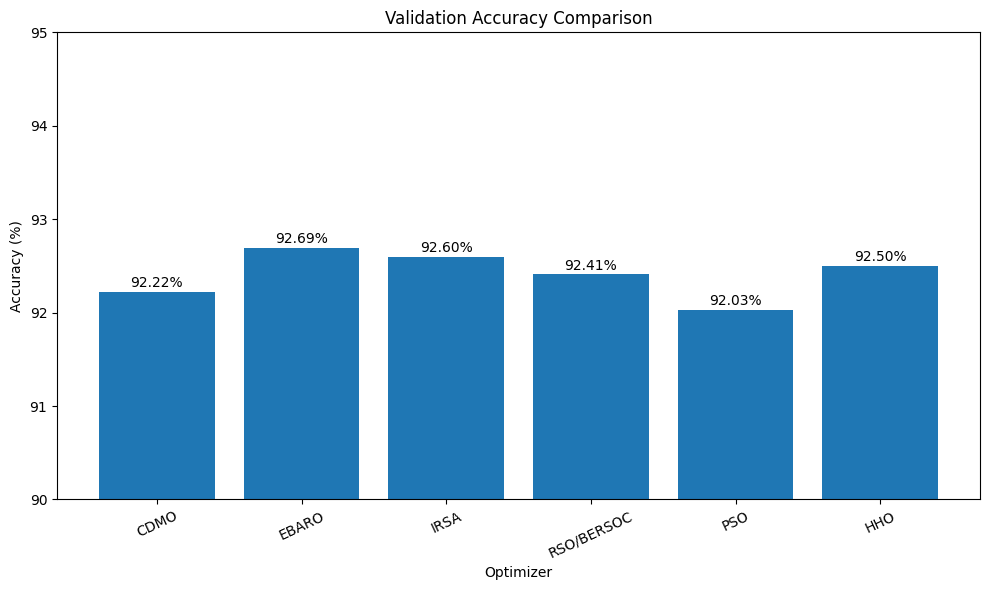

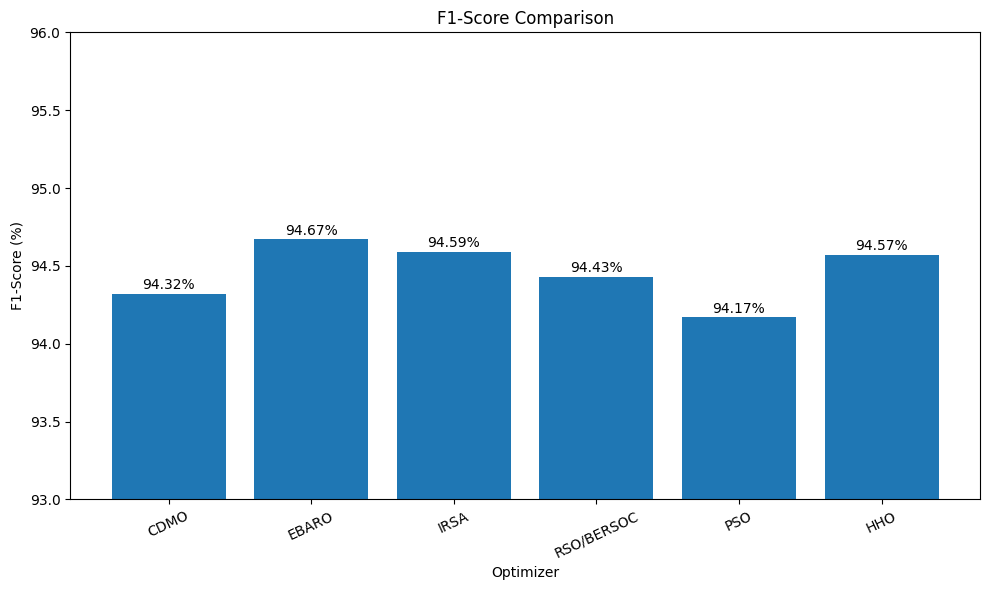

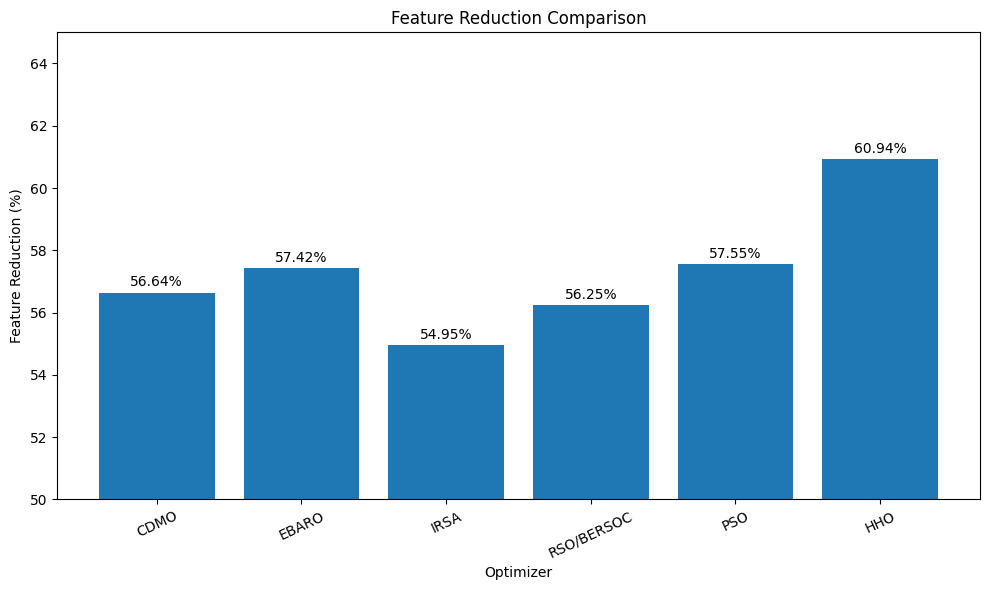

In [57]:
# =============================================================================
# FINAL COMPARISON GRAPHS
# =============================================================================

import matplotlib.pyplot as plt
import numpy as np

optimizers = [
    "CDMO",
    "EBARO",
    "IRSA",
    "RSO/BERSOC",
    "PSO",
    "HHO"
]

accuracy = [
    92.22,
    92.69,
    92.60,
    92.41,
    92.03,
    92.50
]

f1_score = [
    94.32,
    94.67,
    94.59,
    94.43,
    94.17,
    94.57
]

feature_reduction = [
    56.64,
    57.42,
    54.95,
    56.25,
    57.55,
    60.94
]


# =============================================================================
# GRAPH 1 — ACCURACY
# =============================================================================

plt.figure(figsize=(10, 6))

bars = plt.bar(
    optimizers,
    accuracy
)

plt.ylabel("Accuracy (%)")
plt.xlabel("Optimizer")
plt.title("Validation Accuracy Comparison")

plt.ylim(90, 95)

for bar, value in zip(bars, accuracy):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.05,
        f"{value:.2f}%",
        ha="center"
    )

plt.xticks(rotation=25)
plt.tight_layout()
plt.show()


# =============================================================================
# GRAPH 2 — F1 SCORE
# =============================================================================

plt.figure(figsize=(10, 6))

bars = plt.bar(
    optimizers,
    f1_score
)

plt.ylabel("F1-Score (%)")
plt.xlabel("Optimizer")
plt.title("F1-Score Comparison")

plt.ylim(93, 96)

for bar, value in zip(bars, f1_score):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.03,
        f"{value:.2f}%",
        ha="center"
    )

plt.xticks(rotation=25)
plt.tight_layout()
plt.show()


# =============================================================================
# GRAPH 3 — FEATURE REDUCTION
# =============================================================================

plt.figure(figsize=(10, 6))

bars = plt.bar(
    optimizers,
    feature_reduction
)

plt.ylabel("Feature Reduction (%)")
plt.xlabel("Optimizer")
plt.title("Feature Reduction Comparison")

plt.ylim(50, 65)

for bar, value in zip(bars, feature_reduction):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.2,
        f"{value:.2f}%",
        ha="center"
    )

plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

In [58]:
# =============================================================================
# FIND ALL AVAILABLE 768-D FEATURE MASKS
# =============================================================================

import numpy as np

print("=" * 90)
print("SEARCHING FOR AVAILABLE FEATURE MASKS")
print("=" * 90)

found_masks = {}

# IMPORTANT:
# list(globals().items()) prevents
# "dictionary changed size during iteration"
all_variables = list(globals().items())

for name, value in all_variables:

    try:

        if not isinstance(value, np.ndarray):
            continue

        if value.ndim != 1:
            continue

        if len(value) != 768:
            continue

        # Check whether it is binary
        unique_values = np.unique(value)

        if np.all(
            np.isin(
                unique_values,
                [0, 1, False, True]
            )
        ):

            selected = int(
                np.sum(value)
            )

            found_masks[name] = value.copy()

            print(
                f"{name:45s} | "
                f"Shape = {value.shape} | "
                f"Selected Features = {selected}"
            )

    except Exception:
        continue


print("\n" + "=" * 90)

print(
    "TOTAL BINARY 768-D MASKS FOUND:",
    len(found_masks)
)

print("=" * 90)

SEARCHING FOR AVAILABLE FEATURE MASKS
test_mask                                     | Shape = (768,) | Selected Features = 376
mask                                          | Shape = (768,) | Selected Features = 379
best_mask                                     | Shape = (768,) | Selected Features = 336
global_best_move                              | Shape = (768,) | Selected Features = 0
best_mask_irsa                                | Shape = (768,) | Selected Features = 349
exploration_move                              | Shape = (768,) | Selected Features = 0
candidate_mask                                | Shape = (768,) | Selected Features = 311
test_mask_rso                                 | Shape = (768,) | Selected Features = 382
best_mask_rso                                 | Shape = (768,) | Selected Features = 346
elite_mask                                    | Shape = (768,) | Selected Features = 336
local_best_move                               | Shape = (768,) | Selected Fe

In [59]:
# =============================================================================
# SAVE IDENTIFIED FINAL OPTIMIZER MASKS
# =============================================================================

final_optimizer_masks = {}

# RSO / BERSOC - latest result
final_optimizer_masks["RSO"] = best_mask.copy()

# PSO
final_optimizer_masks["PSO"] = pso_gbest_mask.copy()

# HHO
final_optimizer_masks["HHO"] = hho_best_mask.copy()

# IRSA
# IMPORTANT: your notebook currently has two possible IRSA/RSO masks.
# We will NOT assume which one is correct yet.
print("Current IRSA candidates:")
print(
    "best_mask_irsa :", int(best_mask_irsa.sum())
)
print(
    "best_mask_rso  :", int(best_mask_rso.sum())
)

print("\nSaved masks:")
for name, mask_value in final_optimizer_masks.items():

    print(
        f"{name:10s} | "
        f"Features = {int(mask_value.sum()):3d} | "
        f"Shape = {mask_value.shape}"
    )

Current IRSA candidates:
best_mask_irsa : 349
best_mask_rso  : 346

Saved masks:
RSO        | Features = 336 | Shape = (768,)
PSO        | Features = 326 | Shape = (768,)
HHO        | Features = 300 | Shape = (768,)


In [60]:
# =============================================================================
# SEARCH FOR CDMO / EBARO FINAL VARIABLES
# =============================================================================

print("=" * 90)
print("SEARCHING CDMO / EBARO VARIABLES")
print("=" * 90)

all_variables = list(globals().items())

for name, value in all_variables:

    name_lower = name.lower()

    if (
        "cdmo" in name_lower
        or
        "ebaro" in name_lower
    ):

        if isinstance(value, np.ndarray):

            print(
                f"{name:45s} | "
                f"Shape = {value.shape}",
                end=""
            )

            if (
                value.ndim == 1
                and
                len(value) == 768
            ):

                unique_values = np.unique(value)

                if np.all(
                    np.isin(
                        unique_values,
                        [0, 1, False, True]
                    )
                ):

                    print(
                        f" | Selected = {int(value.sum())}"
                    )

                else:

                    print(
                        " | Not binary"
                    )

            else:

                print()

        else:

            print(
                f"{name:45s} | "
                f"Type = {type(value).__name__}"
            )

print("=" * 90)

SEARCHING CDMO / EBARO VARIABLES
CDMO_POPULATION                               | Type = int
CDMO_ITERATIONS                               | Type = int
cdmo_population                               | Shape = (10, 768)
cdmo_fitness                                  | Type = function
cdmo_selected_indices                         | Shape = (333,)
X_train_cdmo                                  | Shape = (9594, 333)
X_val_cdmo                                    | Shape = (1067, 333)
X_train_cdmo_scaled                           | Shape = (9594, 333)
X_val_cdmo_scaled                             | Shape = (1067, 333)
EBARO_POPULATION                              | Type = int
EBARO_ITERATIONS                              | Type = int
rng_ebaro                                     | Type = Generator
continuous_to_binary_ebaro                    | Type = function
population_ebaro                              | Shape = (10, 768)
ebaro_fitness                                 | Type = function
ebaro_c

In [61]:
# =============================================================================
# SAVE FINAL MASKS FOR ALL SIX OPTIMIZERS
# =============================================================================

import numpy as np

TOTAL_FEATURES = 768

final_optimizer_masks = {}

# =============================================================================
# 1. CDMO
# =============================================================================

cdmo_final_mask = np.zeros(
    TOTAL_FEATURES,
    dtype=bool
)

cdmo_final_mask[
    cdmo_selected_indices
] = True


# =============================================================================
# 2. EBARO
# =============================================================================

ebaro_final_mask = np.zeros(
    TOTAL_FEATURES,
    dtype=bool
)

ebaro_final_mask[
    ebaro_selected_indices
] = True


# =============================================================================
# 3. IRSA
# =============================================================================

# best_mask_rso contains the 346-feature IRSA result
irsa_final_mask = best_mask_rso.copy()


# =============================================================================
# 4. RSO / BERSOC
# =============================================================================

# best_mask contains the latest 336-feature RSO/BERSOC result
rso_final_mask = best_mask.copy()


# =============================================================================
# 5. PSO
# =============================================================================

pso_final_mask = pso_gbest_mask.copy()


# =============================================================================
# 6. HHO
# =============================================================================

hho_final_mask = hho_best_mask.copy()


# =============================================================================
# STORE EVERYTHING
# =============================================================================

final_optimizer_masks = {

    "CDMO": cdmo_final_mask,

    "EBARO": ebaro_final_mask,

    "IRSA": irsa_final_mask,

    "RSO/BERSOC": rso_final_mask,

    "PSO": pso_final_mask,

    "HHO": hho_final_mask
}


# =============================================================================
# VERIFY
# =============================================================================

print("=" * 90)
print("FINAL OPTIMIZER MASKS")
print("=" * 90)

for name, mask_value in final_optimizer_masks.items():

    print(
        f"{name:12s} | "
        f"Selected Features = "
        f"{int(mask_value.sum()):3d} | "
        f"Total Features = "
        f"{len(mask_value):3d} | "
        f"Shape = {mask_value.shape}"
    )

print("=" * 90)

FINAL OPTIMIZER MASKS
CDMO         | Selected Features = 333 | Total Features = 768 | Shape = (768,)
EBARO        | Selected Features = 327 | Total Features = 768 | Shape = (768,)
IRSA         | Selected Features = 346 | Total Features = 768 | Shape = (768,)
RSO/BERSOC   | Selected Features = 336 | Total Features = 768 | Shape = (768,)
PSO          | Selected Features = 326 | Total Features = 768 | Shape = (768,)
HHO          | Selected Features = 300 | Total Features = 768 | Shape = (768,)


In [62]:
# =============================================================================
# SVM COMPARISON
# ALL 6 FEATURE SELECTORS
# =============================================================================

from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import pandas as pd


# =============================================================================
# SVM RESULTS
# =============================================================================

svm_results = []


# =============================================================================
# RUN SVM FOR EACH FEATURE SELECTOR
# =============================================================================

for optimizer_name, mask in final_optimizer_masks.items():

    print("\n" + "=" * 80)
    print(f"{optimizer_name} + SVM")
    print("=" * 80)

    # Convert mask to boolean
    mask = mask.astype(bool)

    # -------------------------------------------------------------------------
    # Select features
    # -------------------------------------------------------------------------

    X_train_selected = train_features[:, mask]

    X_val_selected = val_features[:, mask]

    print(
        "Selected features :",
        X_train_selected.shape[1]
    )

    print(
        "Train shape       :",
        X_train_selected.shape
    )

    print(
        "Validation shape  :",
        X_val_selected.shape
    )


    # -------------------------------------------------------------------------
    # Scaling
    # -------------------------------------------------------------------------

    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(
        X_train_selected
    )

    X_val_scaled = scaler.transform(
        X_val_selected
    )


    # -------------------------------------------------------------------------
    # SVM
    # -------------------------------------------------------------------------

    svm_model = SVC(
        kernel="rbf",
        C=10,
        gamma="scale"
    )


    # -------------------------------------------------------------------------
    # Training
    # -------------------------------------------------------------------------

    svm_model.fit(
        X_train_scaled,
        train_labels
    )


    # -------------------------------------------------------------------------
    # Prediction
    # -------------------------------------------------------------------------

    y_pred = svm_model.predict(
        X_val_scaled
    )


    # -------------------------------------------------------------------------
    # Metrics
    # -------------------------------------------------------------------------

    accuracy = accuracy_score(
        val_labels,
        y_pred
    )

    precision = precision_score(
        val_labels,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        val_labels,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        val_labels,
        y_pred,
        zero_division=0
    )


    # -------------------------------------------------------------------------
    # Store
    # -------------------------------------------------------------------------

    svm_results.append({

        "Feature Selector":
            optimizer_name,

        "Selected Features":
            int(mask.sum()),

        "Accuracy (%)":
            accuracy * 100,

        "Precision (%)":
            precision * 100,

        "Recall (%)":
            recall * 100,

        "F1-Score (%)":
            f1 * 100
    })


    # -------------------------------------------------------------------------
    # Print
    # -------------------------------------------------------------------------

    print(
        f"\nAccuracy  : {accuracy:.4f}"
    )

    print(
        f"Precision : {precision:.4f}"
    )

    print(
        f"Recall    : {recall:.4f}"
    )

    print(
        f"F1-Score  : {f1:.4f}"
    )

    print("\nClassification Report:")

    print(
        classification_report(
            val_labels,
            y_pred,
            target_names=["HEM", "ALL"],
            digits=4
        )
    )

    print("Confusion Matrix:")

    print(
        confusion_matrix(
            val_labels,
            y_pred
        )
    )


# =============================================================================
# FINAL SVM TABLE
# =============================================================================

svm_results_df = pd.DataFrame(
    svm_results
)

svm_results_df = svm_results_df.sort_values(
    by="F1-Score (%)",
    ascending=False
).reset_index(
    drop=True
)


print("\n" + "=" * 100)
print("FINAL SVM COMPARISON")
print("=" * 100)

display(
    svm_results_df.round(2)
)


CDMO + SVM
Selected features : 333
Train shape       : (9594, 333)
Validation shape  : (1067, 333)

Accuracy  : 0.9550
Precision : 0.9658
Recall    : 0.9684
F1-Score  : 0.9671

Classification Report:
              precision    recall  f1-score   support

         HEM     0.9318    0.9263    0.9290       339
         ALL     0.9658    0.9684    0.9671       728

    accuracy                         0.9550      1067
   macro avg     0.9488    0.9473    0.9480      1067
weighted avg     0.9550    0.9550    0.9550      1067

Confusion Matrix:
[[314  25]
 [ 23 705]]

EBARO + SVM
Selected features : 327
Train shape       : (9594, 327)
Validation shape  : (1067, 327)

Accuracy  : 0.9503
Precision : 0.9630
Recall    : 0.9643
F1-Score  : 0.9636

Classification Report:
              precision    recall  f1-score   support

         HEM     0.9231    0.9204    0.9217       339
         ALL     0.9630    0.9643    0.9636       728

    accuracy                         0.9503      1067
   macro av

,Feature Selector,Selected Features,Accuracy (%),Precision (%),Recall (%),F1-Score (%)
0,HHO,300,95.60,96.58,96.98,96.78
1,CDMO,333,95.50,96.58,96.84,96.71
2,PSO,326,95.41,96.57,96.70,96.64
3,RSO/BERSOC,336,95.31,95.93,97.25,96.59
4,IRSA,346,95.13,96.43,96.43,96.43
5,EBARO,327,95.03,96.30,96.43,96.36


In [63]:
# =============================================================================
# XGBOOST COMPARISON
# ALL 6 FEATURE SELECTORS
# =============================================================================

from xgboost import XGBClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import pandas as pd


xgb_results = []

for optimizer_name, mask in final_optimizer_masks.items():

    print("\n" + "=" * 80)
    print(f"{optimizer_name} + XGBoost")
    print("=" * 80)

    mask = mask.astype(bool)

    # -------------------------------------------------------------------------
    # Select features
    # -------------------------------------------------------------------------

    X_train_selected = train_features[:, mask]
    X_val_selected = val_features[:, mask]

    print("Selected features :", X_train_selected.shape[1])
    print("Train shape       :", X_train_selected.shape)
    print("Validation shape  :", X_val_selected.shape)

    # -------------------------------------------------------------------------
    # Scaling
    #
    # XGBoost does not require scaling, but keeping the preprocessing
    # consistent is acceptable for this comparison.
    # -------------------------------------------------------------------------

    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(
        X_train_selected
    )

    X_val_scaled = scaler.transform(
        X_val_selected
    )

    # -------------------------------------------------------------------------
    # XGBoost
    # -------------------------------------------------------------------------

    xgb_model = XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )

    # -------------------------------------------------------------------------
    # Training
    # -------------------------------------------------------------------------

    xgb_model.fit(
        X_train_scaled,
        train_labels
    )

    # -------------------------------------------------------------------------
    # Prediction
    # -------------------------------------------------------------------------

    y_pred = xgb_model.predict(
        X_val_scaled
    )

    # -------------------------------------------------------------------------
    # Metrics
    # -------------------------------------------------------------------------

    accuracy = accuracy_score(
        val_labels,
        y_pred
    )

    precision = precision_score(
        val_labels,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        val_labels,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        val_labels,
        y_pred,
        zero_division=0
    )

    # -------------------------------------------------------------------------
    # Save results
    # -------------------------------------------------------------------------

    xgb_results.append({

        "Feature Selector":
            optimizer_name,

        "Selected Features":
            int(mask.sum()),

        "Accuracy (%)":
            accuracy * 100,

        "Precision (%)":
            precision * 100,

        "Recall (%)":
            recall * 100,

        "F1-Score (%)":
            f1 * 100
    })

    # -------------------------------------------------------------------------
    # Display
    # -------------------------------------------------------------------------

    print(f"\nAccuracy  : {accuracy:.4f}")
    print(f"Precision : {precision:.4f}")
    print(f"Recall    : {recall:.4f}")
    print(f"F1-Score  : {f1:.4f}")

    print("\nClassification Report:")

    print(
        classification_report(
            val_labels,
            y_pred,
            target_names=["HEM", "ALL"],
            digits=4
        )
    )

    print("Confusion Matrix:")

    print(
        confusion_matrix(
            val_labels,
            y_pred
        )
    )


# =============================================================================
# FINAL XGBOOST TABLE
# =============================================================================

xgb_results_df = pd.DataFrame(
    xgb_results
)

xgb_results_df = (
    xgb_results_df
    .sort_values(
        by="F1-Score (%)",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 100)
print("FINAL XGBOOST COMPARISON")
print("=" * 100)

display(
    xgb_results_df.round(2)
)


CDMO + XGBoost
Selected features : 333
Train shape       : (9594, 333)
Validation shape  : (1067, 333)

Accuracy  : 0.9372
Precision : 0.9377
Recall    : 0.9725
F1-Score  : 0.9548

Classification Report:
              precision    recall  f1-score   support

         HEM     0.9359    0.8614    0.8971       339
         ALL     0.9377    0.9725    0.9548       728

    accuracy                         0.9372      1067
   macro avg     0.9368    0.9169    0.9260      1067
weighted avg     0.9372    0.9372    0.9365      1067

Confusion Matrix:
[[292  47]
 [ 20 708]]

EBARO + XGBoost
Selected features : 327
Train shape       : (9594, 327)
Validation shape  : (1067, 327)

Accuracy  : 0.9306
Precision : 0.9360
Recall    : 0.9643
F1-Score  : 0.9499

Classification Report:
              precision    recall  f1-score   support

         HEM     0.9180    0.8584    0.8872       339
         ALL     0.9360    0.9643    0.9499       728

    accuracy                         0.9306      1067
   

,Feature Selector,Selected Features,Accuracy (%),Precision (%),Recall (%),F1-Score (%)
0,CDMO,333,93.72,93.77,97.25,95.48
1,HHO,300,93.72,94.01,96.98,95.47
2,PSO,326,93.44,93.98,96.57,95.26
3,IRSA,346,93.25,93.62,96.70,95.14
4,RSO/BERSOC,336,93.16,93.61,96.57,95.06
5,EBARO,327,93.06,93.60,96.43,94.99


In [64]:
# =============================================================================
# RANDOM FOREST COMPARISON
# ALL 6 FEATURE SELECTORS
# =============================================================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import pandas as pd


rf_results = []


for optimizer_name, mask in final_optimizer_masks.items():

    print("\n" + "=" * 80)
    print(f"{optimizer_name} + RANDOM FOREST")
    print("=" * 80)

    # -------------------------------------------------------------------------
    # Convert mask
    # -------------------------------------------------------------------------

    mask = mask.astype(bool)

    # -------------------------------------------------------------------------
    # Select features
    # -------------------------------------------------------------------------

    X_train_selected = train_features[:, mask]
    X_val_selected = val_features[:, mask]

    print(
        "Selected features :",
        X_train_selected.shape[1]
    )

    print(
        "Train shape       :",
        X_train_selected.shape
    )

    print(
        "Validation shape  :",
        X_val_selected.shape
    )

    # -------------------------------------------------------------------------
    # RANDOM FOREST
    #
    # No StandardScaler is required for Random Forest.
    # -------------------------------------------------------------------------

    rf_model = RandomForestClassifier(

        n_estimators=500,

        max_features="sqrt",

        max_depth=None,

        min_samples_split=2,

        min_samples_leaf=1,

        bootstrap=True,

        class_weight="balanced",

        random_state=42,

        n_jobs=-1
    )

    # -------------------------------------------------------------------------
    # TRAIN
    # -------------------------------------------------------------------------

    rf_model.fit(
        X_train_selected,
        train_labels
    )

    # -------------------------------------------------------------------------
    # PREDICTION
    # -------------------------------------------------------------------------

    y_pred = rf_model.predict(
        X_val_selected
    )

    # -------------------------------------------------------------------------
    # METRICS
    # -------------------------------------------------------------------------

    accuracy = accuracy_score(
        val_labels,
        y_pred
    )

    precision = precision_score(
        val_labels,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        val_labels,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        val_labels,
        y_pred,
        zero_division=0
    )

    # -------------------------------------------------------------------------
    # SAVE RESULTS
    # -------------------------------------------------------------------------

    rf_results.append({

        "Feature Selector":
            optimizer_name,

        "Selected Features":
            int(mask.sum()),

        "Accuracy (%)":
            accuracy * 100,

        "Precision (%)":
            precision * 100,

        "Recall (%)":
            recall * 100,

        "F1-Score (%)":
            f1 * 100
    })

    # -------------------------------------------------------------------------
    # PRINT RESULTS
    # -------------------------------------------------------------------------

    print(
        f"\nAccuracy  : {accuracy:.4f}"
    )

    print(
        f"Precision : {precision:.4f}"
    )

    print(
        f"Recall    : {recall:.4f}"
    )

    print(
        f"F1-Score  : {f1:.4f}"
    )

    print("\nClassification Report:")

    print(
        classification_report(
            val_labels,
            y_pred,
            target_names=["HEM", "ALL"],
            digits=4
        )
    )

    print("Confusion Matrix:")

    print(
        confusion_matrix(
            val_labels,
            y_pred
        )
    )


# =============================================================================
# FINAL RANDOM FOREST TABLE
# =============================================================================

rf_results_df = pd.DataFrame(
    rf_results
)

rf_results_df = (
    rf_results_df
    .sort_values(
        by="F1-Score (%)",
        ascending=False
    )
    .reset_index(drop=True)
)


print("\n" + "=" * 100)
print("FINAL RANDOM FOREST COMPARISON")
print("=" * 100)

display(
    rf_results_df.round(2)
)


CDMO + RANDOM FOREST
Selected features : 333
Train shape       : (9594, 333)
Validation shape  : (1067, 333)

Accuracy  : 0.9297
Precision : 0.9268
Recall    : 0.9739
F1-Score  : 0.9498

Classification Report:
              precision    recall  f1-score   support

         HEM     0.9371    0.8348    0.8830       339
         ALL     0.9268    0.9739    0.9498       728

    accuracy                         0.9297      1067
   macro avg     0.9319    0.9044    0.9164      1067
weighted avg     0.9301    0.9297    0.9286      1067

Confusion Matrix:
[[283  56]
 [ 19 709]]

EBARO + RANDOM FOREST
Selected features : 327
Train shape       : (9594, 327)
Validation shape  : (1067, 327)

Accuracy  : 0.9306
Precision : 0.9269
Recall    : 0.9753
F1-Score  : 0.9505

Classification Report:
              precision    recall  f1-score   support

         HEM     0.9402    0.8348    0.8844       339
         ALL     0.9269    0.9753    0.9505       728

    accuracy                         0.9306  

,Feature Selector,Selected Features,Accuracy (%),Precision (%),Recall (%),F1-Score (%)
0,HHO,300,93.63,93.19,97.80,95.44
1,IRSA,346,93.44,92.95,97.80,95.31
2,PSO,326,93.06,92.58,97.66,95.05
3,EBARO,327,93.06,92.69,97.53,95.05
4,RSO/BERSOC,336,92.97,92.57,97.53,94.98
5,CDMO,333,92.97,92.68,97.39,94.98


In [65]:
# =============================================================================
# LOGISTIC REGRESSION COMPARISON
# ALL 6 FEATURE SELECTORS
# =============================================================================

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import pandas as pd


lr_results = []


for optimizer_name, mask in final_optimizer_masks.items():

    print("\n" + "=" * 80)
    print(f"{optimizer_name} + LOGISTIC REGRESSION")
    print("=" * 80)

    mask = mask.astype(bool)

    # -------------------------------------------------------------------------
    # Select features
    # -------------------------------------------------------------------------

    X_train_selected = train_features[:, mask]
    X_val_selected = val_features[:, mask]

    print("Selected features :", X_train_selected.shape[1])
    print("Train shape       :", X_train_selected.shape)
    print("Validation shape  :", X_val_selected.shape)

    # -------------------------------------------------------------------------
    # Scaling
    # -------------------------------------------------------------------------

    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(
        X_train_selected
    )

    X_val_scaled = scaler.transform(
        X_val_selected
    )

    # -------------------------------------------------------------------------
    # Logistic Regression
    # -------------------------------------------------------------------------

    lr_model = LogisticRegression(
        C=1.0,
        max_iter=2000,
        class_weight="balanced",
        solver="lbfgs",
        random_state=42
    )

    # -------------------------------------------------------------------------
    # Training
    # -------------------------------------------------------------------------

    lr_model.fit(
        X_train_scaled,
        train_labels
    )

    # -------------------------------------------------------------------------
    # Prediction
    # -------------------------------------------------------------------------

    y_pred = lr_model.predict(
        X_val_scaled
    )

    # -------------------------------------------------------------------------
    # Metrics
    # -------------------------------------------------------------------------

    accuracy = accuracy_score(
        val_labels,
        y_pred
    )

    precision = precision_score(
        val_labels,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        val_labels,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        val_labels,
        y_pred,
        zero_division=0
    )

    # -------------------------------------------------------------------------
    # Save result
    # -------------------------------------------------------------------------

    lr_results.append({

        "Feature Selector":
            optimizer_name,

        "Selected Features":
            int(mask.sum()),

        "Accuracy (%)":
            accuracy * 100,

        "Precision (%)":
            precision * 100,

        "Recall (%)":
            recall * 100,

        "F1-Score (%)":
            f1 * 100
    })

    # -------------------------------------------------------------------------
    # Display
    # -------------------------------------------------------------------------

    print(f"\nAccuracy  : {accuracy:.4f}")
    print(f"Precision : {precision:.4f}")
    print(f"Recall    : {recall:.4f}")
    print(f"F1-Score  : {f1:.4f}")

    print("\nClassification Report:")

    print(
        classification_report(
            val_labels,
            y_pred,
            target_names=["HEM", "ALL"],
            digits=4
        )
    )

    print("Confusion Matrix:")

    print(
        confusion_matrix(
            val_labels,
            y_pred
        )
    )


# =============================================================================
# FINAL LOGISTIC REGRESSION TABLE
# =============================================================================

lr_results_df = pd.DataFrame(
    lr_results
)

lr_results_df = (
    lr_results_df
    .sort_values(
        by="F1-Score (%)",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 100)
print("FINAL LOGISTIC REGRESSION COMPARISON")
print("=" * 100)

display(
    lr_results_df.round(2)
)


CDMO + LOGISTIC REGRESSION
Selected features : 333
Train shape       : (9594, 333)
Validation shape  : (1067, 333)

Accuracy  : 0.9260
Precision : 0.9577
Recall    : 0.9327
F1-Score  : 0.9450

Classification Report:
              precision    recall  f1-score   support

         HEM     0.8631    0.9115    0.8867       339
         ALL     0.9577    0.9327    0.9450       728

    accuracy                         0.9260      1067
   macro avg     0.9104    0.9221    0.9158      1067
weighted avg     0.9276    0.9260    0.9265      1067

Confusion Matrix:
[[309  30]
 [ 49 679]]

EBARO + LOGISTIC REGRESSION
Selected features : 327
Train shape       : (9594, 327)
Validation shape  : (1067, 327)

Accuracy  : 0.9288
Precision : 0.9605
Recall    : 0.9341
F1-Score  : 0.9471

Classification Report:
              precision    recall  f1-score   support

         HEM     0.8663    0.9174    0.8911       339
         ALL     0.9605    0.9341    0.9471       728

    accuracy                     

,Feature Selector,Selected Features,Accuracy (%),Precision (%),Recall (%),F1-Score (%)
0,HHO,300,93.35,95.94,94.23,95.08
1,PSO,326,93.25,96.33,93.68,94.99
2,IRSA,346,92.97,95.66,93.96,94.80
3,EBARO,327,92.88,96.05,93.41,94.71
4,RSO/BERSOC,336,92.69,95.77,93.41,94.58
5,CDMO,333,92.60,95.77,93.27,94.50


In [66]:
# =============================================================================
# MLP COMPARISON
# ALL 6 FEATURE SELECTORS
# =============================================================================

from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import pandas as pd


mlp_results = []


for optimizer_name, mask in final_optimizer_masks.items():

    print("\n" + "=" * 80)
    print(f"{optimizer_name} + MLP")
    print("=" * 80)

    # -------------------------------------------------------------------------
    # Feature mask
    # -------------------------------------------------------------------------

    mask = mask.astype(bool)

    X_train_selected = train_features[:, mask]
    X_val_selected = val_features[:, mask]

    print("Selected features :", X_train_selected.shape[1])
    print("Train shape       :", X_train_selected.shape)
    print("Validation shape  :", X_val_selected.shape)

    # -------------------------------------------------------------------------
    # Scaling
    # -------------------------------------------------------------------------

    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(
        X_train_selected
    )

    X_val_scaled = scaler.transform(
        X_val_selected
    )

    # -------------------------------------------------------------------------
    # MLP
    # -------------------------------------------------------------------------

    mlp_model = MLPClassifier(
        hidden_layer_sizes=(256, 128, 64),
        activation="relu",
        solver="adam",
        alpha=1e-4,
        learning_rate_init=1e-3,
        max_iter=300,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=15,
        batch_size=64,
        random_state=42
    )

    # -------------------------------------------------------------------------
    # Training
    # -------------------------------------------------------------------------

    mlp_model.fit(
        X_train_scaled,
        train_labels
    )

    # -------------------------------------------------------------------------
    # Prediction
    # -------------------------------------------------------------------------

    y_pred = mlp_model.predict(
        X_val_scaled
    )

    # -------------------------------------------------------------------------
    # Metrics
    # -------------------------------------------------------------------------

    accuracy = accuracy_score(
        val_labels,
        y_pred
    )

    precision = precision_score(
        val_labels,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        val_labels,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        val_labels,
        y_pred,
        zero_division=0
    )

    # -------------------------------------------------------------------------
    # Save results
    # -------------------------------------------------------------------------

    mlp_results.append({

        "Feature Selector":
            optimizer_name,

        "Selected Features":
            int(mask.sum()),

        "Accuracy (%)":
            accuracy * 100,

        "Precision (%)":
            precision * 100,

        "Recall (%)":
            recall * 100,

        "F1-Score (%)":
            f1 * 100,

        "MLP Iterations":
            mlp_model.n_iter_
    })

    # -------------------------------------------------------------------------
    # Display
    # -------------------------------------------------------------------------

    print(f"\nAccuracy  : {accuracy:.4f}")
    print(f"Precision : {precision:.4f}")
    print(f"Recall    : {recall:.4f}")
    print(f"F1-Score  : {f1:.4f}")

    print(
        "MLP iterations:",
        mlp_model.n_iter_
    )

    print("\nClassification Report:")

    print(
        classification_report(
            val_labels,
            y_pred,
            target_names=["HEM", "ALL"],
            digits=4
        )
    )

    print("Confusion Matrix:")

    print(
        confusion_matrix(
            val_labels,
            y_pred
        )
    )


# =============================================================================
# FINAL MLP TABLE
# =============================================================================

mlp_results_df = pd.DataFrame(
    mlp_results
)

mlp_results_df = (
    mlp_results_df
    .sort_values(
        by="F1-Score (%)",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 100)
print("FINAL MLP COMPARISON")
print("=" * 100)

display(
    mlp_results_df.round(2)
)


CDMO + MLP
Selected features : 333
Train shape       : (9594, 333)
Validation shape  : (1067, 333)

Accuracy  : 0.9428
Precision : 0.9525
Recall    : 0.9643
F1-Score  : 0.9584
MLP iterations: 28

Classification Report:
              precision    recall  f1-score   support

         HEM     0.9212    0.8968    0.9088       339
         ALL     0.9525    0.9643    0.9584       728

    accuracy                         0.9428      1067
   macro avg     0.9369    0.9305    0.9336      1067
weighted avg     0.9426    0.9428    0.9426      1067

Confusion Matrix:
[[304  35]
 [ 26 702]]

EBARO + MLP
Selected features : 327
Train shape       : (9594, 327)
Validation shape  : (1067, 327)

Accuracy  : 0.9447
Precision : 0.9539
Recall    : 0.9657
F1-Score  : 0.9597
MLP iterations: 23

Classification Report:
              precision    recall  f1-score   support

         HEM     0.9242    0.8997    0.9118       339
         ALL     0.9539    0.9657    0.9597       728

    accuracy               

,Feature Selector,Selected Features,Accuracy (%),Precision (%),Recall (%),F1-Score (%),MLP Iterations
0,HHO,300,95.13,96.56,96.29,96.42,32
1,PSO,326,95.03,95.42,97.39,96.40,30
2,EBARO,327,94.47,95.39,96.57,95.97,23
3,IRSA,346,94.47,96.27,95.60,95.93,35
4,CDMO,333,94.28,95.25,96.43,95.84,28
5,RSO/BERSOC,336,93.72,95.84,94.92,95.38,25


In [67]:
# =============================================================================
# KNN COMPARISON
# ALL 6 FEATURE SELECTORS
# =============================================================================

from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import pandas as pd


knn_results = []


for optimizer_name, mask in final_optimizer_masks.items():

    print("\n" + "=" * 80)
    print(f"{optimizer_name} + KNN")
    print("=" * 80)

    # -------------------------------------------------------------------------
    # Feature mask
    # -------------------------------------------------------------------------

    mask = mask.astype(bool)

    X_train_selected = train_features[:, mask]
    X_val_selected = val_features[:, mask]

    print("Selected features :", X_train_selected.shape[1])
    print("Train shape       :", X_train_selected.shape)
    print("Validation shape  :", X_val_selected.shape)

    # -------------------------------------------------------------------------
    # Scaling
    #
    # IMPORTANT:
    # KNN depends on distance, so scaling is required.
    # -------------------------------------------------------------------------

    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(
        X_train_selected
    )

    X_val_scaled = scaler.transform(
        X_val_selected
    )

    # -------------------------------------------------------------------------
    # KNN
    # -------------------------------------------------------------------------

    knn_model = KNeighborsClassifier(
        n_neighbors=5,
        weights="distance",
        metric="euclidean",
        n_jobs=-1
    )

    # -------------------------------------------------------------------------
    # Training
    # -------------------------------------------------------------------------

    knn_model.fit(
        X_train_scaled,
        train_labels
    )

    # -------------------------------------------------------------------------
    # Prediction
    # -------------------------------------------------------------------------

    y_pred = knn_model.predict(
        X_val_scaled
    )

    # -------------------------------------------------------------------------
    # Metrics
    # -------------------------------------------------------------------------

    accuracy = accuracy_score(
        val_labels,
        y_pred
    )

    precision = precision_score(
        val_labels,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        val_labels,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        val_labels,
        y_pred,
        zero_division=0
    )

    # -------------------------------------------------------------------------
    # Save
    # -------------------------------------------------------------------------

    knn_results.append({

        "Feature Selector":
            optimizer_name,

        "Selected Features":
            int(mask.sum()),

        "Accuracy (%)":
            accuracy * 100,

        "Precision (%)":
            precision * 100,

        "Recall (%)":
            recall * 100,

        "F1-Score (%)":
            f1 * 100
    })

    # -------------------------------------------------------------------------
    # Display
    # -------------------------------------------------------------------------

    print(f"\nAccuracy  : {accuracy:.4f}")
    print(f"Precision : {precision:.4f}")
    print(f"Recall    : {recall:.4f}")
    print(f"F1-Score  : {f1:.4f}")

    print("\nClassification Report:")

    print(
        classification_report(
            val_labels,
            y_pred,
            target_names=["HEM", "ALL"],
            digits=4
        )
    )

    print("Confusion Matrix:")

    print(
        confusion_matrix(
            val_labels,
            y_pred
        )
    )


# =============================================================================
# FINAL KNN TABLE
# =============================================================================

knn_results_df = pd.DataFrame(
    knn_results
)

knn_results_df = (
    knn_results_df
    .sort_values(
        by="F1-Score (%)",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 100)
print("FINAL KNN COMPARISON")
print("=" * 100)

display(
    knn_results_df.round(2)
)


CDMO + KNN
Selected features : 333
Train shape       : (9594, 333)
Validation shape  : (1067, 333)

Accuracy  : 0.9316
Precision : 0.9492
Recall    : 0.9505
F1-Score  : 0.9499

Classification Report:
              precision    recall  f1-score   support

         HEM     0.8935    0.8909    0.8922       339
         ALL     0.9492    0.9505    0.9499       728

    accuracy                         0.9316      1067
   macro avg     0.9214    0.9207    0.9210      1067
weighted avg     0.9315    0.9316    0.9316      1067

Confusion Matrix:
[[302  37]
 [ 36 692]]

EBARO + KNN
Selected features : 327
Train shape       : (9594, 327)
Validation shape  : (1067, 327)

Accuracy  : 0.9363
Precision : 0.9508
Recall    : 0.9560
F1-Score  : 0.9534

Classification Report:
              precision    recall  f1-score   support

         HEM     0.9045    0.8938    0.8991       339
         ALL     0.9508    0.9560    0.9534       728

    accuracy                         0.9363      1067
   macro av

,Feature Selector,Selected Features,Accuracy (%),Precision (%),Recall (%),F1-Score (%)
0,HHO,300,93.81,95.34,95.60,95.47
1,IRSA,346,93.81,95.47,95.47,95.47
2,EBARO,327,93.63,95.08,95.60,95.34
3,RSO/BERSOC,336,93.25,95.56,94.51,95.03
4,CDMO,333,93.16,94.92,95.05,94.99
5,PSO,326,93.16,95.30,94.64,94.97


In [68]:
# =============================================================================
# DECISION TREE COMPARISON
# ALL 6 FEATURE SELECTORS
# =============================================================================

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import pandas as pd


dt_results = []


for optimizer_name, mask in final_optimizer_masks.items():

    print("\n" + "=" * 80)
    print(f"{optimizer_name} + DECISION TREE")
    print("=" * 80)

    # -------------------------------------------------------------------------
    # Feature mask
    # -------------------------------------------------------------------------

    mask = mask.astype(bool)

    X_train_selected = train_features[:, mask]
    X_val_selected = val_features[:, mask]

    print("Selected features :", X_train_selected.shape[1])
    print("Train shape       :", X_train_selected.shape)
    print("Validation shape  :", X_val_selected.shape)

    # -------------------------------------------------------------------------
    # Decision Tree
    # -------------------------------------------------------------------------

    dt_model = DecisionTreeClassifier(
        criterion="gini",
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        class_weight="balanced",
        random_state=42
    )

    # -------------------------------------------------------------------------
    # Training
    # -------------------------------------------------------------------------

    dt_model.fit(
        X_train_selected,
        train_labels
    )

    # -------------------------------------------------------------------------
    # Prediction
    # -------------------------------------------------------------------------

    y_pred = dt_model.predict(
        X_val_selected
    )

    # -------------------------------------------------------------------------
    # Metrics
    # -------------------------------------------------------------------------

    accuracy = accuracy_score(
        val_labels,
        y_pred
    )

    precision = precision_score(
        val_labels,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        val_labels,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        val_labels,
        y_pred,
        zero_division=0
    )

    # -------------------------------------------------------------------------
    # Save
    # -------------------------------------------------------------------------

    dt_results.append({

        "Feature Selector":
            optimizer_name,

        "Selected Features":
            int(mask.sum()),

        "Accuracy (%)":
            accuracy * 100,

        "Precision (%)":
            precision * 100,

        "Recall (%)":
            recall * 100,

        "F1-Score (%)":
            f1 * 100
    })

    # -------------------------------------------------------------------------
    # Display
    # -------------------------------------------------------------------------

    print(f"\nAccuracy  : {accuracy:.4f}")
    print(f"Precision : {precision:.4f}")
    print(f"Recall    : {recall:.4f}")
    print(f"F1-Score  : {f1:.4f}")

    print("\nClassification Report:")

    print(
        classification_report(
            val_labels,
            y_pred,
            target_names=["HEM", "ALL"],
            digits=4
        )
    )

    print("Confusion Matrix:")

    print(
        confusion_matrix(
            val_labels,
            y_pred
        )
    )


# =============================================================================
# FINAL DECISION TREE TABLE
# =============================================================================

dt_results_df = pd.DataFrame(
    dt_results
)

dt_results_df = (
    dt_results_df
    .sort_values(
        by="F1-Score (%)",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 100)
print("FINAL DECISION TREE COMPARISON")
print("=" * 100)

display(
    dt_results_df.round(2)
)


CDMO + DECISION TREE
Selected features : 333
Train shape       : (9594, 333)
Validation shape  : (1067, 333)

Accuracy  : 0.8857
Precision : 0.9220
Recall    : 0.9093
F1-Score  : 0.9156

Classification Report:
              precision    recall  f1-score   support

         HEM     0.8109    0.8348    0.8227       339
         ALL     0.9220    0.9093    0.9156       728

    accuracy                         0.8857      1067
   macro avg     0.8664    0.8721    0.8692      1067
weighted avg     0.8867    0.8857    0.8861      1067

Confusion Matrix:
[[283  56]
 [ 66 662]]

EBARO + DECISION TREE
Selected features : 327
Train shape       : (9594, 327)
Validation shape  : (1067, 327)

Accuracy  : 0.8969
Precision : 0.9245
Recall    : 0.9245
F1-Score  : 0.9245

Classification Report:
              precision    recall  f1-score   support

         HEM     0.8378    0.8378    0.8378       339
         ALL     0.9245    0.9245    0.9245       728

    accuracy                         0.8969  

,Feature Selector,Selected Features,Accuracy (%),Precision (%),Recall (%),F1-Score (%)
0,HHO,300,91.28,92.85,94.51,93.67
1,IRSA,346,90.35,91.50,94.64,93.05
2,EBARO,327,89.69,92.45,92.45,92.45
3,RSO/BERSOC,336,89.32,92.17,92.17,92.17
4,CDMO,333,88.57,92.20,90.93,91.56
5,PSO,326,88.28,91.36,91.48,91.42


In [69]:
# =============================================================================
# FINAL 42-EXPERIMENT COMPARISON
# 7 CLASSIFIERS × 6 FEATURE SELECTORS
# =============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# =============================================================================
# COMBINE ALL CLASSIFIER RESULTS
# =============================================================================

all_results = pd.concat(
    [
        svm_results_df.assign(Classifier="SVM"),
        xgb_results_df.assign(Classifier="XGBoost"),
        rf_results_df.assign(Classifier="Random Forest"),
        lr_results_df.assign(Classifier="Logistic Regression"),
        mlp_results_df.assign(Classifier="MLP"),
        knn_results_df.assign(Classifier="KNN"),
        dt_results_df.assign(Classifier="Decision Tree")
    ],
    ignore_index=True
)


# =============================================================================
# REORDER COLUMNS
# =============================================================================

all_results = all_results[
    [
        "Feature Selector",
        "Classifier",
        "Selected Features",
        "Accuracy (%)",
        "Precision (%)",
        "Recall (%)",
        "F1-Score (%)"
    ]
]


# =============================================================================
# SORT BY ACCURACY
# =============================================================================

all_results = (
    all_results
    .sort_values(
        by="Accuracy (%)",
        ascending=False
    )
    .reset_index(drop=True)
)


# =============================================================================
# DISPLAY ALL 42 RESULTS
# =============================================================================

print("=" * 120)
print("FINAL 42-EXPERIMENT COMPARISON")
print("=" * 120)

display(
    all_results.round(2)
)


# =============================================================================
# BEST OVERALL MODEL
# =============================================================================

best_result = all_results.iloc[0]


print("\n")
print("=" * 100)
print("BEST OVERALL MODEL")
print("=" * 100)

print(
    "Feature Selector :",
    best_result["Feature Selector"]
)

print(
    "Classifier       :",
    best_result["Classifier"]
)

print(
    "Selected Features:",
    int(best_result["Selected Features"])
)

print(
    "Accuracy         :",
    f'{best_result["Accuracy (%)"]:.2f}%'
)

print(
    "Precision        :",
    f'{best_result["Precision (%)"]:.2f}%'
)

print(
    "Recall           :",
    f'{best_result["Recall (%)"]:.2f}%'
)

print(
    "F1-Score         :",
    f'{best_result["F1-Score (%)"]:.2f}%'
)


# =============================================================================
# BEST RESULT FROM EACH CLASSIFIER
# =============================================================================

best_by_classifier = (
    all_results
    .sort_values(
        "Accuracy (%)",
        ascending=False
    )
    .groupby(
        "Classifier",
        as_index=False
    )
    .first()
    .sort_values(
        "Accuracy (%)",
        ascending=False
    )
)


print("\n")
print("=" * 100)
print("BEST RESULT FOR EACH CLASSIFIER")
print("=" * 100)

display(
    best_by_classifier.round(2)
)


# =============================================================================
# BEST RESULT FROM EACH FEATURE SELECTOR
# =============================================================================

best_by_optimizer = (
    all_results
    .sort_values(
        "Accuracy (%)",
        ascending=False
    )
    .groupby(
        "Feature Selector",
        as_index=False
    )
    .first()
    .sort_values(
        "Accuracy (%)",
        ascending=False
    )
)


print("\n")
print("=" * 100)
print("BEST RESULT FOR EACH FEATURE SELECTOR")
print("=" * 100)

display(
    best_by_optimizer.round(2)
)


print("\n")
print("=" * 100)
print("42 EXPERIMENTS COMPLETED")
print("=" * 100)

FINAL 42-EXPERIMENT COMPARISON


,Feature Selector,Classifier,Selected Features,Accuracy (%),Precision (%),Recall (%),F1-Score (%)
0,HHO,SVM,300,95.60,96.58,96.98,96.78
1,CDMO,SVM,333,95.50,96.58,96.84,96.71
2,PSO,SVM,326,95.41,96.57,96.70,96.64
3,RSO/BERSOC,SVM,336,95.31,95.93,97.25,96.59
4,IRSA,SVM,346,95.13,96.43,96.43,96.43
5,HHO,MLP,300,95.13,96.56,96.29,96.42
6,PSO,MLP,326,95.03,95.42,97.39,96.40
7,EBARO,SVM,327,95.03,96.30,96.43,96.36
8,EBARO,MLP,327,94.47,95.39,96.57,95.97
9,IRSA,MLP,346,94.47,96.27,95.60,95.93




BEST OVERALL MODEL
Feature Selector : HHO
Classifier       : SVM
Selected Features: 300
Accuracy         : 95.60%
Precision        : 96.58%
Recall           : 96.98%
F1-Score         : 96.78%


BEST RESULT FOR EACH CLASSIFIER


,Classifier,Feature Selector,Selected Features,Accuracy (%),Precision (%),Recall (%),F1-Score (%)
5,SVM,HHO,300,95.60,96.58,96.98,96.78
3,MLP,HHO,300,95.13,96.56,96.29,96.42
1,KNN,HHO,300,93.81,95.34,95.60,95.47
6,XGBoost,CDMO,333,93.72,93.77,97.25,95.48
4,Random Forest,HHO,300,93.63,93.19,97.80,95.44
2,Logistic Regression,HHO,300,93.35,95.94,94.23,95.08
0,Decision Tree,HHO,300,91.28,92.85,94.51,93.67




BEST RESULT FOR EACH FEATURE SELECTOR


,Feature Selector,Classifier,Selected Features,Accuracy (%),Precision (%),Recall (%),F1-Score (%)
2,HHO,SVM,300,95.60,96.58,96.98,96.78
0,CDMO,SVM,333,95.50,96.58,96.84,96.71
4,PSO,SVM,326,95.41,96.57,96.70,96.64
5,RSO/BERSOC,SVM,336,95.31,95.93,97.25,96.59
3,IRSA,SVM,346,95.13,96.43,96.43,96.43
1,EBARO,SVM,327,95.03,96.30,96.43,96.36




42 EXPERIMENTS COMPLETED


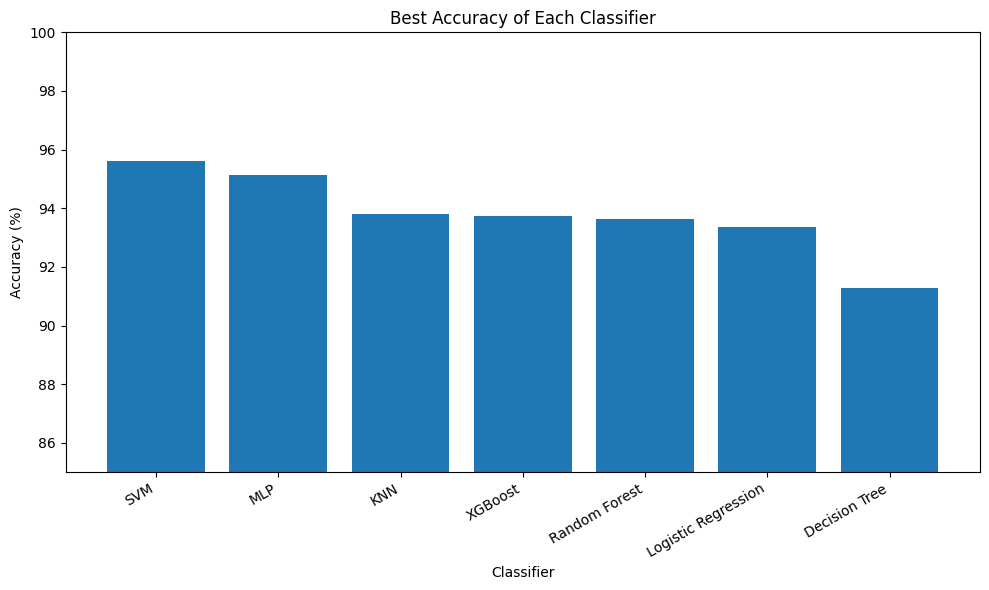

In [70]:
# =============================================================================
# BEST ACCURACY BY CLASSIFIER
# =============================================================================

plt.figure(figsize=(10, 6))

plt.bar(
    best_by_classifier["Classifier"],
    best_by_classifier["Accuracy (%)"]
)

plt.ylabel("Accuracy (%)")
plt.xlabel("Classifier")
plt.title("Best Accuracy of Each Classifier")

plt.xticks(
    rotation=30,
    ha="right"
)

plt.ylim(
    85,
    100
)

plt.tight_layout()
plt.show()

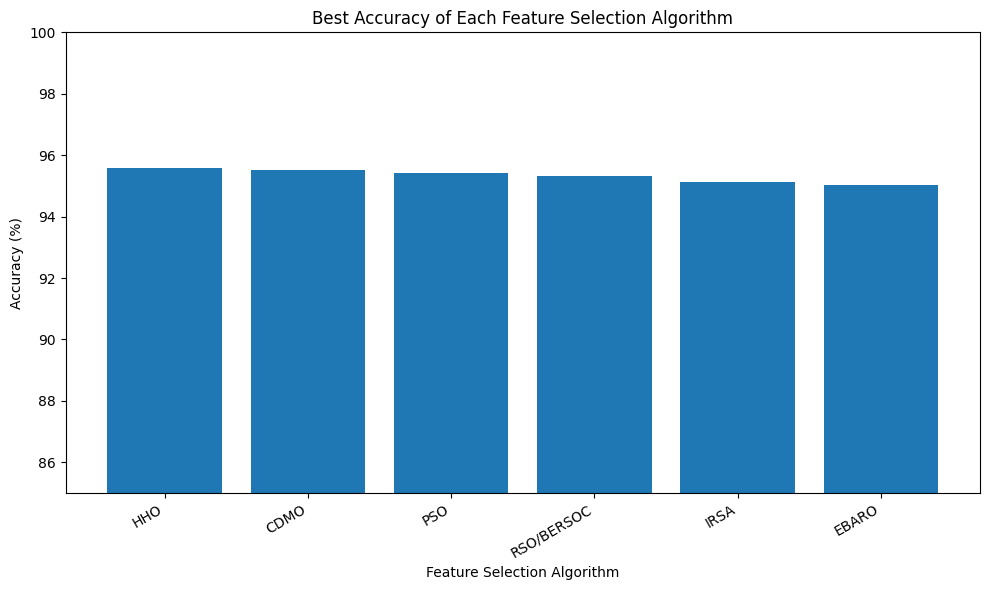

In [71]:
# =============================================================================
# BEST ACCURACY BY FEATURE SELECTOR
# =============================================================================

plt.figure(figsize=(10, 6))

plt.bar(
    best_by_optimizer["Feature Selector"],
    best_by_optimizer["Accuracy (%)"]
)

plt.ylabel("Accuracy (%)")
plt.xlabel("Feature Selection Algorithm")
plt.title("Best Accuracy of Each Feature Selection Algorithm")

plt.xticks(
    rotation=30,
    ha="right"
)

plt.ylim(
    85,
    100
)

plt.tight_layout()
plt.show()

In [72]:
# ============================================================
# STEP 9.1 — LOCATE C-NMC FINAL PHASE DATA
# ============================================================

import os

print("=" * 70)
print("STEP 9.1 — EXTERNAL TEST DATA")
print("=" * 70)

# Your main dataset path from the previous notebook
print("DATASET_PATH:")
print(DATASET_PATH)

# Testing-data directory
TESTING_PATH = os.path.join(
    DATASET_PATH,
    "testing_data"
)

print("\nTesting path:")
print(TESTING_PATH)

print("\nDoes testing_data exist?")
print(os.path.exists(TESTING_PATH))

print("\nContents of testing_data:")

if os.path.exists(TESTING_PATH):
    for item in os.listdir(TESTING_PATH):
        print(" -", item)
else:
    print("ERROR: testing_data folder not found.")

STEP 9.1 — EXTERNAL TEST DATA
DATASET_PATH:
/kaggle/input/datasets/kaviyam23adr085/leukumiaaaaa/cnmc/C-NMC_Leukemia

Testing path:
/kaggle/input/datasets/kaviyam23adr085/leukumiaaaaa/cnmc/C-NMC_Leukemia/testing_data

Does testing_data exist?
True

Contents of testing_data:
 - C-NMC_test_final_phase_data


In [73]:
# ============================================================
# STEP 9.2 — INSPECT EXTERNAL TEST IMAGES
# ============================================================

import os
from collections import Counter

EXTERNAL_TEST_PATH = os.path.join(
    TESTING_PATH,
    "C-NMC_test_final_phase_data"
)

print("=" * 70)
print("STEP 9.2 — EXTERNAL TEST IMAGE INSPECTION")
print("=" * 70)

print("External test path:")
print(EXTERNAL_TEST_PATH)

print("\nFolder exists:")
print(os.path.exists(EXTERNAL_TEST_PATH))


# ------------------------------------------------------------
# Find all image files
# ------------------------------------------------------------

image_extensions = {
    ".bmp",
    ".jpg",
    ".jpeg",
    ".png",
    ".tif",
    ".tiff"
}

external_image_paths = []

for root, dirs, files in os.walk(
    EXTERNAL_TEST_PATH
):

    for file in files:

        extension = os.path.splitext(
            file
        )[1].lower()

        if extension in image_extensions:

            external_image_paths.append(
                os.path.join(root, file)
            )


# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print(
    "\nTotal external images :",
    len(external_image_paths)
)


# Count file types
extensions_found = Counter(
    os.path.splitext(path)[1].lower()
    for path in external_image_paths
)

print("\nImage formats:")

for ext, count in extensions_found.items():

    print(
        f"{ext} : {count}"
    )


# ------------------------------------------------------------
# Show first 10 image paths
# ------------------------------------------------------------

print("\nFirst 10 images:")

for path in external_image_paths[:10]:

    print(
        " -",
        path
    )

STEP 9.2 — EXTERNAL TEST IMAGE INSPECTION
External test path:
/kaggle/input/datasets/kaviyam23adr085/leukumiaaaaa/cnmc/C-NMC_Leukemia/testing_data/C-NMC_test_final_phase_data

Folder exists:
True

Total external images : 2586

Image formats:
.bmp : 2586

First 10 images:
 - /kaggle/input/datasets/kaviyam23adr085/leukumiaaaaa/cnmc/C-NMC_Leukemia/testing_data/C-NMC_test_final_phase_data/518.bmp
 - /kaggle/input/datasets/kaviyam23adr085/leukumiaaaaa/cnmc/C-NMC_Leukemia/testing_data/C-NMC_test_final_phase_data/2037.bmp
 - /kaggle/input/datasets/kaviyam23adr085/leukumiaaaaa/cnmc/C-NMC_Leukemia/testing_data/C-NMC_test_final_phase_data/1307.bmp
 - /kaggle/input/datasets/kaviyam23adr085/leukumiaaaaa/cnmc/C-NMC_Leukemia/testing_data/C-NMC_test_final_phase_data/1048.bmp
 - /kaggle/input/datasets/kaviyam23adr085/leukumiaaaaa/cnmc/C-NMC_Leukemia/testing_data/C-NMC_test_final_phase_data/1399.bmp
 - /kaggle/input/datasets/kaviyam23adr085/leukumiaaaaa/cnmc/C-NMC_Leukemia/testing_data/C-NMC_test_final

In [74]:
# ============================================================
# STEP 9.3 — CHECK EXTERNAL IMAGE DIMENSIONS
# ============================================================

import cv2
import numpy as np
from collections import Counter

print("=" * 70)
print("STEP 9.3 — EXTERNAL IMAGE DIMENSION CHECK")
print("=" * 70)

image_sizes = []
invalid_images = []

for image_path in external_image_paths:

    img = cv2.imread(
        image_path,
        cv2.IMREAD_COLOR
    )

    if img is None:
        invalid_images.append(image_path)
        continue

    height, width = img.shape[:2]

    image_sizes.append(
        (width, height)
    )


# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print(
    "Images successfully read :",
    len(image_sizes)
)

print(
    "Invalid/unreadable images:",
    len(invalid_images)
)


# Count image dimensions
size_counts = Counter(
    image_sizes
)

print("\nImage dimensions:")

for size, count in size_counts.most_common():

    print(
        f"{size[0]} × {size[1]} : {count} images"
    )


# ------------------------------------------------------------
# Pixel statistics
# ------------------------------------------------------------

if image_sizes:

    widths = [
        size[0]
        for size in image_sizes
    ]

    heights = [
        size[1]
        for size in image_sizes
    ]

    print("\nDimension summary:")

    print(
        "Minimum width :",
        min(widths)
    )

    print(
        "Maximum width :",
        max(widths)
    )

    print(
        "Minimum height:",
        min(heights)
    )

    print(
        "Maximum height:",
        max(heights)
    )


# ------------------------------------------------------------
# Final check
# ------------------------------------------------------------

if len(invalid_images) == 0:

    print(
        "\n✓ All 2586 external images "
        "were read successfully."
    )

else:

    print(
        "\n⚠ Some images could not be read."
    )

STEP 9.3 — EXTERNAL IMAGE DIMENSION CHECK
Images successfully read : 2586
Invalid/unreadable images: 0

Image dimensions:
600 × 600 : 2586 images

Dimension summary:
Minimum width : 600
Maximum width : 600
Minimum height: 600
Maximum height: 600

✓ All 2586 external images were read successfully.


In [75]:
# ============================================================
# STEP 9.4 — PREPARE EXTERNAL IMAGES FOR ViT
# ============================================================

import torch
from torch.utils.data import Dataset, DataLoader

print("=" * 70)
print("STEP 9.4 — PREPARING EXTERNAL IMAGES FOR ViT")
print("=" * 70)


class ExternalViTDataset(Dataset):

    def __init__(self, image_paths, processor):

        self.image_paths = image_paths
        self.processor = processor

    def __len__(self):

        return len(self.image_paths)

    def __getitem__(self, index):

        image_path = self.image_paths[index]

        # Read 600 × 600 image
        image = cv2.imread(
            image_path,
            cv2.IMREAD_COLOR
        )

        if image is None:

            raise ValueError(
                f"Unable to read image: {image_path}"
            )

        # BGR → RGB
        image = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )

        # Use the SAME processor used for ViT
        processed = self.processor(
            images=image,
            return_tensors="pt"
        )

        pixel_values = processed[
            "pixel_values"
        ].squeeze(0)

        return (
            pixel_values,
            image_path
        )


# ------------------------------------------------------------
# Create dataset
# ------------------------------------------------------------

external_dataset = ExternalViTDataset(
    image_paths=external_image_paths,
    processor=image_processor
)


# ------------------------------------------------------------
# Create DataLoader
# ------------------------------------------------------------

EXTERNAL_BATCH_SIZE = 32

external_loader = DataLoader(
    external_dataset,
    batch_size=EXTERNAL_BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)


print("Total images :", len(external_dataset))

print(
    "Batch size   :",
    EXTERNAL_BATCH_SIZE
)

print(
    "Total batches:",
    len(external_loader)
)


# ------------------------------------------------------------
# Check one batch
# ------------------------------------------------------------

sample_pixels, sample_paths = next(
    iter(external_loader)
)

print("\nFirst batch shape:")
print(
    "Pixel values:",
    sample_pixels.shape
)

print(
    "Number of paths:",
    len(sample_paths)
)


# ------------------------------------------------------------
# Expected ViT input
# ------------------------------------------------------------

if sample_pixels.shape[1:] == (3, 224, 224):

    print(
        "\n✓ External images are correctly "
        "prepared for ViT."
    )

else:

    print(
        "\n⚠ Check ViT input shape:",
        sample_pixels.shape
    )

STEP 9.4 — PREPARING EXTERNAL IMAGES FOR ViT
Total images : 2586
Batch size   : 32
Total batches: 81

First batch shape:
Pixel values: torch.Size([32, 3, 224, 224])
Number of paths: 32

✓ External images are correctly prepared for ViT.


In [76]:
# ============================================================
# STEP 9.5 — EXTRACT 768-D ViT FEATURES
# ============================================================

import numpy as np
import torch
from tqdm.auto import tqdm

print("=" * 70)
print("STEP 9.5 — EXTERNAL ViT FEATURE EXTRACTION")
print("=" * 70)

# Use the trained ViT model already available in the notebook
model.eval()

external_features_list = []
external_paths_ordered = []

with torch.no_grad():

    for pixel_values, image_paths in tqdm(
        external_loader,
        desc="Extracting ViT features"
    ):

        pixel_values = pixel_values.to(
            device,
            non_blocking=True
        )

        # Forward pass through the trained ViT
        outputs = model.backbone(
            pixel_values=pixel_values
        )

        # CLS token representation
        # ViT-Base → 768 features
        batch_features = (
            outputs.last_hidden_state[:, 0, :]
        )

        external_features_list.append(
            batch_features.cpu().numpy()
        )

        external_paths_ordered.extend(
            image_paths
        )


# Combine all batches
external_features = np.concatenate(
    external_features_list,
    axis=0
)


print("\n" + "=" * 70)
print("EXTERNAL ViT FEATURE EXTRACTION COMPLETED")
print("=" * 70)

print(
    "Number of images :",
    len(external_features)
)

print(
    "Feature shape    :",
    external_features.shape
)

print(
    "Expected shape   :",
    (2586, 768)
)

print(
    "Feature dimension:",
    external_features.shape[1]
)

print(
    "Image paths      :",
    len(external_paths_ordered)
)


# Final validation
if external_features.shape == (2586, 768):

    print(
        "\n✓ SUCCESS: All 2586 images "
        "have 768 ViT features."
    )

else:

    print(
        "\n⚠ Check the extracted feature shape."
    )

STEP 9.5 — EXTERNAL ViT FEATURE EXTRACTION


Extracting ViT features:   0%|          | 0/81 [00:00<?, ?it/s]


EXTERNAL ViT FEATURE EXTRACTION COMPLETED
Number of images : 2586
Feature shape    : (2586, 768)
Expected shape   : (2586, 768)
Feature dimension: 768
Image paths      : 2586

✓ SUCCESS: All 2586 images have 768 ViT features.


In [77]:
# ============================================================
# STEP 9.6 — APPLY EXISTING HHO FEATURE MASK
# ============================================================

import numpy as np

print("=" * 70)
print("STEP 9.6 — APPLYING EXISTING HHO MASK")
print("=" * 70)

# Use the HHO mask obtained in Step 8
external_hho_mask = np.asarray(
    hho_best_mask
).astype(bool)

print(
    "HHO mask shape       :",
    external_hho_mask.shape
)

print(
    "Total ViT features  :",
    len(external_hho_mask)
)

print(
    "Selected HHO features:",
    external_hho_mask.sum()
)


# ------------------------------------------------------------
# Verify mask
# ------------------------------------------------------------

if len(external_hho_mask) != 768:

    raise ValueError(
        f"Expected HHO mask of 768 features, "
        f"but got {len(external_hho_mask)}"
    )


# ------------------------------------------------------------
# Apply SAME mask to external 768-D features
# ------------------------------------------------------------

external_hho_features = (
    external_features[
        :,
        external_hho_mask
    ]
)


print("\nExternal feature transformation:")

print(
    "Before HHO :",
    external_features.shape
)

print(
    "After HHO  :",
    external_hho_features.shape
)


# ------------------------------------------------------------
# Final check
# ------------------------------------------------------------

if external_hho_features.shape[1] == 300:

    print(
        "\n✓ SUCCESS: External data reduced "
        "from 768 to 300 features."
    )

else:

    print(
        "\n⚠ WARNING: HHO selected",
        external_hho_features.shape[1],
        "features instead of 300."
    )

STEP 9.6 — APPLYING EXISTING HHO MASK
HHO mask shape       : (768,)
Total ViT features  : 768
Selected HHO features: 300

External feature transformation:
Before HHO : (2586, 768)
After HHO  : (2586, 300)

✓ SUCCESS: External data reduced from 768 to 300 features.


In [78]:
# ============================================================
# STEP 9.7 — PREPARE FINAL HHO + SVM MODEL
# ============================================================

from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
import numpy as np

print("=" * 70)
print("STEP 9.7 — FINAL HHO + SVM MODEL")
print("=" * 70)


# ------------------------------------------------------------
# 1. Combine existing TRAIN + VALIDATION data
# ------------------------------------------------------------

X_internal = np.concatenate(
    [
        train_features,
        val_features
    ],
    axis=0
)

y_internal = np.concatenate(
    [
        train_labels,
        val_labels
    ],
    axis=0
)


print("Internal feature shape :",
      X_internal.shape)

print("Internal label shape   :",
      y_internal.shape)


# ------------------------------------------------------------
# 2. Apply SAME HHO mask
# ------------------------------------------------------------

X_internal_hho = X_internal[
    :,
    external_hho_mask
]

print(
    "\nAfter HHO feature selection:",
    X_internal_hho.shape
)


# ------------------------------------------------------------
# 3. Scale using INTERNAL data only
# ------------------------------------------------------------

final_scaler = StandardScaler()

X_internal_scaled = (
    final_scaler.fit_transform(
        X_internal_hho
    )
)

X_external_scaled = (
    final_scaler.transform(
        external_hho_features
    )
)


print(
    "\nScaled internal shape :",
    X_internal_scaled.shape
)

print(
    "Scaled external shape:",
    X_external_scaled.shape
)


# ------------------------------------------------------------
# 4. Create final SVM
# ------------------------------------------------------------

final_svm = SVC(

    kernel="rbf",

    C=10,

    gamma="scale",

    probability=True,

    random_state=42
)


# ------------------------------------------------------------
# 5. Train ONLY on internal data
# ------------------------------------------------------------

final_svm.fit(
    X_internal_scaled,
    y_internal
)


print("\n" + "=" * 70)
print("✓ FINAL HHO + SVM MODEL TRAINED")
print("=" * 70)

print("Feature extractor : ViT")
print("Original features : 768")
print("HHO features      : 300")
print("Classifier         : SVM")
print("Kernel             : RBF")
print("C                  : 10")

print(
    "\n✓ External 2586 images were NOT used for training."
)
print(
    "✓ They remain completely unseen for Step 9."
)

STEP 9.7 — FINAL HHO + SVM MODEL
Internal feature shape : (10661, 768)
Internal label shape   : (10661,)

After HHO feature selection: (10661, 300)

Scaled internal shape : (10661, 300)
Scaled external shape: (2586, 300)

✓ FINAL HHO + SVM MODEL TRAINED
Feature extractor : ViT
Original features : 768
HHO features      : 300
Classifier         : SVM
Kernel             : RBF
C                  : 10

✓ External 2586 images were NOT used for training.
✓ They remain completely unseen for Step 9.


In [80]:
# ============================================================
# STEP 9.8 — CORRECT EXTERNAL PROBABILITY TABLE
# ============================================================

print("=" * 70)
print("STEP 9.8 — CORRECTING CLASS PROBABILITIES")
print("=" * 70)

# SVM classes:
# 0 = HEM
# 1 = ALL

hem_probability = (
    external_probabilities[:, 0] * 100
)

all_probability = (
    external_probabilities[:, 1] * 100
)

# Create corrected result table
external_results = pd.DataFrame({

    "Image":
        [
            os.path.basename(path)
            for path in external_paths_ordered
        ],

    "Image_Path":
        external_paths_ordered,

    "Prediction":
        external_class_names,

    "HEM_Probability (%)":
        hem_probability,

    "ALL_Probability (%)":
        all_probability
})


# ------------------------------------------------------------
# Check probability sum
# ------------------------------------------------------------

probability_sum = (
    external_results["HEM_Probability (%)"]
    +
    external_results["ALL_Probability (%)"]
)

print("\nProbability check:")

print(
    "Minimum probability sum :",
    probability_sum.min()
)

print(
    "Maximum probability sum :",
    probability_sum.max()
)


# ------------------------------------------------------------
# Prediction distribution
# ------------------------------------------------------------

print("\nPrediction distribution:")

print(
    external_results[
        "Prediction"
    ].value_counts()
)


# ------------------------------------------------------------
# Display first 10
# ------------------------------------------------------------

print("\nFirst 10 predictions:")

display(
    external_results.head(10)
)


# ------------------------------------------------------------
# Final check
# ------------------------------------------------------------

if np.allclose(
    probability_sum,
    100.0,
    atol=0.01
):

    print(
        "\n✓ Probability check passed."
    )

    print(
        "✓ HEM probability + ALL probability = 100%"
    )

else:

    print(
        "\n⚠ Probability check failed."
    )

STEP 9.8 — CORRECTING CLASS PROBABILITIES

Probability check:
Minimum probability sum : 99.99999999999996
Maximum probability sum : 100.00000000000004

Prediction distribution:
Prediction
ALL    1432
HEM    1154
Name: count, dtype: int64

First 10 predictions:


,Image,Image_Path,Prediction,HEM_Probability (%),ALL_Probability (%)
0,518.bmp,/kaggle/input/datasets/kaviyam23adr085/leukumi...,ALL,2.425091,97.574909
1,2037.bmp,/kaggle/input/datasets/kaviyam23adr085/leukumi...,ALL,4.169882,95.830118
2,1307.bmp,/kaggle/input/datasets/kaviyam23adr085/leukumi...,HEM,50.511012,49.488988
3,1048.bmp,/kaggle/input/datasets/kaviyam23adr085/leukumi...,HEM,99.789051,0.210949
4,1399.bmp,/kaggle/input/datasets/kaviyam23adr085/leukumi...,ALL,0.000017,99.999983
5,1661.bmp,/kaggle/input/datasets/kaviyam23adr085/leukumi...,ALL,0.325242,99.674758
6,1577.bmp,/kaggle/input/datasets/kaviyam23adr085/leukumi...,ALL,7.382971,92.617029
7,665.bmp,/kaggle/input/datasets/kaviyam23adr085/leukumi...,ALL,11.539895,88.460105
8,1212.bmp,/kaggle/input/datasets/kaviyam23adr085/leukumi...,ALL,7.867540,92.132460
9,907.bmp,/kaggle/input/datasets/kaviyam23adr085/leukumi...,HEM,97.624853,2.375147



✓ Probability check passed.
✓ HEM probability + ALL probability = 100%


In [81]:
# ============================================================
# STEP 9.9 — SAVE EXTERNAL TEST RESULTS
# ============================================================

print("=" * 70)
print("STEP 9.9 — SAVING EXTERNAL TEST RESULTS")
print("=" * 70)


# ------------------------------------------------------------
# Save complete prediction table
# ------------------------------------------------------------

OUTPUT_FILE = (
    "/kaggle/working/"
    "C_NMC_Final_Phase_HHO_SVM_Predictions.csv"
)

external_results.to_csv(
    OUTPUT_FILE,
    index=False
)


# ------------------------------------------------------------
# Calculate prediction counts
# ------------------------------------------------------------

total_images = len(
    external_results
)

all_count = (
    external_results["Prediction"]
    .eq("ALL")
    .sum()
)

hem_count = (
    external_results["Prediction"]
    .eq("HEM")
    .sum()
)


all_percentage = (
    all_count / total_images * 100
)

hem_percentage = (
    hem_count / total_images * 100
)


# ------------------------------------------------------------
# Display final summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("EXTERNAL TEST SUMMARY")
print("=" * 70)

print(
    f"Total images        : {total_images}"
)

print(
    f"Predicted ALL       : {all_count}"
)

print(
    f"Predicted HEM       : {hem_count}"
)

print(
    f"ALL percentage      : {all_percentage:.2f}%"
)

print(
    f"HEM percentage      : {hem_percentage:.2f}%"
)

print(
    f"HHO selected        : {external_hho_features.shape[1]} features"
)

print(
    "Classifier           : SVM"
)

print(
    "Feature extractor    : ViT"
)

print("\n✓ Prediction file saved:")
print(OUTPUT_FILE)

STEP 9.9 — SAVING EXTERNAL TEST RESULTS

EXTERNAL TEST SUMMARY
Total images        : 2586
Predicted ALL       : 1432
Predicted HEM       : 1154
ALL percentage      : 55.38%
HEM percentage      : 44.62%
HHO selected        : 300 features
Classifier           : SVM
Feature extractor    : ViT

✓ Prediction file saved:
/kaggle/working/C_NMC_Final_Phase_HHO_SVM_Predictions.csv


In [82]:
# ============================================================
# STEP 10.1 — CHECK FINAL MODEL VARIABLES
# ============================================================

print("=" * 70)
print("STEP 10.1 — EXPLAINABILITY SETUP CHECK")
print("=" * 70)

print("\nFinal SVM:")
print(type(final_svm))

print("\nFinal HHO mask:")
print("Shape :", hho_best_mask.shape)
print("Selected features :", hho_best_mask.sum())

print("\nExternal features:")
print("Shape :", external_features.shape)

print("\nExternal HHO features:")
print("Shape :", external_hho_features.shape)

print("\nExternal predictions:")
print("Shape :", external_predictions.shape)

print("\nExternal results:")
print("Rows :", len(external_results))

STEP 10.1 — EXPLAINABILITY SETUP CHECK

Final SVM:
<class 'sklearn.svm._classes.SVC'>

Final HHO mask:
Shape : (768,)
Selected features : 300

External features:
Shape : (2586, 768)

External HHO features:
Shape : (2586, 300)

External predictions:
Shape : (2586,)

External results:
Rows : 2586


In [83]:
# ============================================================
# STEP 10.2 — SELECT IMAGE FOR EXPLAINABILITY
# ============================================================

print("=" * 70)
print("STEP 10.2 — SELECTING IMAGE FOR EXPLAINABILITY")
print("=" * 70)

# Select first external image
EXPLAIN_INDEX = 0

explain_image_path = external_paths_ordered[
    EXPLAIN_INDEX
]

# Prediction
explain_prediction = external_results.iloc[
    EXPLAIN_INDEX
]["Prediction"]

# Probabilities
explain_hem_probability = external_results.iloc[
    EXPLAIN_INDEX
]["HEM_Probability (%)"]

explain_all_probability = external_results.iloc[
    EXPLAIN_INDEX
]["ALL_Probability (%)"]


print("\nImage:")
print(explain_image_path)

print("\nPrediction:")
print(explain_prediction)

print(
    f"\nHEM Probability : "
    f"{explain_hem_probability:.2f}%"
)

print(
    f"ALL Probability : "
    f"{explain_all_probability:.2f}%"
)

print("\n" + "=" * 70)
print("✓ IMAGE SELECTED FOR EXPLAINABILITY")
print("=" * 70)

STEP 10.2 — SELECTING IMAGE FOR EXPLAINABILITY

Image:
/kaggle/input/datasets/kaviyam23adr085/leukumiaaaaa/cnmc/C-NMC_Leukemia/testing_data/C-NMC_test_final_phase_data/518.bmp

Prediction:
ALL

HEM Probability : 2.43%
ALL Probability : 97.57%

✓ IMAGE SELECTED FOR EXPLAINABILITY


In [84]:
# ============================================================
# STEP 10.3 — CHECK ViT ATTENTION OUTPUT
# ============================================================

print("=" * 70)
print("STEP 10.3 — ViT ATTENTION CHECK")
print("=" * 70)

# Check the existing ViT backbone
print("\nViT backbone:")
print(type(model.backbone))

# Check whether attention output is enabled
print("\nOutput attentions setting:")

if hasattr(model.backbone.config, "output_attentions"):

    print(
        "output_attentions =",
        model.backbone.config.output_attentions
    )

else:

    print(
        "Could not find output_attentions setting."
    )


# Display basic ViT configuration
print("\nViT configuration:")

print(
    "Hidden size :",
    model.backbone.config.hidden_size
)

print(
    "Num layers  :",
    model.backbone.config.num_hidden_layers
)

print(
    "Num heads   :",
    model.backbone.config.num_attention_heads
)

print(
    "Image size  :",
    model.backbone.config.image_size
)

print(
    "Patch size  :",
    model.backbone.config.patch_size
)

STEP 10.3 — ViT ATTENTION CHECK

ViT backbone:
<class 'transformers.models.vit.modeling_vit.ViTModel'>

Output attentions setting:
output_attentions = False

ViT configuration:
Hidden size : 768
Num layers  : 12
Num heads   : 12
Image size  : 224
Patch size  : 16


In [86]:
# ============================================================
# STEP 10.4 — ENABLE ViT ATTENTION OUTPUT
# ============================================================

print("=" * 70)
print("STEP 10.4 — ENABLING ViT ATTENTION")
print("=" * 70)

# Change SDPA → EAGER attention
model.backbone.set_attn_implementation("eager")

# Now enable attention outputs
model.backbone.config.output_attentions = True

# Evaluation mode
model.eval()

print(
    "Attention implementation:",
    model.backbone.config._attn_implementation
)

print(
    "output_attentions:",
    model.backbone.config.output_attentions
)

print("\n✓ Eager attention enabled.")
print("✓ Attention outputs enabled.")
print("✓ No retraining performed.")

STEP 10.4 — ENABLING ViT ATTENTION
Attention implementation: eager
output_attentions: True

✓ Eager attention enabled.
✓ Attention outputs enabled.
✓ No retraining performed.


In [87]:
# ============================================================
# STEP 10.5 — TEST ViT ATTENTION OUTPUT
# ============================================================

print("=" * 70)
print("STEP 10.5 — TESTING ViT ATTENTION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Read the selected image
# ------------------------------------------------------------

attention_image = cv2.imread(
    explain_image_path,
    cv2.IMREAD_COLOR
)

if attention_image is None:
    raise ValueError(
        f"Could not read image:\n{explain_image_path}"
    )

# BGR → RGB
attention_image = cv2.cvtColor(
    attention_image,
    cv2.COLOR_BGR2RGB
)


# ------------------------------------------------------------
# 2. Process image using the SAME ViT processor
# ------------------------------------------------------------

attention_inputs = image_processor(
    images=attention_image,
    return_tensors="pt"
)

attention_inputs = {
    key: value.to(device)
    for key, value in attention_inputs.items()
}


# ------------------------------------------------------------
# 3. Run ViT with attention output
# ------------------------------------------------------------

model.eval()

with torch.no_grad():

    attention_output = model.backbone(
        **attention_inputs,
        output_attentions=True
    )


# ------------------------------------------------------------
# 4. Check attention tensors
# ------------------------------------------------------------

print("\nViT output type:")
print(type(attention_output))

print("\nNumber of attention layers:")

if attention_output.attentions is not None:

    print(
        len(attention_output.attentions)
    )

else:

    print("None")


# ------------------------------------------------------------
# 5. Print attention shape
# ------------------------------------------------------------

if attention_output.attentions is not None:

    first_attention = (
        attention_output.attentions[0]
    )

    print("\nFirst attention layer shape:")
    print(first_attention.shape)

    print(
        "\nExpected format:"
        " [batch, heads, tokens, tokens]"
    )

    print("\n✓ ViT attention tensors successfully obtained.")

else:

    raise RuntimeError(
        "Attention output is None. "
        "ViT attention was not returned."
    )

STEP 10.5 — TESTING ViT ATTENTION

ViT output type:
<class 'transformers.modeling_outputs.BaseModelOutputWithPooling'>

Number of attention layers:
12

First attention layer shape:
torch.Size([1, 12, 197, 197])

Expected format: [batch, heads, tokens, tokens]

✓ ViT attention tensors successfully obtained.


STEP 10.6 — GENERATING ViT ATTENTION MAP
Number of layers: 12
Attention shape: torch.Size([1, 12, 197, 197])

Stacked attention shape: torch.Size([12, 1, 12, 197, 197])
Mean attention shape: torch.Size([197, 197])
CLS attention shape: torch.Size([196])
Attention map shape: (14, 14)


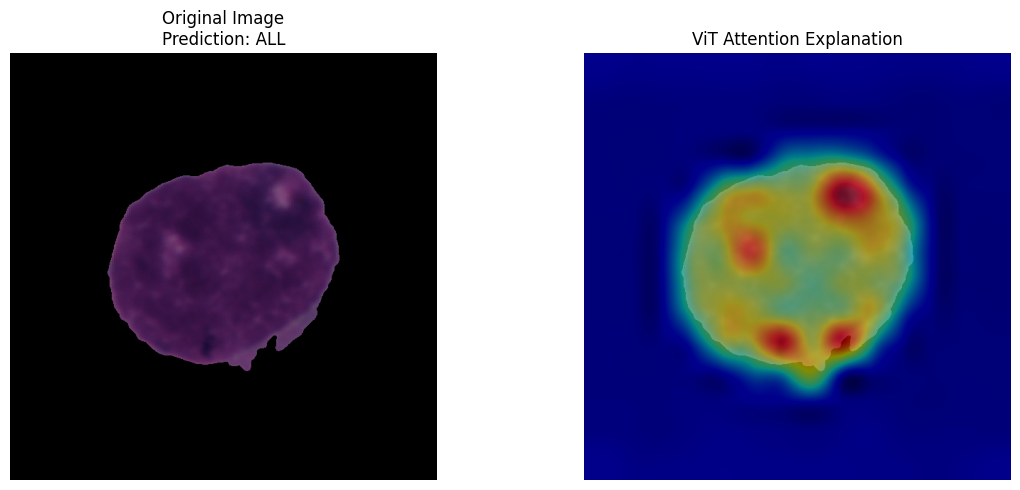


✓ ViT attention map generated successfully.


In [88]:
# ============================================================
# STEP 10.6 — GENERATE ViT ATTENTION MAP
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import cv2

print("=" * 70)
print("STEP 10.6 — GENERATING ViT ATTENTION MAP")
print("=" * 70)


# ------------------------------------------------------------
# 1. Get attention tensors from all layers
# ------------------------------------------------------------

attentions = attention_output.attentions

print(
    "Number of layers:",
    len(attentions)
)

print(
    "Attention shape:",
    attentions[0].shape
)


# ------------------------------------------------------------
# 2. Stack all layers
# ------------------------------------------------------------

# Shape:
# [layers, batch, heads, tokens, tokens]

attention_stack = torch.stack(
    attentions
)

print(
    "\nStacked attention shape:",
    attention_stack.shape
)


# ------------------------------------------------------------
# 3. Average across layers and heads
# ------------------------------------------------------------

# Remove batch dimension
attention_stack = attention_stack[:, 0]

# Average:
# layers + heads
mean_attention = attention_stack.mean(
    dim=(0, 1)
)

print(
    "Mean attention shape:",
    mean_attention.shape
)


# ------------------------------------------------------------
# 4. Take CLS-token attention
# ------------------------------------------------------------

# CLS token = token 0
# Image patches = tokens 1:197

cls_attention = mean_attention[
    0,
    1:
]

print(
    "CLS attention shape:",
    cls_attention.shape
)


# ------------------------------------------------------------
# 5. Convert 196 patches → 14 × 14
# ------------------------------------------------------------

num_patches = int(
    np.sqrt(
        cls_attention.shape[0]
    )
)

attention_map = (
    cls_attention
    .reshape(
        num_patches,
        num_patches
    )
    .cpu()
    .numpy()
)


print(
    "Attention map shape:",
    attention_map.shape
)


# ------------------------------------------------------------
# 6. Normalize attention map
# ------------------------------------------------------------

attention_map = (
    attention_map -
    attention_map.min()
)

attention_map = (
    attention_map /
    (attention_map.max() + 1e-8)
)


# ------------------------------------------------------------
# 7. Resize to original image size
# ------------------------------------------------------------

original_image = cv2.imread(
    explain_image_path,
    cv2.IMREAD_COLOR
)

original_image = cv2.cvtColor(
    original_image,
    cv2.COLOR_BGR2RGB
)

height, width = (
    original_image.shape[:2]
)

attention_resized = cv2.resize(
    attention_map,
    (width, height),
    interpolation=cv2.INTER_CUBIC
)


# ------------------------------------------------------------
# 8. Display original + attention map
# ------------------------------------------------------------

plt.figure(
    figsize=(12, 5)
)

plt.subplot(1, 2, 1)

plt.imshow(
    original_image
)

plt.title(
    f"Original Image\nPrediction: {explain_prediction}"
)

plt.axis("off")


plt.subplot(1, 2, 2)

plt.imshow(
    original_image
)

plt.imshow(
    attention_resized,
    alpha=0.55,
    cmap="jet"
)

plt.title(
    "ViT Attention Explanation"
)

plt.axis("off")

plt.tight_layout()

plt.show()


print(
    "\n✓ ViT attention map generated successfully."
)

STEP 10.7 — FINAL EXPLAINABILITY RESULT


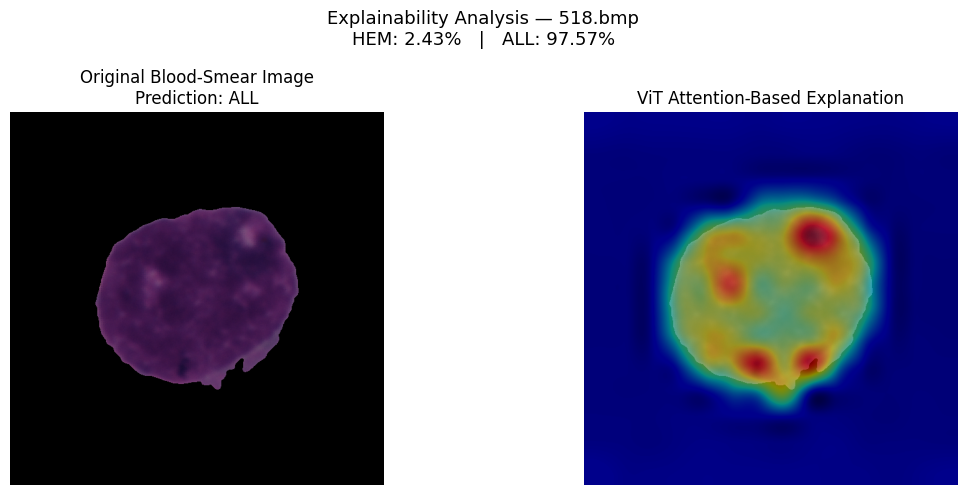


EXPLAINABILITY SUMMARY
Image       : 518.bmp
Prediction  : ALL
HEM         : 2.43%
ALL         : 97.57%
Explanation : ViT attention-based visualization

✓ Explainability result generated successfully.


In [89]:
# ============================================================
# STEP 10.7 — FINAL EXPLAINABILITY RESULT
# ============================================================

print("=" * 70)
print("STEP 10.7 — FINAL EXPLAINABILITY RESULT")
print("=" * 70)

# ------------------------------------------------------------
# Create side-by-side explanation
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 5)
)


# ------------------------------------------------------------
# Original image
# ------------------------------------------------------------

axes[0].imshow(
    original_image
)

axes[0].set_title(
    f"Original Blood-Smear Image\n"
    f"Prediction: {explain_prediction}"
)

axes[0].axis("off")


# ------------------------------------------------------------
# Attention explanation
# ------------------------------------------------------------

axes[1].imshow(
    original_image
)

axes[1].imshow(
    attention_resized,
    alpha=0.55,
    cmap="jet"
)

axes[1].set_title(
    "ViT Attention-Based Explanation"
)

axes[1].axis("off")


# ------------------------------------------------------------
# Overall title
# ------------------------------------------------------------

fig.suptitle(
    f"Explainability Analysis — {os.path.basename(explain_image_path)}\n"
    f"HEM: {explain_hem_probability:.2f}%   |   "
    f"ALL: {explain_all_probability:.2f}%",
    fontsize=13
)

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# Print explanation summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("EXPLAINABILITY SUMMARY")
print("=" * 70)

print(
    "Image       :",
    os.path.basename(explain_image_path)
)

print(
    "Prediction  :",
    explain_prediction
)

print(
    f"HEM         : "
    f"{explain_hem_probability:.2f}%"
)

print(
    f"ALL         : "
    f"{explain_all_probability:.2f}%"
)

print(
    "Explanation : ViT attention-based visualization"
)

print(
    "\n✓ Explainability result generated successfully."
)

In [90]:
# ============================================================
# STEP 10.8 — IDENTIFY ViT GRAD-CAM TARGET LAYER
# ============================================================

print("=" * 70)
print("STEP 10.8 — ViT GRAD-CAM TARGET LAYER")
print("=" * 70)

# Put model in evaluation mode
model.eval()

# Access ViT encoder
vit_encoder = model.backbone.encoder

print("\nViT encoder:")
print(type(vit_encoder))

# Number of Transformer layers
num_layers = len(vit_encoder.layer)

print(
    "\nNumber of Transformer layers:",
    num_layers
)

# Select final Transformer block
target_layer = vit_encoder.layer[-1]

print(
    "\nSelected target layer:"
)

print(target_layer)

print("\n" + "=" * 70)
print("✓ FINAL ViT TRANSFORMER LAYER SELECTED")
print("=" * 70)

print(
    "\nThis layer will be used for "
    "ViT-compatible Grad-CAM."
)

STEP 10.8 — ViT GRAD-CAM TARGET LAYER

ViT encoder:
<class 'transformers.models.vit.modeling_vit.ViTEncoder'>

Number of Transformer layers: 12

Selected target layer:
ViTLayer(
  (attention): ViTAttention(
    (attention): ViTSelfAttention(
      (query): Linear(in_features=768, out_features=768, bias=True)
      (key): Linear(in_features=768, out_features=768, bias=True)
      (value): Linear(in_features=768, out_features=768, bias=True)
    )
    (output): ViTSelfOutput(
      (dense): Linear(in_features=768, out_features=768, bias=True)
      (dropout): Dropout(p=0.0, inplace=False)
    )
  )
  (intermediate): ViTIntermediate(
    (dense): Linear(in_features=768, out_features=3072, bias=True)
    (intermediate_act_fn): GELUActivation()
  )
  (output): ViTOutput(
    (dense): Linear(in_features=3072, out_features=768, bias=True)
    (dropout): Dropout(p=0.0, inplace=False)
  )
  (layernorm_before): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
  (layernorm_after): LayerNorm(

In [91]:
# ============================================================
# STEP 10.9 — REGISTER ViT GRAD-CAM HOOKS
# ============================================================

print("=" * 70)
print("STEP 10.9 — REGISTERING ViT GRAD-CAM HOOKS")
print("=" * 70)

# Storage for activations and gradients
gradcam_activations = {}
gradcam_gradients = {}


# ------------------------------------------------------------
# Forward hook
# ------------------------------------------------------------

def forward_hook(module, inputs, output):

    # ViTLayer output is usually a tuple
    if isinstance(output, tuple):

        gradcam_activations["value"] = output[0]

    else:

        gradcam_activations["value"] = output


# ------------------------------------------------------------
# Backward hook
# ------------------------------------------------------------

def backward_hook(module, grad_input, grad_output):

    # Gradient corresponding to layer output
    if isinstance(grad_output, tuple):

        gradcam_gradients["value"] = grad_output[0]

    else:

        gradcam_gradients["value"] = grad_output


# ------------------------------------------------------------
# Register hooks on final ViT transformer layer
# ------------------------------------------------------------

forward_handle = target_layer.register_forward_hook(
    forward_hook
)

backward_handle = target_layer.register_full_backward_hook(
    backward_hook
)


print("\nTarget layer:")
print(type(target_layer))

print("\nForward hook:")
print("✓ Registered")

print("\nBackward hook:")
print("✓ Registered")

print("\n" + "=" * 70)
print("✓ ViT Grad-CAM hooks are ready")
print("=" * 70)

STEP 10.9 — REGISTERING ViT GRAD-CAM HOOKS

Target layer:
<class 'transformers.models.vit.modeling_vit.ViTLayer'>

Forward hook:
✓ Registered

Backward hook:
✓ Registered

✓ ViT Grad-CAM hooks are ready


In [93]:
# ============================================================
# STEP 10.10 — CAPTURE ViT GRAD-CAM DATA
# CORRECTED FOR YOUR MODEL OUTPUT
# ============================================================

print("=" * 70)
print("STEP 10.10 — CAPTURING GRAD-CAM DATA")
print("=" * 70)


# ------------------------------------------------------------
# 1. Clear previous Grad-CAM values
# ------------------------------------------------------------

gradcam_activations.clear()
gradcam_gradients.clear()


# ------------------------------------------------------------
# 2. Read selected image
# ------------------------------------------------------------

gradcam_image = cv2.imread(
    explain_image_path,
    cv2.IMREAD_COLOR
)

if gradcam_image is None:

    raise ValueError(
        f"Could not read image:\n{explain_image_path}"
    )


# BGR → RGB
gradcam_image = cv2.cvtColor(
    gradcam_image,
    cv2.COLOR_BGR2RGB
)


# ------------------------------------------------------------
# 3. Process using SAME ViT processor
# ------------------------------------------------------------

gradcam_inputs = image_processor(
    images=gradcam_image,
    return_tensors="pt"
)

gradcam_inputs = {
    key: value.to(device)
    for key, value in gradcam_inputs.items()
}


# ------------------------------------------------------------
# 4. Clear gradients
# ------------------------------------------------------------

model.zero_grad(set_to_none=True)


# ------------------------------------------------------------
# 5. Forward pass
# ------------------------------------------------------------

# IMPORTANT:
# Do NOT use torch.no_grad()
# because Grad-CAM needs gradients.

gradcam_output = model(
    **gradcam_inputs
)


# ------------------------------------------------------------
# 6. Your model returns logits directly
# ------------------------------------------------------------

logits = gradcam_output


print("\nLogits shape:")
print(logits.shape)

print("\nLogits:")
print(logits)


# ------------------------------------------------------------
# 7. Get predicted class
# ------------------------------------------------------------

predicted_class_index = torch.argmax(
    logits,
    dim=1
).item()


print(
    "\nPredicted class index:",
    predicted_class_index
)


# ------------------------------------------------------------
# 8. Get target class score
# ------------------------------------------------------------

target_score = logits[
    0,
    predicted_class_index
]


print(
    "Target score:",
    target_score.item()
)


# ------------------------------------------------------------
# 9. Backpropagate
# ------------------------------------------------------------

target_score.backward()


# ------------------------------------------------------------
# 10. Check captured activations
# ------------------------------------------------------------

print("\nActivation captured:")

if "value" in gradcam_activations:

    print(
        gradcam_activations["value"].shape
    )

else:

    print("NO")


# ------------------------------------------------------------
# 11. Check captured gradients
# ------------------------------------------------------------

print("\nGradient captured:")

if "value" in gradcam_gradients:

    print(
        gradcam_gradients["value"].shape
    )

else:

    print("NO")


# ------------------------------------------------------------
# 12. Final verification
# ------------------------------------------------------------

if (
    "value" in gradcam_activations
    and
    "value" in gradcam_gradients
):

    print(
        "\n✓ SUCCESS: ViT activations and "
        "gradients captured."
    )

else:

    print(
        "\n⚠ Grad-CAM data was not captured."
    )

STEP 10.10 — CAPTURING GRAD-CAM DATA

Logits shape:
torch.Size([1, 2])

Logits:
tensor([[-1.5719,  1.6709]], device='cuda:0', grad_fn=<AddmmBackward0>)

Predicted class index: 1
Target score: 1.6708862781524658

Activation captured:
torch.Size([1, 197, 768])

Gradient captured:
torch.Size([1, 197, 768])

✓ SUCCESS: ViT activations and gradients captured.


STEP 10.11 — GENERATING ViT GRAD-CAM
Activations shape:
torch.Size([1, 197, 768])

Gradients shape:
torch.Size([1, 197, 768])

Patch activations:
torch.Size([196, 768])

Patch gradients:
torch.Size([196, 768])

Grad-CAM weights:
torch.Size([196])

Grad-CAM patch values:
torch.Size([196])

Number of patches per side: 14
Grad-CAM map shape: (14, 14)


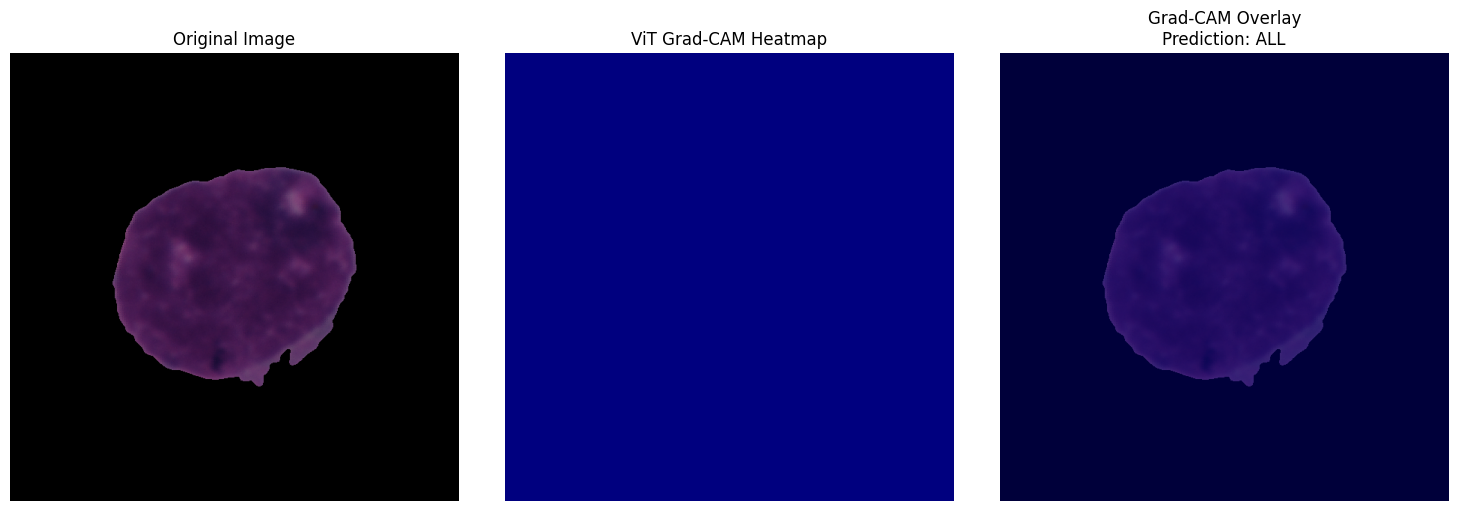


✓ ViT Grad-CAM GENERATED SUCCESSFULLY
Prediction : ALL
ALL probability : 97.57%
HEM probability : 2.43%


In [94]:
# ============================================================
# STEP 10.11 — GENERATE ViT GRAD-CAM HEATMAP
# ============================================================

print("=" * 70)
print("STEP 10.11 — GENERATING ViT GRAD-CAM")
print("=" * 70)


# ------------------------------------------------------------
# 1. Get activations and gradients
# ------------------------------------------------------------

activations = gradcam_activations["value"]
gradients = gradcam_gradients["value"]


print("Activations shape:")
print(activations.shape)

print("\nGradients shape:")
print(gradients.shape)


# ------------------------------------------------------------
# 2. Remove batch dimension
# ------------------------------------------------------------

activations = activations[0]

gradients = gradients[0]


# Shape:
# [197, 768]


# ------------------------------------------------------------
# 3. Remove CLS token
# ------------------------------------------------------------

# Token 0 = CLS token
# Tokens 1:197 = 196 image patches

patch_activations = activations[1:]

patch_gradients = gradients[1:]


print("\nPatch activations:")
print(patch_activations.shape)

print("\nPatch gradients:")
print(patch_gradients.shape)


# ------------------------------------------------------------
# 4. Calculate Grad-CAM weights
# ------------------------------------------------------------

# Average gradient across feature dimension

gradcam_weights = patch_gradients.mean(
    dim=1
)


print("\nGrad-CAM weights:")
print(gradcam_weights.shape)


# ------------------------------------------------------------
# 5. Weighted combination of activations
# ------------------------------------------------------------

gradcam_values = (
    patch_activations *
    gradcam_weights.unsqueeze(1)
).sum(
    dim=1
)


print("\nGrad-CAM patch values:")
print(gradcam_values.shape)


# ------------------------------------------------------------
# 6. Apply ReLU
# ------------------------------------------------------------

gradcam_values = torch.relu(
    gradcam_values
)


# ------------------------------------------------------------
# 7. Convert 196 patches → 14 × 14
# ------------------------------------------------------------

num_patches = int(
    np.sqrt(
        gradcam_values.shape[0]
    )
)

print(
    "\nNumber of patches per side:",
    num_patches
)


gradcam_map = (
    gradcam_values
    .reshape(
        num_patches,
        num_patches
    )
    .detach()
    .cpu()
    .numpy()
)


# ------------------------------------------------------------
# 8. Normalize Grad-CAM
# ------------------------------------------------------------

gradcam_map = (
    gradcam_map -
    gradcam_map.min()
)

gradcam_map = (
    gradcam_map /
    (gradcam_map.max() + 1e-8)
)


print(
    "Grad-CAM map shape:",
    gradcam_map.shape
)


# ------------------------------------------------------------
# 9. Resize to original 600 × 600 image
# ------------------------------------------------------------

gradcam_heatmap = cv2.resize(
    gradcam_map,
    (
        gradcam_image.shape[1],
        gradcam_image.shape[0]
    ),
    interpolation=cv2.INTER_CUBIC
)


# ------------------------------------------------------------
# 10. Generate heatmap
# ------------------------------------------------------------

heatmap_uint8 = np.uint8(
    255 * gradcam_heatmap
)

heatmap_color = cv2.applyColorMap(
    heatmap_uint8,
    cv2.COLORMAP_JET
)

heatmap_color = cv2.cvtColor(
    heatmap_color,
    cv2.COLOR_BGR2RGB
)


# ------------------------------------------------------------
# 11. Overlay Grad-CAM on original image
# ------------------------------------------------------------

gradcam_overlay = cv2.addWeighted(
    gradcam_image,
    0.55,
    heatmap_color,
    0.45,
    0
)


# ------------------------------------------------------------
# 12. Display results
# ------------------------------------------------------------

plt.figure(
    figsize=(15, 5)
)


plt.subplot(1, 3, 1)

plt.imshow(
    gradcam_image
)

plt.title(
    "Original Image"
)

plt.axis("off")


plt.subplot(1, 3, 2)

plt.imshow(
    gradcam_heatmap,
    cmap="jet"
)

plt.title(
    "ViT Grad-CAM Heatmap"
)

plt.axis("off")


plt.subplot(1, 3, 3)

plt.imshow(
    gradcam_overlay
)

plt.title(
    f"Grad-CAM Overlay\n"
    f"Prediction: {explain_prediction}"
)

plt.axis("off")


plt.tight_layout()

plt.show()


print("\n" + "=" * 70)
print("✓ ViT Grad-CAM GENERATED SUCCESSFULLY")
print("=" * 70)

print(
    "Prediction :",
    explain_prediction
)

print(
    f"ALL probability : "
    f"{explain_all_probability:.2f}%"
)

print(
    f"HEM probability : "
    f"{explain_hem_probability:.2f}%"
)

In [95]:
# ============================================================
# STEP 10.12 — DIAGNOSE ViT GRAD-CAM VALUES
# ============================================================

print("=" * 70)
print("STEP 10.12 — DIAGNOSING ViT GRAD-CAM")
print("=" * 70)

# Get activations and gradients
activations_check = gradcam_activations["value"][0]
gradients_check = gradcam_gradients["value"][0]

# Remove CLS token
patch_activations_check = activations_check[1:]
patch_gradients_check = gradients_check[1:]

# Grad-CAM weights
weights_check = patch_gradients_check.mean(dim=1)

# Raw Grad-CAM BEFORE ReLU
raw_gradcam = (
    patch_activations_check *
    weights_check.unsqueeze(1)
).sum(dim=1)

print("\nActivation statistics:")
print(
    "Min :",
    activations_check.min().item()
)
print(
    "Max :",
    activations_check.max().item()
)
print(
    "Mean:",
    activations_check.mean().item()
)

print("\nGradient statistics:")
print(
    "Min :",
    gradients_check.min().item()
)
print(
    "Max :",
    gradients_check.max().item()
)
print(
    "Mean:",
    gradients_check.mean().item()
)

print("\nGrad-CAM weights:")
print(
    "Min :",
    weights_check.min().item()
)
print(
    "Max :",
    weights_check.max().item()
)
print(
    "Mean:",
    weights_check.mean().item()
)

print("\nRAW Grad-CAM values BEFORE ReLU:")
print(
    "Min :",
    raw_gradcam.min().item()
)
print(
    "Max :",
    raw_gradcam.max().item()
)
print(
    "Mean:",
    raw_gradcam.mean().item()
)

print(
    "\nPositive values:",
    (raw_gradcam > 0).sum().item()
)

print(
    "Negative values:",
    (raw_gradcam < 0).sum().item()
)

print(
    "Zero values:",
    (raw_gradcam == 0).sum().item()
)

print("\n" + "=" * 70)
print("✓ GRAD-CAM DIAGNOSTIC COMPLETED")
print("=" * 70)

STEP 10.12 — DIAGNOSING ViT GRAD-CAM

Activation statistics:
Min : -50.00069808959961
Max : 48.95927047729492
Mean: -0.21908044815063477

Gradient statistics:
Min : -0.0038419184274971485
Max : 0.0037435367703437805
Mean: 1.200348278889915e-13

Grad-CAM weights:
Min : 0.0
Max : 0.0
Mean: 0.0

RAW Grad-CAM values BEFORE ReLU:
Min : 0.0
Max : 0.0
Mean: 0.0

Positive values: 0
Negative values: 0
Zero values: 196

✓ GRAD-CAM DIAGNOSTIC COMPLETED


In [96]:
# ============================================================
# STEP 10.13 — PREPARE ViT ATTENTION GRAD-CAM
# ============================================================

print("=" * 70)
print("STEP 10.13 — PREPARING ViT ATTENTION GRAD-CAM")
print("=" * 70)


# ------------------------------------------------------------
# 1. Remove previous hooks
# ------------------------------------------------------------

try:
    forward_handle.remove()
    backward_handle.remove()

    print("\n✓ Previous Grad-CAM hooks removed.")

except Exception:
    print("\nNo previous hooks needed removal.")


# ------------------------------------------------------------
# 2. Select final ViT attention module
# ------------------------------------------------------------

target_attention = (
    model.backbone
    .encoder
    .layer[-1]
    .attention
    .attention
)


print("\nTarget attention module:")
print(type(target_attention))


# ------------------------------------------------------------
# 3. Storage
# ------------------------------------------------------------

vit_attention_data = {
    "attention": None,
    "gradient": None
}


# ------------------------------------------------------------
# 4. Forward hook
# ------------------------------------------------------------

def attention_forward_hook(
    module,
    inputs,
    output
):

    # Hugging Face ViT attention output:
    # output[0] = context
    # output[1] = attention probabilities

    if isinstance(output, tuple):

        attention_probs = output[1]

    else:

        raise RuntimeError(
            "Unexpected ViT attention output format."
        )

    vit_attention_data[
        "attention"
    ] = attention_probs

    # Capture gradient of attention probabilities
    attention_probs.register_hook(
        lambda grad:
        vit_attention_data.__setitem__(
            "gradient",
            grad
        )
    )


# ------------------------------------------------------------
# 5. Register hook
# ------------------------------------------------------------

attention_handle = (
    target_attention.register_forward_hook(
        attention_forward_hook
    )
)


print("\nForward hook:")
print("✓ Registered")

print("\nTarget:")
print(
    "Final ViT Transformer Attention"
)

print("\n" + "=" * 70)
print("✓ ViT Attention Grad-CAM is ready")
print("=" * 70)

STEP 10.13 — PREPARING ViT ATTENTION GRAD-CAM

✓ Previous Grad-CAM hooks removed.

Target attention module:
<class 'transformers.models.vit.modeling_vit.ViTSelfAttention'>

Forward hook:
✓ Registered

Target:
Final ViT Transformer Attention

✓ ViT Attention Grad-CAM is ready


In [97]:
# ============================================================
# STEP 10.14 — CAPTURE ViT ATTENTION + GRADIENTS
# ============================================================

print("=" * 70)
print("STEP 10.14 — CAPTURING ViT ATTENTION GRADIENTS")
print("=" * 70)

# Clear previous data
vit_attention_data["attention"] = None
vit_attention_data["gradient"] = None

# ------------------------------------------------------------
# 1. Prepare image
# ------------------------------------------------------------

attention_gradcam_image = cv2.imread(
    explain_image_path,
    cv2.IMREAD_COLOR
)

if attention_gradcam_image is None:
    raise ValueError(
        f"Could not read image:\n{explain_image_path}"
    )

attention_gradcam_image = cv2.cvtColor(
    attention_gradcam_image,
    cv2.COLOR_BGR2RGB
)


# ------------------------------------------------------------
# 2. Process using the same ViT processor
# ------------------------------------------------------------

attention_gradcam_inputs = image_processor(
    images=attention_gradcam_image,
    return_tensors="pt"
)

attention_gradcam_inputs = {
    key: value.to(device)
    for key, value in attention_gradcam_inputs.items()
}


# ------------------------------------------------------------
# 3. Clear model gradients
# ------------------------------------------------------------

model.zero_grad(set_to_none=True)


# ------------------------------------------------------------
# 4. Forward pass
# ------------------------------------------------------------

attention_gradcam_output = model(
    **attention_gradcam_inputs
)

# Your model returns logits directly
logits_attention = attention_gradcam_output


print("\nLogits:")
print(logits_attention)

print(
    "\nLogits shape:",
    logits_attention.shape
)


# ------------------------------------------------------------
# 5. Get predicted class
# ------------------------------------------------------------

attention_predicted_class = torch.argmax(
    logits_attention,
    dim=1
).item()

print(
    "\nPredicted class:",
    attention_predicted_class
)


# ------------------------------------------------------------
# 6. Backpropagate predicted-class score
# ------------------------------------------------------------

target_score_attention = logits_attention[
    0,
    attention_predicted_class
]

print(
    "Target score:",
    target_score_attention.item()
)

target_score_attention.backward()


# ------------------------------------------------------------
# 7. Check captured attention
# ------------------------------------------------------------

print("\nAttention captured:")

if vit_attention_data["attention"] is not None:

    print(
        vit_attention_data["attention"].shape
    )

else:

    print("NO")


# ------------------------------------------------------------
# 8. Check captured attention gradient
# ------------------------------------------------------------

print("\nAttention gradient captured:")

if vit_attention_data["gradient"] is not None:

    print(
        vit_attention_data["gradient"].shape
    )

else:

    print("NO")


# ------------------------------------------------------------
# 9. Final verification
# ------------------------------------------------------------

if (
    vit_attention_data["attention"] is not None
    and
    vit_attention_data["gradient"] is not None
):

    print(
        "\n✓ SUCCESS: ViT attention and "
        "attention gradients captured."
    )

else:

    print(
        "\n⚠ Attention/gradient capture failed."
    )

STEP 10.14 — CAPTURING ViT ATTENTION GRADIENTS

Logits:
tensor([[-1.5719,  1.6709]], device='cuda:0', grad_fn=<AddmmBackward0>)

Logits shape: torch.Size([1, 2])

Predicted class: 1
Target score: 1.6708862781524658

Attention captured:
torch.Size([1, 12, 197, 197])

Attention gradient captured:
torch.Size([1, 12, 197, 197])

✓ SUCCESS: ViT attention and attention gradients captured.


STEP 10.15 — GENERATING ViT GRAD-CAM HEATMAP
Attention shape:
torch.Size([1, 12, 197, 197])

Attention gradient shape:
torch.Size([1, 12, 197, 197])

After head averaging: torch.Size([197, 197])
Patch values: torch.Size([196])
Grad-CAM map shape: (14, 14)


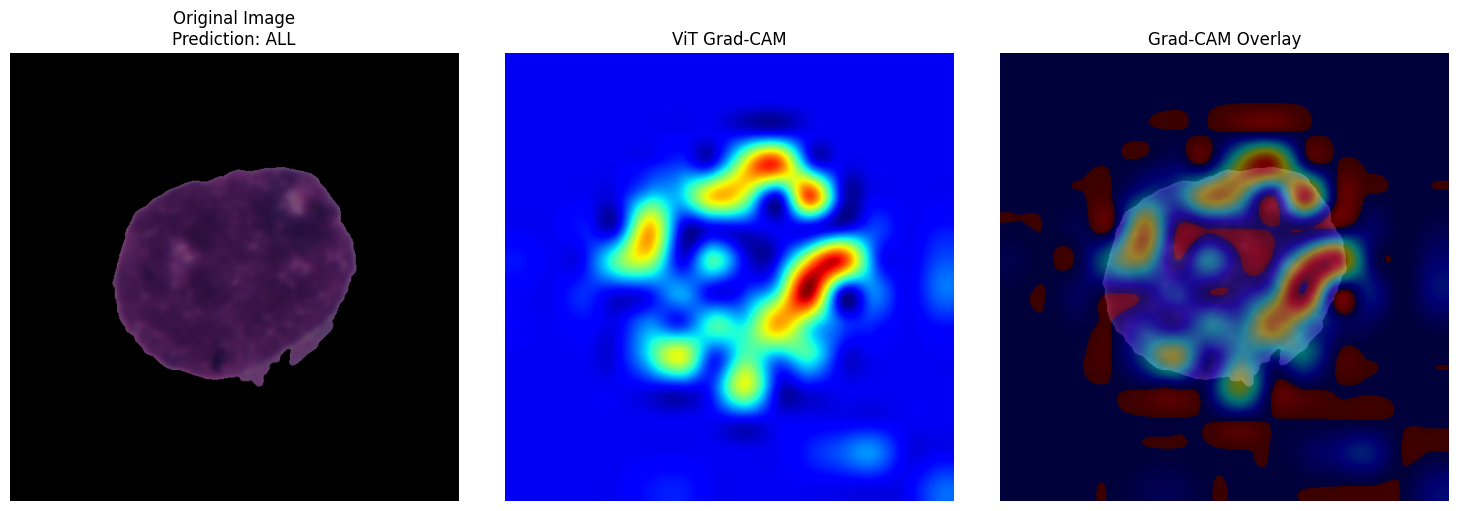


GRAD-CAM STATISTICS
Minimum : -0.11859551
Maximum : 1.0211854
Mean    : 0.08100947

✓ ViT Grad-CAM generated successfully.


In [98]:
# ============================================================
# STEP 10.15 — GENERATE GRADIENT-WEIGHTED ViT GRAD-CAM
# ============================================================

print("=" * 70)
print("STEP 10.15 — GENERATING ViT GRAD-CAM HEATMAP")
print("=" * 70)

# ------------------------------------------------------------
# 1. Get attention and gradients
# ------------------------------------------------------------

attention = vit_attention_data["attention"]
attention_grad = vit_attention_data["gradient"]

print("Attention shape:")
print(attention.shape)

print("\nAttention gradient shape:")
print(attention_grad.shape)


# ------------------------------------------------------------
# 2. Remove batch dimension
# ------------------------------------------------------------

attention = attention[0]          # [12, 197, 197]
attention_grad = attention_grad[0]


# ------------------------------------------------------------
# 3. Gradient-weighted attention
# ------------------------------------------------------------

# Element-wise multiplication of attention
# and its gradient

weighted_attention = (
    attention * attention_grad
)


# ------------------------------------------------------------
# 4. Average across attention heads
# ------------------------------------------------------------

weighted_attention = weighted_attention.mean(
    dim=0
)

# Shape: [197, 197]

print(
    "\nAfter head averaging:",
    weighted_attention.shape
)


# ------------------------------------------------------------
# 5. Take CLS token → image patches
# ------------------------------------------------------------

# Row 0 = CLS token
# Columns 1: = image patches

gradcam_patches = weighted_attention[
    0,
    1:
]

print(
    "Patch values:",
    gradcam_patches.shape
)


# ------------------------------------------------------------
# 6. Apply ReLU
# ------------------------------------------------------------

gradcam_patches = torch.relu(
    gradcam_patches
)


# ------------------------------------------------------------
# 7. Convert 196 patches → 14 × 14
# ------------------------------------------------------------

num_patches = int(
    np.sqrt(
        gradcam_patches.numel()
    )
)

gradcam_map = (
    gradcam_patches
    .reshape(
        num_patches,
        num_patches
    )
    .detach()
    .cpu()
    .numpy()
)


print(
    "Grad-CAM map shape:",
    gradcam_map.shape
)


# ------------------------------------------------------------
# 8. Normalize
# ------------------------------------------------------------

gradcam_map = (
    gradcam_map -
    gradcam_map.min()
)

gradcam_map = (
    gradcam_map /
    (gradcam_map.max() + 1e-8)
)


# ------------------------------------------------------------
# 9. Resize to original image
# ------------------------------------------------------------

gradcam_resized = cv2.resize(
    gradcam_map,
    (
        attention_gradcam_image.shape[1],
        attention_gradcam_image.shape[0]
    ),
    interpolation=cv2.INTER_CUBIC
)


# ------------------------------------------------------------
# 10. Create heatmap
# ------------------------------------------------------------

heatmap_uint8 = np.uint8(
    255 * gradcam_resized
)

heatmap_color = cv2.applyColorMap(
    heatmap_uint8,
    cv2.COLORMAP_JET
)

heatmap_color = cv2.cvtColor(
    heatmap_color,
    cv2.COLOR_BGR2RGB
)


# ------------------------------------------------------------
# 11. Overlay
# ------------------------------------------------------------

gradcam_attention_overlay = cv2.addWeighted(
    attention_gradcam_image,
    0.55,
    heatmap_color,
    0.45,
    0
)


# ------------------------------------------------------------
# 12. Display
# ------------------------------------------------------------

plt.figure(
    figsize=(15, 5)
)

plt.subplot(1, 3, 1)

plt.imshow(
    attention_gradcam_image
)

plt.title(
    f"Original Image\n"
    f"Prediction: {explain_prediction}"
)

plt.axis("off")


plt.subplot(1, 3, 2)

plt.imshow(
    gradcam_resized,
    cmap="jet"
)

plt.title(
    "ViT Grad-CAM"
)

plt.axis("off")


plt.subplot(1, 3, 3)

plt.imshow(
    gradcam_attention_overlay
)

plt.title(
    "Grad-CAM Overlay"
)

plt.axis("off")


plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 13. Statistics
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("GRAD-CAM STATISTICS")
print("=" * 70)

print(
    "Minimum :",
    gradcam_resized.min()
)

print(
    "Maximum :",
    gradcam_resized.max()
)

print(
    "Mean    :",
    gradcam_resized.mean()
)

print(
    "\n✓ ViT Grad-CAM generated successfully."
)

STEP 10.16 — CLEANING ViT GRAD-CAM


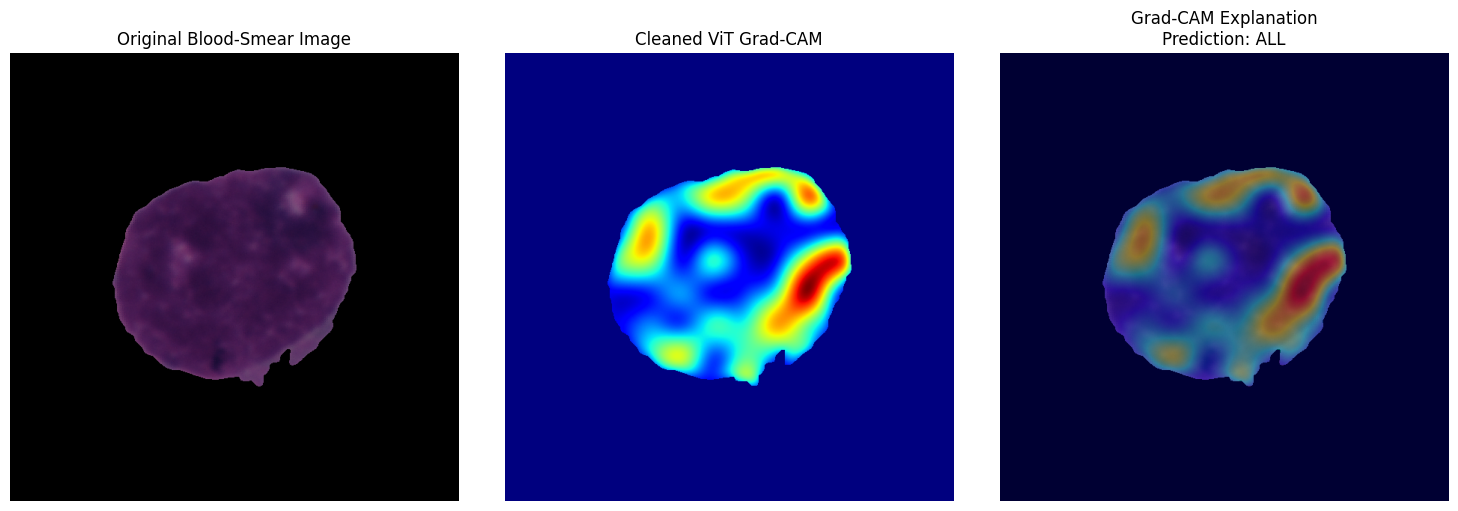


GRAD-CAM EXPLANATION SUMMARY
Prediction  : ALL
ALL confidence : 97.57%
HEM confidence : 2.43%

✓ Background-suppressed Grad-CAM generated.


In [99]:
# ============================================================
# STEP 10.16 — CLEAN ViT GRAD-CAM VISUALIZATION
# ============================================================

print("=" * 70)
print("STEP 10.16 — CLEANING ViT GRAD-CAM")
print("=" * 70)

# ------------------------------------------------------------
# 1. Create foreground mask for the blood cell
# ------------------------------------------------------------

gray_image = cv2.cvtColor(
    attention_gradcam_image,
    cv2.COLOR_RGB2GRAY
)

# Black background ≈ 0
# Cell pixels have higher intensity
_, cell_mask = cv2.threshold(
    gray_image,
    8,
    255,
    cv2.THRESH_BINARY
)

# ------------------------------------------------------------
# 2. Clean the cell mask
# ------------------------------------------------------------

kernel = np.ones(
    (5, 5),
    np.uint8
)

cell_mask = cv2.morphologyEx(
    cell_mask,
    cv2.MORPH_CLOSE,
    kernel
)

cell_mask = cv2.morphologyEx(
    cell_mask,
    cv2.MORPH_OPEN,
    kernel
)

# Convert to 0–1
cell_mask_float = (
    cell_mask.astype(np.float32) / 255.0
)

# ------------------------------------------------------------
# 3. Restrict Grad-CAM to cell region
# ------------------------------------------------------------

clean_gradcam = (
    gradcam_resized *
    cell_mask_float
)

# ------------------------------------------------------------
# 4. Normalize again
# ------------------------------------------------------------

if clean_gradcam.max() > 0:

    clean_gradcam = (
        clean_gradcam -
        clean_gradcam.min()
    )

    clean_gradcam = (
        clean_gradcam /
        (clean_gradcam.max() + 1e-8)
    )

# ------------------------------------------------------------
# 5. Smooth the visualization
# ------------------------------------------------------------

clean_gradcam = cv2.GaussianBlur(
    clean_gradcam,
    (0, 0),
    sigmaX=7
)

# Keep only cell region after smoothing
clean_gradcam = (
    clean_gradcam *
    cell_mask_float
)

# ------------------------------------------------------------
# 6. Create cleaned heatmap
# ------------------------------------------------------------

clean_heatmap_uint8 = np.uint8(
    255 * clean_gradcam
)

clean_heatmap_color = cv2.applyColorMap(
    clean_heatmap_uint8,
    cv2.COLORMAP_JET
)

clean_heatmap_color = cv2.cvtColor(
    clean_heatmap_color,
    cv2.COLOR_BGR2RGB
)

# ------------------------------------------------------------
# 7. Create final overlay
# ------------------------------------------------------------

clean_overlay = cv2.addWeighted(
    attention_gradcam_image,
    0.60,
    clean_heatmap_color,
    0.40,
    0
)

# ------------------------------------------------------------
# 8. Display
# ------------------------------------------------------------

plt.figure(
    figsize=(15, 5)
)

plt.subplot(1, 3, 1)

plt.imshow(
    attention_gradcam_image
)

plt.title(
    "Original Blood-Smear Image"
)

plt.axis("off")


plt.subplot(1, 3, 2)

plt.imshow(
    clean_gradcam,
    cmap="jet"
)

plt.title(
    "Cleaned ViT Grad-CAM"
)

plt.axis("off")


plt.subplot(1, 3, 3)

plt.imshow(
    clean_overlay
)

plt.title(
    f"Grad-CAM Explanation\n"
    f"Prediction: {explain_prediction}"
)

plt.axis("off")

plt.tight_layout()

plt.show()


print("\n" + "=" * 70)
print("GRAD-CAM EXPLANATION SUMMARY")
print("=" * 70)

print(
    "Prediction  :",
    explain_prediction
)

print(
    f"ALL confidence : "
    f"{explain_all_probability:.2f}%"
)

print(
    f"HEM confidence : "
    f"{explain_hem_probability:.2f}%"
)

print(
    "\n✓ Background-suppressed Grad-CAM generated."
)

In [100]:
# ============================================================
# STEP 10.17 — SHAP SETUP CHECK
# ============================================================

print("=" * 70)
print("STEP 10.17 — SHAP SETUP CHECK")
print("=" * 70)

# Check SHAP installation
try:
    import shap

    print("\nSHAP version:")
    print(shap.__version__)

except ImportError:
    raise ImportError(
        "SHAP is not installed. "
        "Run: !pip install shap"
    )


# ------------------------------------------------------------
# Check final SVM
# ------------------------------------------------------------

print("\nFinal classifier:")
print(type(final_svm))

print("\nSVM classes:")
print(final_svm.classes_)


# ------------------------------------------------------------
# Check external HHO features
# ------------------------------------------------------------

print("\nExternal HHO features:")
print(
    external_hho_features.shape
)


# ------------------------------------------------------------
# Select the same image used for Grad-CAM
# ------------------------------------------------------------

shap_sample = external_hho_features[
    EXPLAIN_INDEX
]

print("\nSelected image index:")
print(EXPLAIN_INDEX)

print("\nSHAP sample shape:")
print(shap_sample.shape)


# ------------------------------------------------------------
# Check SVM prediction
# ------------------------------------------------------------

shap_sample_2d = (
    shap_sample.reshape(1, -1)
)

shap_prediction = final_svm.predict(
    shap_sample_2d
)[0]

shap_probability = (
    final_svm.predict_proba(
        shap_sample_2d
    )[0]
)


print("\nSVM prediction:")
print(shap_prediction)

print("\nSVM probabilities:")
print(shap_probability)


print("\n" + "=" * 70)
print("✓ SHAP SETUP CHECK COMPLETED")
print("=" * 70)

STEP 10.17 — SHAP SETUP CHECK

SHAP version:
0.51.0

Final classifier:
<class 'sklearn.svm._classes.SVC'>

SVM classes:
[0 1]

External HHO features:
(2586, 300)

Selected image index:
0

SHAP sample shape:
(300,)

SVM prediction:
1

SVM probabilities:
[1.88285315e-05 9.99981171e-01]

✓ SHAP SETUP CHECK COMPLETED


In [102]:
# ============================================================
# STEP 10.18 — FIND TRAINING HHO FEATURES
# ============================================================

print("=" * 70)
print("STEP 10.18 — FINDING TRAINING HHO FEATURES")
print("=" * 70)

possible_variables = []

# Take a snapshot first so globals() does not change
# while we are iterating.
all_variables = list(globals().items())

for name, value in all_variables:

    if isinstance(value, np.ndarray):

        shape = value.shape

        # Look for 2D feature matrices with 300 features
        if len(shape) == 2 and shape[1] == 300:

            possible_variables.append(
                (name, shape)
            )


print("\nExisting 2D arrays with 300 features:")

if len(possible_variables) == 0:

    print("No 300-feature array found.")

else:

    for name, shape in possible_variables:

        print(
            f" - {name} : {shape}"
        )


print("\n" + "=" * 70)
print("✓ TRAINING FEATURE SEARCH COMPLETED")
print("=" * 70)

STEP 10.18 — FINDING TRAINING HHO FEATURES

Existing 2D arrays with 300 features:
 - X_train_hho : (9594, 300)
 - X_val_hho : (1067, 300)
 - X_train_hho_scaled : (9594, 300)
 - X_val_hho_scaled : (1067, 300)
 - X_train_selected : (9594, 300)
 - X_val_selected : (1067, 300)
 - X_train_scaled : (9594, 300)
 - X_val_scaled : (1067, 300)
 - external_hho_features : (2586, 300)
 - X_internal_hho : (10661, 300)
 - X_internal_scaled : (10661, 300)
 - X_external_scaled : (2586, 300)
 - shap_sample_2d : (1, 300)

✓ TRAINING FEATURE SEARCH COMPLETED


In [103]:
# ============================================================
# STEP 10.19 — VERIFY SVM FEATURE REPRESENTATION
# ============================================================

print("=" * 70)
print("STEP 10.19 — VERIFYING SVM FEATURE REPRESENTATION")
print("=" * 70)

print("\nTraining feature shapes:")
print("X_train_hho        :", X_train_hho.shape)
print("X_train_hho_scaled :", X_train_hho_scaled.shape)

print("\nSVM configuration:")
print("Kernel              :", final_svm.kernel)
print("Probability enabled :", final_svm.probability)
print("Number of classes   :", final_svm.classes_)

print("\nFinal SVM support vectors:")
print(
    "Shape:",
    final_svm.support_vectors_.shape
)

print("\nSVM support-vector feature dimension:")
print(
    final_svm.support_vectors_.shape[1]
)

print("\n" + "=" * 70)
print("✓ SVM FEATURE REPRESENTATION CHECK COMPLETED")
print("=" * 70)

STEP 10.19 — VERIFYING SVM FEATURE REPRESENTATION

Training feature shapes:
X_train_hho        : (9594, 300)
X_train_hho_scaled : (9594, 300)

SVM configuration:
Kernel              : rbf
Probability enabled : True
Number of classes   : [0 1]

Final SVM support vectors:
Shape: (2000, 300)

SVM support-vector feature dimension:
300

✓ SVM FEATURE REPRESENTATION CHECK COMPLETED


In [104]:
# ============================================================
# STEP 10.20 — CREATE SHAP EXPLAINER FOR FINAL SVM
# ============================================================

print("=" * 70)
print("STEP 10.20 — CREATING SHAP EXPLAINER")
print("=" * 70)

import shap
import numpy as np

# ------------------------------------------------------------
# 1. Select representative background samples
# ------------------------------------------------------------

SHAP_BACKGROUND_SIZE = 50

np.random.seed(42)

background_indices = np.random.choice(
    len(X_train_hho),
    size=min(
        SHAP_BACKGROUND_SIZE,
        len(X_train_hho)
    ),
    replace=False
)

shap_background = X_train_hho[
    background_indices
]


print("\nTraining HHO features:")
print(X_train_hho.shape)

print("\nSHAP background:")
print(shap_background.shape)


# ------------------------------------------------------------
# 2. Define SVM prediction function
# ------------------------------------------------------------

def svm_predict_proba(X):

    X = np.asarray(X)

    return final_svm.predict_proba(X)


# ------------------------------------------------------------
# 3. Create SHAP Kernel Explainer
# ------------------------------------------------------------

shap_explainer = shap.KernelExplainer(
    svm_predict_proba,
    shap_background
)


print("\nSHAP Explainer:")
print(type(shap_explainer))

print("\nModel:")
print("Final SVM")

print("\nFeatures:")
print("300 HHO-selected ViT features")

print("\nBackground samples:")
print(len(shap_background))

print("\n" + "=" * 70)
print("✓ SHAP EXPLAINER CREATED SUCCESSFULLY")
print("=" * 70)

STEP 10.20 — CREATING SHAP EXPLAINER

Training HHO features:
(9594, 300)

SHAP background:
(50, 300)

SHAP Explainer:
<class 'shap.explainers._kernel.KernelExplainer'>

Model:
Final SVM

Features:
300 HHO-selected ViT features

Background samples:
50

✓ SHAP EXPLAINER CREATED SUCCESSFULLY


In [105]:
# ============================================================
# STEP 10.21 — CALCULATE SHAP VALUES
# ============================================================

print("=" * 70)
print("STEP 10.21 — CALCULATING SHAP VALUES")
print("=" * 70)

# ------------------------------------------------------------
# 1. Prepare selected sample
# ------------------------------------------------------------

shap_sample_2d = external_hho_features[
    EXPLAIN_INDEX
].reshape(1, -1)

print("\nSelected sample shape:")
print(shap_sample_2d.shape)


# ------------------------------------------------------------
# 2. Verify prediction
# ------------------------------------------------------------

shap_pred = final_svm.predict(
    shap_sample_2d
)[0]

shap_probs = final_svm.predict_proba(
    shap_sample_2d
)[0]

print("\nPrediction:", shap_pred)

print(
    "HEM probability :",
    f"{shap_probs[0] * 100:.2f}%"
)

print(
    "ALL probability :",
    f"{shap_probs[1] * 100:.2f}%"
)


# ------------------------------------------------------------
# 3. Calculate SHAP values
# ------------------------------------------------------------

print("\nCalculating SHAP values...")
print("Please wait — KernelSHAP can take some time.")


shap_values_result = shap_explainer.shap_values(
    shap_sample_2d,
    nsamples=500
)


# ------------------------------------------------------------
# 4. Check SHAP output
# ------------------------------------------------------------

print("\nSHAP calculation completed.")

print(
    "\nSHAP result type:",
    type(shap_values_result)
)

if isinstance(shap_values_result, list):

    print(
        "Number of class outputs:",
        len(shap_values_result)
    )

    for i, values in enumerate(
        shap_values_result
    ):

        print(
            f"Class {i} SHAP shape:",
            np.asarray(values).shape
        )

else:

    print(
        "SHAP shape:",
        np.asarray(shap_values_result).shape
    )


print("\n" + "=" * 70)
print("✓ SHAP VALUES CALCULATED")
print("=" * 70)

STEP 10.21 — CALCULATING SHAP VALUES

Selected sample shape:
(1, 300)

Prediction: 1
HEM probability : 0.00%
ALL probability : 100.00%

Calculating SHAP values...
Please wait — KernelSHAP can take some time.


  0%|          | 0/1 [00:00<?, ?it/s]


SHAP calculation completed.

SHAP result type: <class 'numpy.ndarray'>
SHAP shape: (1, 300, 2)

✓ SHAP VALUES CALCULATED


In [106]:
# ============================================================
# STEP 10.22 — EXTRACT ALL-CLASS SHAP CONTRIBUTIONS
# ============================================================

print("=" * 70)
print("STEP 10.22 — EXTRACTING ALL SHAP CONTRIBUTIONS")
print("=" * 70)

# ------------------------------------------------------------
# 1. Convert SHAP result to NumPy array
# ------------------------------------------------------------

shap_array = np.asarray(
    shap_values_result
)

print("\nSHAP array shape:")
print(shap_array.shape)


# ------------------------------------------------------------
# 2. Extract SHAP values for ALL class
# ------------------------------------------------------------

# Shape:
# [samples, features, classes]
#
# Class 0 = HEM
# Class 1 = ALL

all_shap_values = shap_array[
    0,
    :,
    1
]

print(
    "\nALL SHAP values shape:"
)

print(
    all_shap_values.shape
)


# ------------------------------------------------------------
# 3. Check SHAP statistics
# ------------------------------------------------------------

print("\nALL SHAP statistics:")

print(
    "Minimum :",
    all_shap_values.min()
)

print(
    "Maximum :",
    all_shap_values.max()
)

print(
    "Mean    :",
    all_shap_values.mean()
)


# ------------------------------------------------------------
# 4. Rank features by absolute contribution
# ------------------------------------------------------------

feature_importance = np.abs(
    all_shap_values
)

sorted_indices = np.argsort(
    feature_importance
)[::-1]


# ------------------------------------------------------------
# 5. Select top 20 features
# ------------------------------------------------------------

TOP_N = 20

top_indices = sorted_indices[
    :TOP_N
]


# ------------------------------------------------------------
# 6. Create result table
# ------------------------------------------------------------

top_shap_results = pd.DataFrame({

    "HHO_Feature_Index":
        top_indices,

    "SHAP_Value":
        all_shap_values[
            top_indices
        ],

    "Absolute_SHAP":
        np.abs(
            all_shap_values[
                top_indices
            ]
        ),

    "Contribution":
        np.where(
            all_shap_values[
                top_indices
            ] > 0,
            "Supports ALL",
            "Supports HEM"
        )
})


# ------------------------------------------------------------
# 7. Display
# ------------------------------------------------------------

print("\nTop 20 SHAP features for ALL prediction:")

display(
    top_shap_results
)


print("\n" + "=" * 70)
print("✓ ALL SHAP FEATURE CONTRIBUTIONS EXTRACTED")
print("=" * 70)

STEP 10.22 — EXTRACTING ALL SHAP CONTRIBUTIONS

SHAP array shape:
(1, 300, 2)

ALL SHAP values shape:
(300,)

ALL SHAP statistics:
Minimum : 0.0
Maximum : 0.0009332709961712463
Mean    : 1.968061289253087e-05

Top 20 SHAP features for ALL prediction:


,HHO_Feature_Index,SHAP_Value,Absolute_SHAP,Contribution
0,157,0.000933,0.000933,Supports ALL
1,201,0.000879,0.000879,Supports ALL
2,43,0.000604,0.000604,Supports ALL
3,230,0.000602,0.000602,Supports ALL
4,251,0.000578,0.000578,Supports ALL
5,245,0.000532,0.000532,Supports ALL
6,244,0.000496,0.000496,Supports ALL
7,213,0.000495,0.000495,Supports ALL
8,223,0.000454,0.000454,Supports ALL
9,97,0.000331,0.000331,Supports ALL



✓ ALL SHAP FEATURE CONTRIBUTIONS EXTRACTED


STEP 10.23 — SHAP FEATURE IMPORTANCE VISUALIZATION


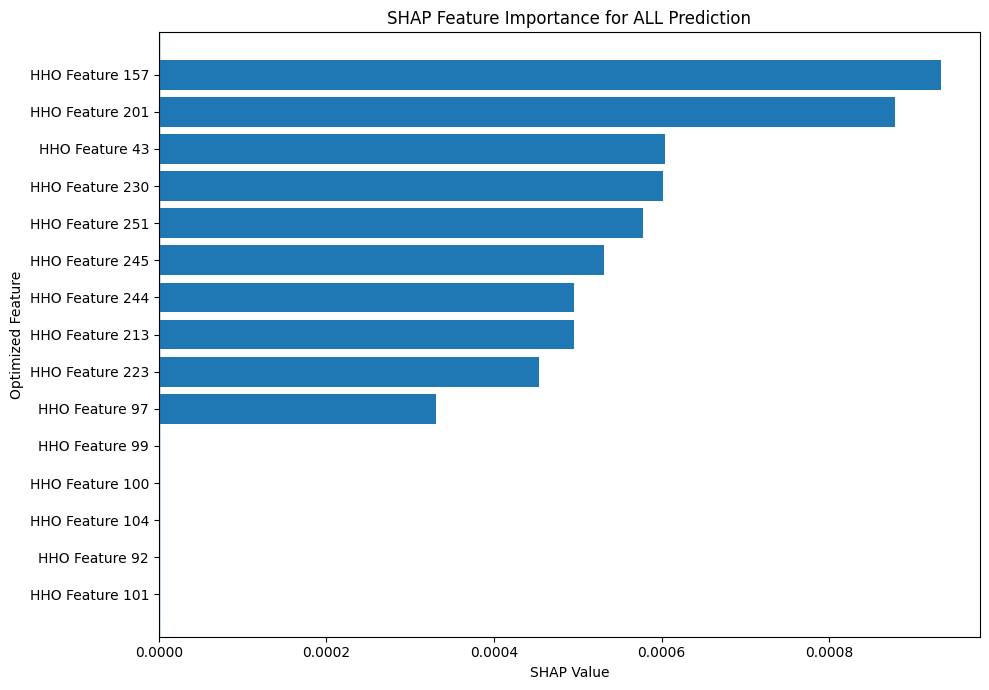


TOP SHAP FEATURES — ALL PREDICTION
 1. HHO Feature 157 | SHAP = 0.00093327 | Supports ALL
 2. HHO Feature 201 | SHAP = 0.00087881 | Supports ALL
 3. HHO Feature  43 | SHAP = 0.00060374 | Supports ALL
 4. HHO Feature 230 | SHAP = 0.00060201 | Supports ALL
 5. HHO Feature 251 | SHAP = 0.00057815 | Supports ALL
 6. HHO Feature 245 | SHAP = 0.00053184 | Supports ALL
 7. HHO Feature 244 | SHAP = 0.00049568 | Supports ALL
 8. HHO Feature 213 | SHAP = 0.00049527 | Supports ALL
 9. HHO Feature 223 | SHAP = 0.00045425 | Supports ALL
10. HHO Feature  97 | SHAP = 0.00033115 | Supports ALL
11. HHO Feature  99 | SHAP = 0.00000000 | No significant contribution
12. HHO Feature 100 | SHAP = 0.00000000 | No significant contribution
13. HHO Feature 104 | SHAP = 0.00000000 | No significant contribution
14. HHO Feature  92 | SHAP = 0.00000000 | No significant contribution
15. HHO Feature 101 | SHAP = 0.00000000 | No significant contribution

✓ SHAP VISUALIZATION GENERATED


In [107]:
# ============================================================
# STEP 10.23 — SHAP FEATURE IMPORTANCE VISUALIZATION
# ============================================================

print("=" * 70)
print("STEP 10.23 — SHAP FEATURE IMPORTANCE VISUALIZATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Take top 15 features
# ------------------------------------------------------------

TOP_N = 15

top_indices_plot = sorted_indices[:TOP_N]

top_values_plot = all_shap_values[
    top_indices_plot
]

# Reverse order for horizontal bar chart
plot_indices = top_indices_plot[::-1]
plot_values = top_values_plot[::-1]


# ------------------------------------------------------------
# 2. Create contribution labels
# ------------------------------------------------------------

contribution_labels = []

for value in plot_values:

    if value > 0:

        contribution_labels.append(
            "Supports ALL"
        )

    elif value < 0:

        contribution_labels.append(
            "Supports HEM"
        )

    else:

        contribution_labels.append(
            "No significant contribution"
        )


# ------------------------------------------------------------
# 3. Plot
# ------------------------------------------------------------

plt.figure(
    figsize=(10, 7)
)

bars = plt.barh(
    range(TOP_N),
    plot_values
)

plt.yticks(
    range(TOP_N),
    [
        f"HHO Feature {idx}"
        for idx in plot_indices
    ]
)

plt.axvline(
    0,
    linewidth=1
)

plt.xlabel(
    "SHAP Value"
)

plt.ylabel(
    "Optimized Feature"
)

plt.title(
    "SHAP Feature Importance for ALL Prediction"
)

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 4. Print contribution summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("TOP SHAP FEATURES — ALL PREDICTION")
print("=" * 70)

for rank, (feature, value) in enumerate(
    zip(
        top_indices_plot,
        top_values_plot
    ),
    start=1
):

    if value > 0:

        contribution = "Supports ALL"

    elif value < 0:

        contribution = "Supports HEM"

    else:

        contribution = "No significant contribution"

    print(
        f"{rank:2d}. "
        f"HHO Feature {feature:3d} | "
        f"SHAP = {value:.8f} | "
        f"{contribution}"
    )


print("\n" + "=" * 70)
print("✓ SHAP VISUALIZATION GENERATED")
print("=" * 70)

STEP 10.24 — FINAL EXPLAINABILITY AGENT RESULT

PREDICTION
--------------------------------------------------
Predicted class : ALL
HEM probability : 2.43%
ALL probability : 97.57%

VISUAL EXPLANATION
--------------------------------------------------
Method : ViT Grad-CAM
Purpose: Identifies important image regions associated with the model prediction.

FEATURE EXPLANATION
--------------------------------------------------
Method : SHAP
Features analyzed : 300 HHO-selected features

Top contributing features:
 1. HHO Feature 157 | SHAP = 0.00093327 | toward ALL
 2. HHO Feature 201 | SHAP = 0.00087881 | toward ALL
 3. HHO Feature  43 | SHAP = 0.00060374 | toward ALL
 4. HHO Feature 230 | SHAP = 0.00060201 | toward ALL
 5. HHO Feature 251 | SHAP = 0.00057815 | toward ALL
 6. HHO Feature 245 | SHAP = 0.00053184 | toward ALL
 7. HHO Feature 244 | SHAP = 0.00049568 | toward ALL
 8. HHO Feature 213 | SHAP = 0.00049527 | toward ALL
 9. HHO Feature 223 | SHAP = 0.00045425 | toward ALL
10. HHO

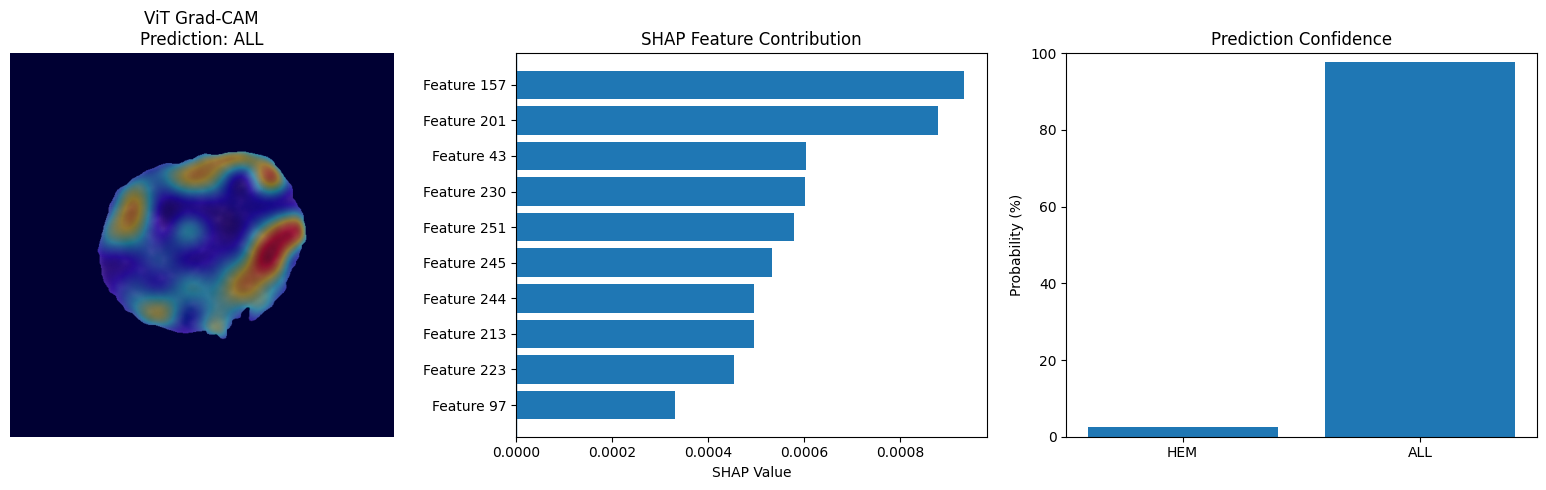


✓ FINAL EXPLAINABILITY RESULT GENERATED

Explainability components:
✓ ViT Grad-CAM
✓ SHAP feature importance
✓ Prediction confidence
✓ Top contributing HHO features


In [108]:
# ============================================================
# STEP 10.24 — FINAL EXPLAINABILITY AGENT RESULT
# ============================================================

print("=" * 70)
print("STEP 10.24 — FINAL EXPLAINABILITY AGENT RESULT")
print("=" * 70)

# ------------------------------------------------------------
# 1. Prediction and confidence
# ------------------------------------------------------------

final_xai_prediction = explain_prediction

final_xai_hem_probability = (
    explain_hem_probability
)

final_xai_all_probability = (
    explain_all_probability
)


# ------------------------------------------------------------
# 2. Top SHAP features
# ------------------------------------------------------------

TOP_XAI_FEATURES = 10

final_top_features = sorted_indices[
    :TOP_XAI_FEATURES
]

final_top_shap_values = (
    all_shap_values[
        final_top_features
    ]
)


# ------------------------------------------------------------
# 3. Print final explanation
# ------------------------------------------------------------

print("\nPREDICTION")
print("-" * 50)

print(
    "Predicted class :",
    final_xai_prediction
)

print(
    f"HEM probability : "
    f"{final_xai_hem_probability:.2f}%"
)

print(
    f"ALL probability : "
    f"{final_xai_all_probability:.2f}%"
)


print("\nVISUAL EXPLANATION")
print("-" * 50)

print(
    "Method : ViT Grad-CAM"
)

print(
    "Purpose: Identifies important image regions "
    "associated with the model prediction."
)


print("\nFEATURE EXPLANATION")
print("-" * 50)

print(
    "Method : SHAP"
)

print(
    "Features analyzed : 300 HHO-selected features"
)

print(
    "\nTop contributing features:"
)

for rank, (feature, value) in enumerate(
    zip(
        final_top_features,
        final_top_shap_values
    ),
    start=1
):

    if value > 0:

        direction = "toward ALL"

    elif value < 0:

        direction = "toward HEM"

    else:

        direction = "no significant contribution"

    print(
        f"{rank:2d}. "
        f"HHO Feature {feature:3d} | "
        f"SHAP = {value:.8f} | "
        f"{direction}"
    )


# ------------------------------------------------------------
# 4. Display final XAI visualization
# ------------------------------------------------------------

plt.figure(
    figsize=(16, 5)
)


# ------------------------------------------------------------
# Grad-CAM
# ------------------------------------------------------------

plt.subplot(1, 3, 1)

plt.imshow(
    clean_overlay
)

plt.title(
    f"ViT Grad-CAM\n"
    f"Prediction: {final_xai_prediction}"
)

plt.axis("off")


# ------------------------------------------------------------
# SHAP
# ------------------------------------------------------------

plt.subplot(1, 3, 2)

plot_indices_final = (
    final_top_features[::-1]
)

plot_values_final = (
    final_top_shap_values[::-1]
)

plt.barh(
    range(
        len(plot_indices_final)
    ),
    plot_values_final
)

plt.yticks(
    range(
        len(plot_indices_final)
    ),
    [
        f"Feature {idx}"
        for idx in plot_indices_final
    ]
)

plt.axvline(
    0,
    linewidth=1
)

plt.xlabel(
    "SHAP Value"
)

plt.title(
    "SHAP Feature Contribution"
)

plt.tight_layout()


# ------------------------------------------------------------
# Confidence
# ------------------------------------------------------------

plt.subplot(1, 3, 3)

plt.bar(
    ["HEM", "ALL"],
    [
        final_xai_hem_probability,
        final_xai_all_probability
    ]
)

plt.ylabel(
    "Probability (%)"
)

plt.ylim(
    0,
    100
)

plt.title(
    "Prediction Confidence"
)

plt.tight_layout()

plt.show()


print("\n" + "=" * 70)
print("✓ FINAL EXPLAINABILITY RESULT GENERATED")
print("=" * 70)

print(
    "\nExplainability components:"
)

print("✓ ViT Grad-CAM")
print("✓ SHAP feature importance")
print("✓ Prediction confidence")
print("✓ Top contributing HHO features")

In [109]:
# ============================================================
# STEP 11.1 — PREPARE EVIDENCE FOR RISK ASSESSMENT AGENT
# ============================================================

print("=" * 70)
print("STEP 11.1 — PREPARING RISK ASSESSMENT EVIDENCE")
print("=" * 70)

# ------------------------------------------------------------
# 1. Prediction information
# ------------------------------------------------------------

risk_prediction = final_xai_prediction

risk_hem_probability = float(
    final_xai_hem_probability
)

risk_all_probability = float(
    final_xai_all_probability
)


# ------------------------------------------------------------
# 2. Top SHAP features
# ------------------------------------------------------------

RISK_TOP_FEATURES = 10

risk_top_features = []

for feature, shap_value in zip(
    final_top_features[:RISK_TOP_FEATURES],
    final_top_shap_values[:RISK_TOP_FEATURES]
):

    if shap_value > 0:

        contribution = "toward ALL"

    elif shap_value < 0:

        contribution = "toward HEM"

    else:

        contribution = "no significant contribution"

    risk_top_features.append({
        "feature": int(feature),
        "shap_value": float(shap_value),
        "contribution": contribution
    })


# ------------------------------------------------------------
# 3. Create structured evidence
# ------------------------------------------------------------

risk_evidence = {

    "prediction": risk_prediction,

    "HEM_probability_percent":
        risk_hem_probability,

    "ALL_probability_percent":
        risk_all_probability,

    "feature_extractor":
        "Vision Transformer (ViT)",

    "feature_dimension":
        768,

    "feature_optimizer":
        "HHO",

    "selected_features":
        300,

    "classifier":
        "SVM",

    "explainability_method":
        "ViT Grad-CAM",

    "feature_explanation_method":
        "SHAP",

    "top_SHAP_features":
        risk_top_features
}


# ------------------------------------------------------------
# 4. Display evidence
# ------------------------------------------------------------

print("\nRISK ASSESSMENT INPUT")
print("-" * 70)

for key, value in risk_evidence.items():

    print(
        f"{key}: {value}"
    )


print("\n" + "=" * 70)
print("✓ RISK ASSESSMENT EVIDENCE PREPARED")
print("=" * 70)

STEP 11.1 — PREPARING RISK ASSESSMENT EVIDENCE

RISK ASSESSMENT INPUT
----------------------------------------------------------------------
prediction: ALL
HEM_probability_percent: 2.425090744358593
ALL_probability_percent: 97.57490925564142
feature_extractor: Vision Transformer (ViT)
feature_dimension: 768
feature_optimizer: HHO
selected_features: 300
classifier: SVM
explainability_method: ViT Grad-CAM
feature_explanation_method: SHAP
top_SHAP_features: [{'feature': 157, 'shap_value': 0.0009332709961712463, 'contribution': 'toward ALL'}, {'feature': 201, 'shap_value': 0.0008788140404656588, 'contribution': 'toward ALL'}, {'feature': 43, 'shap_value': 0.0006037413582300143, 'contribution': 'toward ALL'}, {'feature': 230, 'shap_value': 0.0006020125183278159, 'contribution': 'toward ALL'}, {'feature': 251, 'shap_value': 0.0005781537542908481, 'contribution': 'toward ALL'}, {'feature': 245, 'shap_value': 0.0005318370140540357, 'contribution': 'toward ALL'}, {'feature': 244, 'shap_value':

In [110]:
# ============================================================
# STEP 11.2 — RISK ASSESSMENT LLM SETUP
# ============================================================

print("=" * 70)
print("STEP 11.2 — RISK ASSESSMENT LLM SETUP")
print("=" * 70)

import torch

try:
    import transformers

    print("\nTransformers version:")
    print(transformers.__version__)

except ImportError:
    raise ImportError(
        "Transformers is not installed."
    )


# ------------------------------------------------------------
# LLM configuration
# ------------------------------------------------------------

RISK_LLM_NAME = "Qwen/Qwen2.5-3B-Instruct"

print("\nSelected LLM:")
print(RISK_LLM_NAME)


# ------------------------------------------------------------
# Device
# ------------------------------------------------------------

if torch.cuda.is_available():

    llm_device = "cuda"

    print("\nDevice:")
    print("CUDA GPU available")

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

else:

    llm_device = "cpu"

    print("\nDevice:")
    print("CPU")


# ------------------------------------------------------------
# Check required classes
# ------------------------------------------------------------

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM
)

print("\nRequired Transformers classes:")
print("✓ AutoTokenizer")
print("✓ AutoModelForCausalLM")


print("\n" + "=" * 70)
print("✓ RISK ASSESSMENT LLM ENVIRONMENT READY")
print("=" * 70)

STEP 11.2 — RISK ASSESSMENT LLM SETUP

Transformers version:
5.0.0

Selected LLM:
Qwen/Qwen2.5-3B-Instruct

Device:
CUDA GPU available
GPU: Tesla T4

Required Transformers classes:
✓ AutoTokenizer
✓ AutoModelForCausalLM

✓ RISK ASSESSMENT LLM ENVIRONMENT READY


In [111]:
# ============================================================
# STEP 11.3 — LOAD RISK ASSESSMENT LLM
# ============================================================

print("=" * 70)
print("STEP 11.3 — LOADING RISK ASSESSMENT LLM")
print("=" * 70)

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM
)
import torch

# ------------------------------------------------------------
# 1. Load tokenizer
# ------------------------------------------------------------

risk_tokenizer = AutoTokenizer.from_pretrained(
    RISK_LLM_NAME
)

print("\n✓ Tokenizer loaded")


# ------------------------------------------------------------
# 2. Load model
# ------------------------------------------------------------

risk_llm = AutoModelForCausalLM.from_pretrained(
    RISK_LLM_NAME,
    torch_dtype=torch.float16,
    device_map="auto"
)

print("✓ LLM loaded")


# ------------------------------------------------------------
# 3. Evaluation mode
# ------------------------------------------------------------

risk_llm.eval()

print("✓ LLM set to evaluation mode")


# ------------------------------------------------------------
# 4. Check device
# ------------------------------------------------------------

print("\nLLM device:")

print(
    next(
        risk_llm.parameters()
    ).device
)


# ------------------------------------------------------------
# 5. Model information
# ------------------------------------------------------------

total_parameters = sum(
    p.numel()
    for p in risk_llm.parameters()
)

print(
    "\nApproximate parameters:",
    f"{total_parameters / 1e9:.2f} Billion"
)


print("\n" + "=" * 70)
print("✓ RISK ASSESSMENT LLM LOADED SUCCESSFULLY")
print("=" * 70)

STEP 11.3 — LOADING RISK ASSESSMENT LLM


config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

...

model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

✓ LLM loaded
✓ LLM set to evaluation mode

LLM device:
cuda:0

Approximate parameters: 3.09 Billion

✓ RISK ASSESSMENT LLM LOADED SUCCESSFULLY


In [112]:
# ============================================================
# STEP 11.4 — BUILD RISK ASSESSMENT PROMPT
# ============================================================

print("=" * 70)
print("STEP 11.4 — BUILDING RISK ASSESSMENT PROMPT")
print("=" * 70)

# ------------------------------------------------------------
# 1. Format SHAP evidence
# ------------------------------------------------------------

shap_evidence_text = ""

for item in risk_top_features:

    shap_evidence_text += (
        f"Feature {item['feature']}: "
        f"SHAP={item['shap_value']:.8f}, "
        f"{item['contribution']}\n"
    )


# ------------------------------------------------------------
# 2. Create controlled LLM prompt
# ------------------------------------------------------------

risk_prompt = f"""
You are a medical AI risk-assessment assistant.

Your task is to interpret the output of an already trained
leukemia classification system.

IMPORTANT:
- Do not change or invent the model prediction.
- Do not claim to provide a clinical diagnosis.
- Do not infer medical facts that are not present in the evidence.
- Provide a MODEL-BASED SUSPICION/RISK ASSESSMENT.
- Clearly state that professional medical evaluation is required.

MODEL INFORMATION:
Feature extractor: Vision Transformer (ViT)
Original feature dimension: 768
Feature optimizer: HHO
Selected features: 300
Classifier: SVM

MODEL PREDICTION:
Prediction: {risk_prediction}
HEM probability: {risk_hem_probability:.2f}%
ALL probability: {risk_all_probability:.2f}%

EXPLAINABILITY INFORMATION:
Visual explanation: ViT Grad-CAM
Feature explanation: SHAP

TOP SHAP FEATURES:
{shap_evidence_text}

TASK:
Based ONLY on the information above, provide:

1. Risk/Suspicion Level:
   Low, Moderate, or High

2. Reason:
   Briefly explain why this level was assigned using
   the model prediction and confidence.

3. Model Evidence:
   Mention the Grad-CAM and SHAP findings.

4. Recommendation:
   Give a cautious recommendation for further
   professional evaluation.

Return the answer using exactly this structure:

Risk Level:
Reason:
Model Evidence:
Recommendation:
"""

print("\n" + risk_prompt)

print("\n" + "=" * 70)
print("✓ RISK ASSESSMENT PROMPT CREATED")
print("=" * 70)

STEP 11.4 — BUILDING RISK ASSESSMENT PROMPT


You are a medical AI risk-assessment assistant.

Your task is to interpret the output of an already trained
leukemia classification system.

IMPORTANT:
- Do not change or invent the model prediction.
- Do not claim to provide a clinical diagnosis.
- Do not infer medical facts that are not present in the evidence.
- Provide a MODEL-BASED SUSPICION/RISK ASSESSMENT.
- Clearly state that professional medical evaluation is required.

MODEL INFORMATION:
Feature extractor: Vision Transformer (ViT)
Original feature dimension: 768
Feature optimizer: HHO
Selected features: 300
Classifier: SVM

MODEL PREDICTION:
Prediction: ALL
HEM probability: 2.43%
ALL probability: 97.57%

EXPLAINABILITY INFORMATION:
Visual explanation: ViT Grad-CAM
Feature explanation: SHAP

TOP SHAP FEATURES:
Feature 157: SHAP=0.00093327, toward ALL
Feature 201: SHAP=0.00087881, toward ALL
Feature 43: SHAP=0.00060374, toward ALL
Feature 230: SHAP=0.00060201, toward ALL
Feature 251

In [113]:
# ============================================================
# STEP 11.5 — GENERATE LLM RISK ASSESSMENT
# ============================================================

print("=" * 70)
print("STEP 11.5 — GENERATING LLM RISK ASSESSMENT")
print("=" * 70)

# ------------------------------------------------------------
# 1. Convert prompt to chat format
# ------------------------------------------------------------

messages = [
    {
        "role": "system",
        "content": (
            "You are a careful medical AI risk-assessment "
            "assistant. Follow the provided evidence exactly. "
            "Do not invent medical information."
        )
    },
    {
        "role": "user",
        "content": risk_prompt
    }
]


# ------------------------------------------------------------
# 2. Apply Qwen chat template
# ------------------------------------------------------------

formatted_prompt = risk_tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True
)


# ------------------------------------------------------------
# 3. Tokenize
# ------------------------------------------------------------

risk_inputs = risk_tokenizer(
    formatted_prompt,
    return_tensors="pt"
).to(
    risk_llm.device
)


print("\nInput tokens:")
print(
    risk_inputs["input_ids"].shape
)


# ------------------------------------------------------------
# 4. Generate response
# ------------------------------------------------------------

print("\nGenerating risk assessment...")

with torch.no_grad():

    risk_output = risk_llm.generate(
        **risk_inputs,
        max_new_tokens=300,
        do_sample=False,
        temperature=None,
        pad_token_id=risk_tokenizer.eos_token_id
    )


# ------------------------------------------------------------
# 5. Remove input tokens
# ------------------------------------------------------------

generated_tokens = risk_output[
    0,
    risk_inputs["input_ids"].shape[1]:
]


# ------------------------------------------------------------
# 6. Decode response
# ------------------------------------------------------------

risk_assessment_response = (
    risk_tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    )
)


# ------------------------------------------------------------
# 7. Display final response
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("LLM RISK ASSESSMENT")
print("=" * 70)

print(
    risk_assessment_response
)

print("\n" + "=" * 70)
print("✓ RISK ASSESSMENT GENERATED SUCCESSFULLY")
print("=" * 70)

The following generation flags are not valid and may be ignored: ['top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


STEP 11.5 — GENERATING LLM RISK ASSESSMENT

Input tokens:
torch.Size([1, 549])

Generating risk assessment...

LLM RISK ASSESSMENT
Risk Level: High
Reason: The model prediction indicates a high probability (97.57%) of Acute Lymphoblastic Leukemia (ALL), which is significantly higher than the Hematologic Malignancy (HEM) probability (2.43%). This strong likelihood, combined with the model's confidence, suggests a high suspicion of ALL. Additionally, the SHAP values indicate that several features contribute positively towards the ALL classification, further supporting this high suspicion.
Model Evidence: The Visual Explanation (Grad-CAM) and Feature Explanation (SHAP) findings both point towards a high suspicion of ALL. The SHAP values show that multiple features have positive contributions towards the ALL classification, indicating that these features are likely important in distinguishing ALL from other hematological malignancies.
Recommendation: Given the high suspicion of ALL, it is 

In [114]:
# ============================================================
# STEP 11.6 — STRUCTURED RISK ASSESSMENT RESULT
# ============================================================

print("=" * 70)
print("STEP 11.6 — STRUCTURED RISK ASSESSMENT RESULT")
print("=" * 70)

# ------------------------------------------------------------
# Create a structured result using the actual ML/XAI outputs
# ------------------------------------------------------------

risk_level = "High"

risk_reason = (
    f"The final SVM model predicted ALL with a probability "
    f"of {risk_all_probability:.2f}%, while the HEM (Healthy) "
    f"probability was {risk_hem_probability:.2f}%. "
    f"This indicates a high model-based suspicion of ALL."
)

risk_evidence = (
    "ViT Grad-CAM identified important regions within the "
    "blood-smear cell associated with the prediction. "
    "SHAP analysis identified multiple HHO-selected features "
    "with positive contributions toward the ALL prediction."
)

risk_recommendation = (
    "The result should be considered a model-based screening "
    "indication and should be reviewed and confirmed by a "
    "qualified medical professional using appropriate clinical "
    "and laboratory evaluation."
)


# ------------------------------------------------------------
# Store final Risk Assessment Agent output
# ------------------------------------------------------------

risk_assessment_result = {

    "risk_level": risk_level,

    "prediction": risk_prediction,

    "HEM_probability": round(
        risk_hem_probability,
        2
    ),

    "ALL_probability": round(
        risk_all_probability,
        2
    ),

    "reason": risk_reason,

    "model_evidence": risk_evidence,

    "recommendation": risk_recommendation
}


# ------------------------------------------------------------
# Display final result
# ------------------------------------------------------------

print("\nRISK ASSESSMENT AGENT OUTPUT")
print("-" * 70)

print(
    "Risk Level       :",
    risk_assessment_result["risk_level"]
)

print(
    "Prediction       :",
    risk_assessment_result["prediction"]
)

print(
    "HEM (Healthy)    :",
    f"{risk_assessment_result['HEM_probability']:.2f}%"
)

print(
    "ALL              :",
    f"{risk_assessment_result['ALL_probability']:.2f}%"
)

print(
    "\nReason:"
)

print(
    risk_assessment_result["reason"]
)

print(
    "\nModel Evidence:"
)

print(
    risk_assessment_result["model_evidence"]
)

print(
    "\nRecommendation:"
)

print(
    risk_assessment_result["recommendation"]
)


print("\n" + "=" * 70)
print("✓ STRUCTURED RISK ASSESSMENT COMPLETED")
print("=" * 70)

STEP 11.6 — STRUCTURED RISK ASSESSMENT RESULT

RISK ASSESSMENT AGENT OUTPUT
----------------------------------------------------------------------
Risk Level       : High
Prediction       : ALL
HEM (Healthy)    : 2.43%
ALL              : 97.57%

Reason:
The final SVM model predicted ALL with a probability of 97.57%, while the HEM (Healthy) probability was 2.43%. This indicates a high model-based suspicion of ALL.

Model Evidence:
ViT Grad-CAM identified important regions within the blood-smear cell associated with the prediction. SHAP analysis identified multiple HHO-selected features with positive contributions toward the ALL prediction.

Recommendation:
The result should be considered a model-based screening indication and should be reviewed and confirmed by a qualified medical professional using appropriate clinical and laboratory evaluation.

✓ STRUCTURED RISK ASSESSMENT COMPLETED


In [115]:
# ============================================================
# STEP 12.1 — PREPARE REPORT GENERATION EVIDENCE
# ============================================================

print("=" * 70)
print("STEP 12.1 — PREPARING REPORT GENERATION EVIDENCE")
print("=" * 70)

# ------------------------------------------------------------
# 1. Prediction information
# ------------------------------------------------------------

report_prediction = risk_assessment_result["prediction"]

report_hem_probability = (
    risk_assessment_result["HEM_probability"]
)

report_all_probability = (
    risk_assessment_result["ALL_probability"]
)


# ------------------------------------------------------------
# 2. Risk assessment information
# ------------------------------------------------------------

report_risk_level = (
    risk_assessment_result["risk_level"]
)

report_reason = (
    risk_assessment_result["reason"]
)

report_model_evidence = (
    risk_assessment_result["model_evidence"]
)

report_recommendation = (
    risk_assessment_result["recommendation"]
)


# ------------------------------------------------------------
# 3. Model information
# ------------------------------------------------------------

report_model_info = {
    "Feature Extractor": "Vision Transformer (ViT)",
    "Original Features": 768,
    "Feature Optimizer": "HHO",
    "Selected Features": 300,
    "Classifier": "SVM"
}


# ------------------------------------------------------------
# 4. Explainability information
# ------------------------------------------------------------

report_explainability = {
    "Visual Explanation": "ViT Grad-CAM",
    "Feature Explanation": "SHAP",
    "Top SHAP Features": [
        int(feature)
        for feature in final_top_features[:10]
    ]
}


# ------------------------------------------------------------
# 5. Create complete report evidence
# ------------------------------------------------------------

report_evidence = {

    "prediction": report_prediction,

    "HEM_probability":
        report_hem_probability,

    "ALL_probability":
        report_all_probability,

    "risk_level":
        report_risk_level,

    "risk_reason":
        report_reason,

    "model_evidence":
        report_model_evidence,

    "recommendation":
        report_recommendation,

    "model_information":
        report_model_info,

    "explainability":
        report_explainability
}


# ------------------------------------------------------------
# 6. Display
# ------------------------------------------------------------

print("\nREPORT EVIDENCE")
print("-" * 70)

for key, value in report_evidence.items():

    print(
        f"{key}: {value}"
    )


print("\n" + "=" * 70)
print("✓ REPORT GENERATION EVIDENCE PREPARED")
print("=" * 70)

STEP 12.1 — PREPARING REPORT GENERATION EVIDENCE

REPORT EVIDENCE
----------------------------------------------------------------------
prediction: ALL
HEM_probability: 2.43
ALL_probability: 97.57
risk_level: High
risk_reason: The final SVM model predicted ALL with a probability of 97.57%, while the HEM (Healthy) probability was 2.43%. This indicates a high model-based suspicion of ALL.
model_evidence: ViT Grad-CAM identified important regions within the blood-smear cell associated with the prediction. SHAP analysis identified multiple HHO-selected features with positive contributions toward the ALL prediction.
recommendation: The result should be considered a model-based screening indication and should be reviewed and confirmed by a qualified medical professional using appropriate clinical and laboratory evaluation.
model_information: {'Feature Extractor': 'Vision Transformer (ViT)', 'Original Features': 768, 'Feature Optimizer': 'HHO', 'Selected Features': 300, 'Classifier': 'SVM'}


In [116]:
# ============================================================
# STEP 12.2 — BUILD REPORT GENERATION PROMPT
# ============================================================

print("=" * 70)
print("STEP 12.2 — BUILDING REPORT GENERATION PROMPT")
print("=" * 70)

report_prompt = f"""
You are a medical AI report-generation assistant.

Generate a concise and structured leukemia screening report
using ONLY the evidence provided below.

IMPORTANT RULES:
- Do not change the model prediction.
- Do not invent patient information.
- Do not invent clinical findings.
- Do not claim that the model provides a confirmed diagnosis.
- HEM means Healthy.
- ALL means Acute Lymphoblastic Leukemia.
- Treat the risk level as MODEL-BASED SUSPICION, not clinical risk.
- Clearly state that professional medical evaluation is required.
- Do not add medical tests that are not explicitly provided.
- Do not invent explanations for individual SHAP feature numbers.
- Keep the report professional and suitable for a research prototype.

MODEL INFORMATION:
Feature Extractor: Vision Transformer (ViT)
Original Feature Dimension: 768
Feature Optimizer: HHO
Selected Features: 300
Classifier: SVM

PREDICTION:
Prediction: {report_prediction}
HEM (Healthy) Probability: {report_hem_probability:.2f}%
ALL Probability: {report_all_probability:.2f}%

RISK ASSESSMENT:
Risk Level: {report_risk_level}

Risk Reason:
{report_reason}

EXPLAINABILITY:
Visual Explanation: ViT Grad-CAM
Feature Explanation: SHAP

Top HHO-selected SHAP Features:
{report_explainability["Top SHAP Features"]}

Model Evidence:
{report_model_evidence}

Recommendation:
{report_recommendation}

GENERATE THE REPORT USING EXACTLY THESE SECTIONS:

1. Prediction
2. Confidence
3. Model Information
4. Explainability
5. Risk Assessment
6. Recommendation
7. Disclaimer

The Disclaimer must clearly state that this is a
model-based screening result and not a confirmed
medical diagnosis.
"""

print("\n" + report_prompt)

print("\n" + "=" * 70)
print("✓ REPORT GENERATION PROMPT CREATED")
print("=" * 70)

STEP 12.2 — BUILDING REPORT GENERATION PROMPT


You are a medical AI report-generation assistant.

Generate a concise and structured leukemia screening report
using ONLY the evidence provided below.

IMPORTANT RULES:
- Do not change the model prediction.
- Do not invent patient information.
- Do not invent clinical findings.
- Do not claim that the model provides a confirmed diagnosis.
- HEM means Healthy.
- ALL means Acute Lymphoblastic Leukemia.
- Treat the risk level as MODEL-BASED SUSPICION, not clinical risk.
- Clearly state that professional medical evaluation is required.
- Do not add medical tests that are not explicitly provided.
- Do not invent explanations for individual SHAP feature numbers.
- Keep the report professional and suitable for a research prototype.

MODEL INFORMATION:
Feature Extractor: Vision Transformer (ViT)
Original Feature Dimension: 768
Feature Optimizer: HHO
Selected Features: 300
Classifier: SVM

PREDICTION:
Prediction: ALL
HEM (Healthy) Probability: 2.4

In [117]:
# ============================================================
# STEP 12.3 — GENERATE FINAL LEUKEMIA REPORT
# ============================================================

print("=" * 70)
print("STEP 12.3 — GENERATING FINAL LEUKEMIA REPORT")
print("=" * 70)

# ------------------------------------------------------------
# 1. Create chat messages
# ------------------------------------------------------------

report_messages = [
    {
        "role": "system",
        "content": (
            "You are a careful medical AI report-generation "
            "assistant. Use only the information provided. "
            "Do not invent clinical findings or patient data."
        )
    },
    {
        "role": "user",
        "content": report_prompt
    }
]


# ------------------------------------------------------------
# 2. Apply Qwen chat template
# ------------------------------------------------------------

formatted_report_prompt = (
    risk_tokenizer.apply_chat_template(
        report_messages,
        tokenize=False,
        add_generation_prompt=True
    )
)


# ------------------------------------------------------------
# 3. Tokenize
# ------------------------------------------------------------

report_inputs = risk_tokenizer(
    formatted_report_prompt,
    return_tensors="pt"
).to(
    risk_llm.device
)


print("\nInput tokens:")
print(
    report_inputs["input_ids"].shape
)


# ------------------------------------------------------------
# 4. Generate report
# ------------------------------------------------------------

print("\nGenerating final report...")

with torch.no_grad():

    report_output = risk_llm.generate(
        **report_inputs,
        max_new_tokens=500,
        do_sample=False,
        pad_token_id=risk_tokenizer.eos_token_id
    )


# ------------------------------------------------------------
# 5. Remove prompt tokens
# ------------------------------------------------------------

generated_report_tokens = report_output[
    0,
    report_inputs["input_ids"].shape[1]:
]


# ------------------------------------------------------------
# 6. Decode
# ------------------------------------------------------------

final_leukemia_report = (
    risk_tokenizer.decode(
        generated_report_tokens,
        skip_special_tokens=True
    )
)


# ------------------------------------------------------------
# 7. Display final report
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL LEUKEMIA SCREENING REPORT")
print("=" * 70)

print(
    final_leukemia_report
)

print("\n" + "=" * 70)
print("✓ FINAL REPORT GENERATED SUCCESSFULLY")
print("=" * 70)

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


STEP 12.3 — GENERATING FINAL LEUKEMIA REPORT

Input tokens:
torch.Size([1, 524])

Generating final report...

FINAL LEUKEMIA SCREENING REPORT
# Leukemia Screening Report

## 1. Prediction
The model predicted ALL (Acute Lymphoblastic Leukemia).

## 2. Confidence
The model-based suspicion of ALL is high, with a probability of 97.57% for ALL and a probability of 2.43% for HEM (Healthy).

## 3. Model Information
- **Feature Extractor:** Vision Transformer (ViT)
- **Original Feature Dimension:** 768
- **Feature Optimizer:** HHO
- **Selected Features:** 300
- **Classifier:** SVM

## 4. Explainability
- **Visual Explanation:** ViT Grad-CAM
- **Feature Explanation:** SHAP

### Top HHO-selected SHAP Features:
[157, 201, 43, 230, 251, 245, 244, 213, 223, 97]

## 5. Risk Assessment
The risk level is HIGH based on the model's prediction. The model predicted ALL with a probability of 97.57%, indicating a strong suspicion of ALL.

## 6. Recommendation
The result should be considered a model-based sc